# CSC173 Fine-Tuning a Pretrained CNN
## Group activity notebook: feature extraction, fine-tuning, and a class-wide experiment

In Lecture 03 you used **MobileNetV2** as a frozen feature extractor. Today your group goes one step further and **fine-tunes** it: you unfreeze part of the pretrained network and keep training it, very gently, on a new dataset. Part 3 is a **challenge: the group with the best test accuracy gets a perfect score.** Everything runs on the **TensorFlow Flowers** dataset: 3,670 color photos of 5 kinds of flowers.

By the end of the period your group should be able to:

1. explain **transfer learning**: what is reused, what is trained, and why it works with little data;
2. choose an **optimizer** and a learning rate, and defend the choice;
3. **read training and validation loss curves** and say whether a model underfits, fits well, overfits or diverges;
4. **recognize overfitting** and name two ways to stop it;
5. **interpret a confusion matrix**: which classes get mixed up, and the precision and recall of a class.

| Part | What happens | Clock (60 min) |
|---|---|---|
| 0–1 | Set up, roles, and the data (all code given: just run it) | 0:00–0:07 |
| 2 | Transfer learning: a frozen MobileNetV2, an **optimizer race**, and **overfitting on purpose** | 0:07–0:22 |
| 3 | 🏆 The **fine-tuning challenge**: tune your own recipe | 0:22–0:40 |
| 4 | Your official test score and the **confusion matrix** | 0:40–0:48 |
| 5 | Leaderboard reveal and a **curve-reading gallery** | 0:48–0:60 |

The Experimenter keeps time. If your group falls behind, skip the ✍️ written answers and come back to them while the next model trains: every training cell gives you a minute or two of waiting.

**How to work:** one notebook per group. Fill in every `# TODO`, run the cells from top to bottom, and answer every ✍️ question in the cell below it. There are only **8 TODO cells**, each a few short lines, and each one prints a `Check:` line that should say `True`. Use a GPU: *Runtime → Change runtime type → T4 GPU* **before** class starts the clock. With a GPU every training cell takes 1 to 2 minutes.

---
## 0. Set up

### 0a. Group roles

Pick one role each before you touch the code. Everyone must be able to explain every cell, but each role owns one job.

| Role | Owns | During the activity |
|---|---|---|
| **Driver** | the keyboard | Types the code and runs the cells. Shares the screen so everyone can see. Does **not** decide alone. |
| **Navigator** | the instructions and the Checks | Reads each step aloud, catches bugs, makes sure every `Check:` says `True` before the group moves on. Leads Part 1. |
| **Experimenter** | the challenge strategy | Leads the group's **plan before each trial** in Part 3, watches the clock, and keeps the trial log. |
| **Reporter** | the answers and the share-out | Types the ✍️ answers, posts the group's results line to the leaderboard, and gives the 45-second share-out in Part 5. |

Groups of 3: the Experimenter is also the Reporter. Groups of 5: two Navigators, one of whom keeps a written log of every error and how you fixed it.

In [1]:
GROUP = 6                     # TODO: your group number from the board (1, 2, 3, ...)
MEMBERS = {                   # TODO: your names
    "Driver":       "Kim Gabriel A. Nasayao",
    "Navigator":    "Sam Alexis G. Huertas",
    "Experimenter": "Aeron Jay C. Dale",
    "Reporter":     "Aeron Jay C. Dale",
}
print(f"Group {GROUP}:", ", ".join(f"{r} {n}" for r, n in MEMBERS.items() if n))
print("Check:", GROUP > 0 and all(MEMBERS[r] for r in ["Driver", "Navigator", "Experimenter"]))

Group 6: Driver Kim Gabriel A. Nasayao, Navigator Sam Alexis G. Huertas, Experimenter Aeron Jay C. Dale, Reporter Aeron Jay C. Dale
Check: True


### 0b. Libraries and the GPU

In [2]:
import os, time, pathlib, tarfile
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 173
keras.utils.set_random_seed(SEED)      # same random numbers every run, so results are repeatable
print("TensorFlow", tf.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPU:", gpus if gpus else "none. Use Runtime → Change runtime type → T4 GPU, or training will take about 10 times longer.")

def plot_history(histories, metric="accuracy", title=None, ax=None, boundary=None):
    # Plot training (solid) and validation (dashed) curves for one or more {name: history-dict}.
    ax = ax or plt.gca()
    for (name, h), color in zip(histories.items(), plt.cm.tab10.colors):
        epochs = np.arange(1, len(h[metric]) + 1)
        ax.plot(epochs, h[metric], color=color, label=f"{name} train")
        ax.plot(epochs, h["val_" + metric], "--", color=color, label=f"{name} val")
    if boundary:
        ax.axvline(boundary + 0.5, color="k", ls=":", lw=1)
        ax.text(boundary + 0.6, ax.get_ylim()[0], " fine-tuning starts", fontsize=8, va="bottom")
    ax.set_xlabel("epoch"); ax.set_ylabel(metric); ax.legend(fontsize=8); ax.grid(alpha=.3)
    if title: ax.set_title(title)

TensorFlow 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


---
## 1. The data

*Navigator leads Parts 1 and 2.* The dataset is one folder per class. We download it once (about 220 MB, under a minute on Colab).

In [3]:
URL = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
archive = keras.utils.get_file("flower_photos.tgz", origin=URL)
data_dir = pathlib.Path("flower_photos")
if not data_dir.exists():
    with tarfile.open(archive) as tar:
        tar.extractall(".")

class_names = sorted(d.name for d in data_dir.iterdir() if d.is_dir())
paths, labels = [], []
for c, name in enumerate(class_names):
    files = sorted((data_dir / name).glob("*.jpg"))
    paths += [str(f) for f in files]
    labels += [c] * len(files)
paths, labels = np.array(paths), np.array(labels)
NUM_CLASSES = len(class_names)
print("classes:", class_names)
print("images per class:", np.bincount(labels), " total:", len(paths))

classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
images per class: [633 898 641 699 799]  total: 3670


### 1a. A stratified split

Given code, exactly as in Lecture 04: shuffle each class separately, then give **15% of every class** to validation, **15%** to the test set, and the rest (70%) to training. The test set is locked away until Part 4.

In [4]:
def stratified_split(labels, val_frac=0.15, test_frac=0.15, seed=SEED):
    # Return (train_idx, val_idx, test_idx), each class split in the same proportions.
    rng = np.random.default_rng(seed)
    train_idx, val_idx, test_idx = [], [], []
    for c in np.unique(labels):
        idx = np.where(labels == c)[0]
        rng.shuffle(idx)
        n_val, n_test = int(round(val_frac * len(idx))), int(round(test_frac * len(idx)))
        val_idx.append(idx[:n_val])
        test_idx.append(idx[n_val:n_val + n_test])
        train_idx.append(idx[n_val + n_test:])
    out = [np.concatenate(s) for s in (train_idx, val_idx, test_idx)]
    for s in out:
        rng.shuffle(s)
    return out

tr_idx, va_idx, te_idx = stratified_split(labels)
print("train / val / test sizes:", len(tr_idx), len(va_idx), len(te_idx))
print("val images per class:", np.bincount(labels[va_idx]))
no_overlap = len(set(tr_idx) | set(va_idx) | set(te_idx)) == len(paths)
print("Check:", no_overlap and len(va_idx) == 551 and len(te_idx) == 551)

train / val / test sizes: 2568 551 551
val images per class: [ 95 135  96 105 120]
Check: True


### 1b. Input pipelines

This cell is given. It reads each JPEG, resizes it to **160×160**, and batches 32 images at a time. Pixels stay in 0 to 255 here; the model rescales them itself.

W0000 00:00:1795709565.776633    1143 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.


one batch: (32, 160, 160, 3) <dtype: 'float32'>  labels: [4 1 2 0 1 3 4 2 2 1]


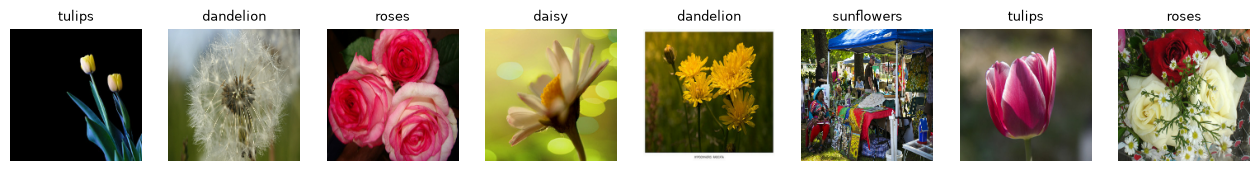

In [5]:
IMG_SIZE = (160, 160)
BATCH = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    img = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    return tf.cast(img, tf.uint8), label            # uint8 keeps the cache small

def make_ds(idx, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((paths[idx], labels[idx]))
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE).cache()
    if shuffle:
        ds = ds.shuffle(len(idx), seed=SEED)
    return ds.batch(BATCH).map(lambda x, y: (tf.cast(x, tf.float32), y)).prefetch(AUTOTUNE)

train_ds = make_ds(tr_idx, shuffle=True)
val_ds   = make_ds(va_idx)
test_ds  = make_ds(te_idx)

xb, yb = next(iter(train_ds))
print("one batch:", xb.shape, xb.dtype, " labels:", yb[:10].numpy())
fig, axes = plt.subplots(1, 8, figsize=(16, 2.6))
for ax, img, y in zip(axes, xb[:8], yb[:8]):
    ax.imshow(img.numpy().astype("uint8")); ax.set_title(class_names[int(y)], fontsize=9); ax.axis("off")
plt.show()

✍️ **Question 1.** (a) What accuracy would a model get by always predicting the largest class? That is the baseline every result today must beat. (b) Why must the test set stay locked until Part 4, even though we already have a validation set?

*Your answer:*
(a) Always predicting dandelion gives 24.47% accuracy across the full dataset. It correctly classifies the 898 dandelion photos out of 3,670 total photos. Dataset class counts

(b) We use the validation set to fine tune models like a recipe. We keep the test set locked so that the final score measures how well the selected model performs on photos that influenced none of our choices. If we used test accuracy to pick a recipe, we could pick one that happened to do well on those particular photos.

---
## 2. Stage 1: feature extraction

MobileNetV2 was trained on 1.4 million ImageNet photos. We keep its convolutional **base**, throw away its 1,000-class head, and put a new head for our 5 classes on top.

```
input 160×160×3 → augmentation → rescale to [−1, 1] → MobileNetV2 base (frozen) → global average pool → dropout → Dense(5, softmax)
```

### 2a. Build the model

In [6]:
augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name="augmentation")

def build_model(pretrained=True):
    # Return (model, base). pretrained=False gives the same network with random weights.
    base = keras.applications.MobileNetV2(input_shape=IMG_SIZE + (3,), include_top=False,
                                          weights="imagenet" if pretrained else None)
    base.trainable = False        # TODO: freeze the whole base (True or False?)
    inputs = keras.Input(IMG_SIZE + (3,))
    x = augment(inputs)
    x = layers.Rescaling(1 / 127.5, offset=-1)(x)       # MobileNetV2 expects pixels in [−1, 1]
    # training=False keeps the base's BatchNorm layers in inference mode, even later when we unfreeze them.
    # A network trained from scratch needs its BatchNorm statistics to learn, so it gets training=None.
    x = base(x, training=False if pretrained else None)
    x = layers.GlobalAveragePooling2D()(x)                     # TODO: GlobalAveragePooling2D, turns 5×5×1280 feature maps into a 1280 vector
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)               # TODO: a Dense layer with NUM_CLASSES units and softmax
    return keras.Model(inputs, outputs), base

def count_params(weights):
    return sum(int(np.prod(w.shape)) for w in weights)                  # TODO: total number of numbers in a list of weight tensors (np.prod of each shape)

keras.utils.set_random_seed(SEED)
model, base = build_model()
n_train, n_total = count_params(model.trainable_weights), count_params(model.weights)
print(f"base layers: {len(base.layers)} · trainable parameters: {n_train:,} of {n_total:,} ({100 * n_train / n_total:.2f}%)")
print("Check:", n_train == 1280 * NUM_CLASSES + NUM_CLASSES and n_total == model.count_params())

base layers: 154 · trainable parameters: 6,405 of 2,264,389 (0.28%)
Check: True


### 2b. The base as a feature extractor

While the base is frozen it never changes, so we can run every photo through it **once** and keep the 1,280 numbers it produces per photo. Training a head on these saved features takes seconds, which lets us run quick experiments in 2c and 2d. (No augmentation here: each photo gives one fixed feature vector.)

In [7]:
feature_extractor = keras.Sequential([layers.Input(IMG_SIZE + (3,)), layers.Rescaling(1 / 127.5, offset=-1),
                                      base, layers.GlobalAveragePooling2D()])
t0 = time.time()
F_train = feature_extractor.predict(make_ds(tr_idx), verbose=0)
F_val   = feature_extractor.predict(val_ds, verbose=0)
y_tr, y_va = labels[tr_idx], labels[va_idx]
print(f"features: train {F_train.shape}, val {F_val.shape} in {time.time() - t0:.0f} s")

def head_model(hidden=0, dropout=0.0):
    # A head that works on the saved 1,280-number features. hidden > 0 adds two big hidden layers.
    m = keras.Sequential([layers.Input((1280,))])
    for _ in range(2 if hidden else 0):
        m.add(layers.Dense(hidden, activation="relu"))
        if dropout:
            m.add(layers.Dropout(dropout))
    m.add(layers.Dense(NUM_CLASSES, activation="softmax"))
    return m

Could not load symbol cuStreamGetGreenCtx. Error: /usr/lib/wsl/lib/libcuda.so.1: undefined symbol: cuStreamGetGreenCtx


features: train (2568, 1280), val (551, 1280) in 240 s


### 2c. Which optimizer? A race

Same head, same features, same 15 epochs, the **same learning rate** ($10^{-3}$), four optimizers. Only the optimizer changes.

| Optimizer | Keras | Idea from the lecture |
|---|---|---|
| SGD | `keras.optimizers.SGD(1e-3)` | step straight down the gradient |
| SGD + momentum | `keras.optimizers.SGD(1e-3, momentum=0.9)` | keep a running velocity, so steps build up in a consistent direction |
| RMSprop | `keras.optimizers.RMSprop(1e-3)` | divide each step by a running size of that weight's gradients |
| Adam | `keras.optimizers.Adam(1e-3)` | momentum + RMSprop, with bias correction |

SGD           val loss after 1 epoch 1.335 · after 5 0.749 · after 15 0.504 · lowest 0.504 at epoch 15


SGD+momentum  val loss after 1 epoch 0.568 · after 5 0.365 · after 15 0.311 · lowest 0.311 at epoch 15


RMSprop       val loss after 1 epoch 0.457 · after 5 0.305 · after 15 0.342 · lowest 0.303 at epoch 6


Adam          val loss after 1 epoch 0.467 · after 5 0.312 · after 15 0.313 · lowest 0.301 at epoch 8


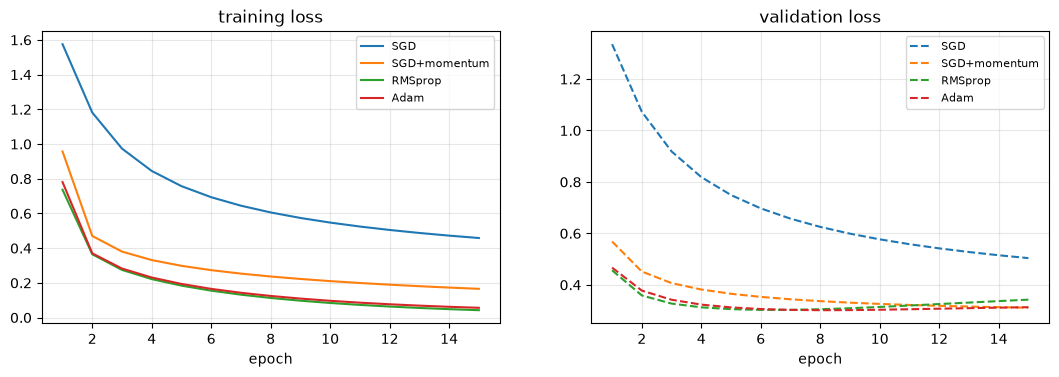

Check: True


In [8]:
def make_optimizers():
    return {
        "SGD":          keras.optimizers.SGD(learning_rate=1e-3),   # TODO
        "SGD+momentum": keras.optimizers.SGD(learning_rate=1e-3, momentum=0.9),   # TODO
        "RMSprop":      keras.optimizers.RMSprop(learning_rate=1e-3),   # TODO
        "Adam":         keras.optimizers.Adam(learning_rate=1e-3),   # TODO
    }

race = {}
for name, opt in make_optimizers().items():
    keras.utils.set_random_seed(SEED)
    m = head_model()
    m.compile(optimizer=opt, loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    race[name] = m.fit(F_train, y_tr, validation_data=(F_val, y_va), epochs=15, batch_size=BATCH, verbose=0).history
    v = race[name]["val_loss"]
    print(f"{name:13s} val loss after 1 epoch {v[0]:.3f} · after 5 {v[4]:.3f} · after 15 {v[-1]:.3f} · lowest {min(v):.3f} at epoch {int(np.argmin(v)) + 1}")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for (name, h), color in zip(race.items(), plt.cm.tab10.colors):
    axes[0].plot(np.arange(1, 16), h["loss"], color=color, label=name)
    axes[1].plot(np.arange(1, 16), h["val_loss"], "--", color=color, label=name)
for ax, t in zip(axes, ["training loss", "validation loss"]):
    ax.set_title(t); ax.set_xlabel("epoch"); ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.show()
print("Check:", min(race["Adam"]["val_loss"]) < min(race["SGD"]["val_loss"]))

✍️ **Question 2.** (a) Rank the four optimizers by how fast the validation loss falls. Which would you choose as your default, and why? (b) Plain SGD is the slowest here. Name two things you could change to make it competitive. (c) For the fastest optimizers, the validation loss reaches its lowest point and then creeps back up while the training loss keeps falling. What is that called, and what would you do about it? (d) This head is all that stage 1 of transfer learning trains: 6,405 of 2.26 million parameters. Why does a frozen base trained on ImageNet still give good features for flowers?

*Your answer:*
(a) 1. RMSprop, 2. Adam, 3. SGD with momentum, 4. plain SGD. I would choose Adam as my default. It was nearly as fast as RMSprop and reached the lowest validation loss overall, and it's validation loss didn't increase in the later epochs compared to RMSProp

(b) I would try a higher learning rate than 0.001 and add momentum of 0.9. The run shows how much momentum helped: by epoch 5, it had reduced validation loss to 0.365, while plain SGD was still at 0.749.

(c) This is overfitting. Training loss kept falling, but RMSprop’s validation loss rose from 0.303 at epoch 6 to 0.342 at epoch 15. Adam’s rose from 0.301 at epoch 8 to 0.313 at epoch 15. I would use **early stopping** on val_loss with restore_best_weights=True to keep the weights from the best validation epoch.

(d) ImageNet training taught MobileNetV2 to recognize visual patterns that flowers also contain, such as edges, textures, and shapes. The frozen base turns each photo into 1,280 features. The new head only has to learn which combinations of those features distinguish the five flower classes.

### 2d. Overfitting on purpose

Now break it. A **big** head (two hidden layers of 512, about 920,000 parameters) trained on only **10 photos per class** for 150 epochs. Then the same head with **dropout and early stopping**. Watch the two loss curves separate.

big head, no regularization   : epochs run 150 · train acc 1.000 · val loss at the last epoch 0.951 · lowest val loss 0.751 at epoch 4
dropout 0.5 + early stopping  : epochs run  18 · train acc 1.000 · val loss at the last epoch 0.838 · lowest val loss 0.766 at epoch 8


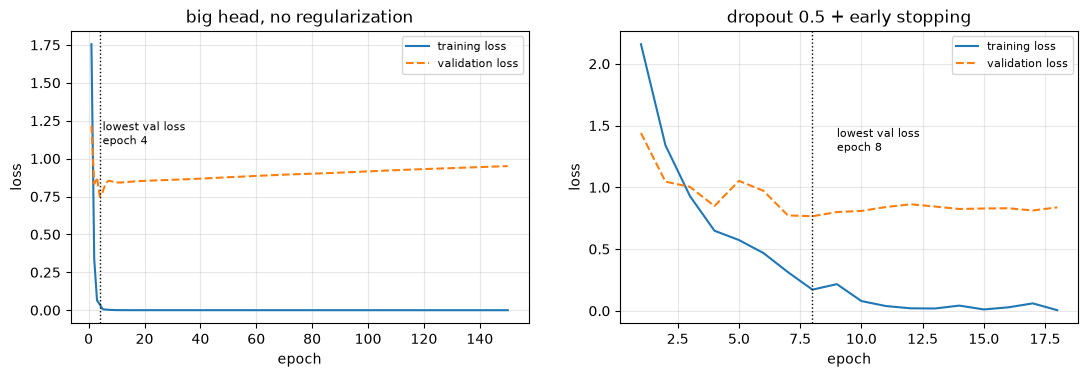

Check: True


In [9]:
rng = np.random.default_rng(SEED)
few = np.concatenate([rng.choice(np.where(y_tr == c)[0], 10, replace=False) for c in range(NUM_CLASSES)])

def fit_head(model, callbacks=None):
    keras.utils.set_random_seed(SEED)
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model.fit(F_train[few], y_tr[few], validation_data=(F_val, y_va), epochs=150,
                     batch_size=16, callbacks=callbacks or [], verbose=0).history

h_overfit = fit_head(head_model(hidden=512))
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)   # TODO: keras.callbacks.EarlyStopping watching "val_loss", patience 10, restore_best_weights=True
h_regular = fit_head(head_model(hidden=512, dropout=0.5), [early_stop])

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, (name, h) in zip(axes, [("big head, no regularization", h_overfit), ("dropout 0.5 + early stopping", h_regular)]):
    best = int(np.argmin(h["val_loss"]))
    ax.plot(np.arange(1, len(h["loss"]) + 1), h["loss"], label="training loss")
    ax.plot(np.arange(1, len(h["loss"]) + 1), h["val_loss"], "--", label="validation loss")
    ax.axvline(best + 1, color="k", ls=":", lw=1); ax.text(best + 2, max(h["val_loss"]) * 0.9, f"lowest val loss\nepoch {best + 1}", fontsize=8)
    ax.set_title(name); ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax.grid(alpha=.3); ax.legend(fontsize=8)
    print(f"{name:30s}: epochs run {len(h['loss']):3d} · train acc {h['accuracy'][-1]:.3f} · val loss at the last epoch {h['val_loss'][-1]:.3f}"
          f" · lowest val loss {min(h['val_loss']):.3f} at epoch {best + 1}")
plt.show()
print("Check:", isinstance(early_stop, keras.callbacks.EarlyStopping) and len(h_regular["loss"]) < 150)

✍️ **Question 3: reading the curves.** (a) In the left plot, at which epoch does the model start to overfit? Give two signs in the plot that tell you so. (b) Training accuracy is near 100% at the end. Why is that *not* good news? (c) Early stopping keeps the weights from the best epoch. Compare the validation loss of the model you would keep in each plot. Did regularization make 50 photos as good as 2,568? Name one other way to fight overfitting (hint: Part 2e uses it, and the best one is not a layer at all).

*Your answer:*
(a) The unregularized model starts to overfit just after epoch 4. Training loss continues to fall toward zero, while validation loss reaches its minimum of 0.751 at epoch 4 and then trends upward, ending at 0.951.

(b) The model reached 100% training accuracy on just 50 photos, or 10 per class. This means that the model memorized those examples. The rising validation loss shows that continued training made its predictions on the validation set worse.

(c) The unregularized model kept its epoch-150 weights, with a validation loss of 0.951. The model with dropout stopped at epoch 18 and restored its epoch-8 weights, with a validation loss of 0.766. Early stopping therefore gave us a better final model, even though the unregularized model briefly reached a lower loss of 0.751. Regularization did not make 50 photos as effective as 2,568: the full-data Adam model reached 0.301 validation loss. Another way to fight overfitting is data augmentation, such as the random flips, rotations, and zooms used in Part 2e. Colab notebook, Parts 2c–2e

### 2e. Stage 1 on the full model

Back to the full model with augmentation (random flips, rotations and zooms: a regularizer that creates new versions of each photo every epoch). Five epochs with **Adam at $10^{-3}$**, the winner of the race. Only the 6,405 head parameters change. We save the weights so that Part 3 always starts from this exact model, even if you run Part 3 twice.

Epoch 1/5


/mnt/e/BSCS 4th Year/CSC173/nasayao-csc173-repository/.local-finetune/tf-env/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


81/81 - 19s - 235ms/step - accuracy: 0.6266 - loss: 0.9853 - val_accuracy: 0.8185 - val_loss: 0.5226


Epoch 2/5


81/81 - 5s - 67ms/step - accuracy: 0.8181 - loss: 0.5037 - val_accuracy: 0.8639 - val_loss: 0.4150


Epoch 3/5


... (2 outputs left out)

81/81 - 5s - 65ms/step - accuracy: 0.8660 - loss: 0.3692 - val_accuracy: 0.8748 - val_loss: 0.3747


Epoch 5/5


81/81 - 5s - 65ms/step - accuracy: 0.8777 - loss: 0.3434 - val_accuracy: 0.8820 - val_loss: 0.3470


stage 1 done in 42 s · validation accuracy 0.882


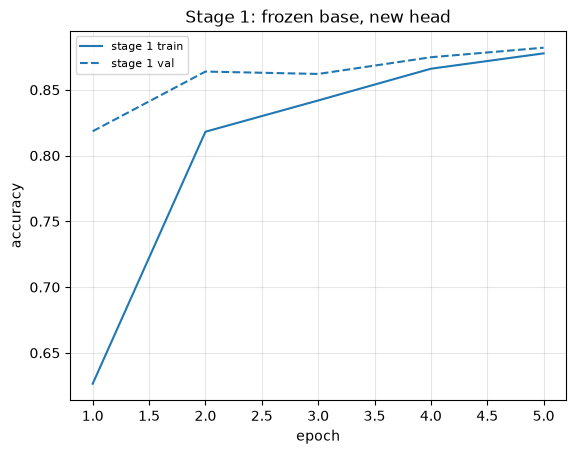

Check: True


In [10]:
WARMUP_EPOCHS = 5
FT_EPOCHS = 5
WARMUP_FILE = "warmup.weights.h5"

def compile_model(model, lr, optimizer="adam"):
    opt = keras.optimizers.Adam(lr) if optimizer == "adam" else keras.optimizers.SGD(lr, momentum=0.9)
    model.compile(optimizer=opt, loss="sparse_categorical_crossentropy", metrics=["accuracy"])

compile_model(model, 1e-3)
t0 = time.time()
warmup = model.fit(train_ds, validation_data=val_ds, epochs=WARMUP_EPOCHS, verbose=2).history
warmup_time = time.time() - t0
model.save_weights(WARMUP_FILE)
warmup_val_acc = warmup["val_accuracy"][-1]
print(f"stage 1 done in {warmup_time:.0f} s · validation accuracy {warmup_val_acc:.3f}")
plot_history({"stage 1": warmup}, "accuracy", "Stage 1: frozen base, new head"); plt.show()
print("Check:", warmup_val_acc > 0.80)

---
## 3. The fine-tuning challenge 🏆

Fine-tuning means: **unfreeze** some of the top layers of the base and keep training them together with the head, usually with a **much smaller learning rate**, so the pretrained features adapt to flowers without being destroyed.

Now it is a competition. **The group with the highest test accuracy gets a perfect score (20/20) for this activity.** Every other group is graded with the rubric.

### 3a. Write the unfreeze function

In [11]:
def set_fine_tune(base, n_unfrozen=None):
    # Make the last n_unfrozen layers of the base trainable and freeze all the others.
    # n_unfrozen=None unfreezes the whole base; n_unfrozen=0 keeps it fully frozen.
    base.trainable = True
    n = len(base.layers) if n_unfrozen is None else n_unfrozen
    for i, layer in enumerate(base.layers):
        layer.trainable = i >= len(base.layers) - n      # TODO: True only for the last n layers (compare i with len(base.layers) - n)

# test it on a throwaway copy
_, test_base = build_model()
set_fine_tune(test_base, 30)
flags = [l.trainable for l in test_base.layers]
print(f"unfrozen layers: {sum(flags)} of {len(flags)} · first unfrozen layer: {test_base.layers[flags.index(True)].name}")
ok_30 = flags == [False] * (len(flags) - 30) + [True] * 30
set_fine_tune(test_base, None); ok_all = all(l.trainable for l in test_base.layers)
set_fine_tune(test_base, 0);    ok_none = not any(l.trainable for l in test_base.layers)
print("Check:", ok_30 and ok_all and ok_none)

unfrozen layers: 30 of 154 · first unfrozen layer: block_13_project_BN
Check: True


### 3b. Challenge rules

*Experimenter leads this part.*

**Your knobs** (a *recipe*):

| Knob | Allowed values | What it controls |
|---|---|---|
| `unfreeze` | `0` to `154`, or `None` for all | how many of the top layers of the base are trained |
| `optimizer` | `"adam"`, `"rmsprop"`, `"sgd"` (SGD with momentum 0.9) | how each gradient becomes a step |
| `lr` | any positive number | the learning rate |
| `epochs` | `1` to `10` | fine-tuning epochs for this trial |
| `early_stopping` | `True` / `False` | stop when the validation loss stops improving (patience 2) and keep the best epoch |

**Fixed for everyone:** the data, the split, the seed, the model, and the stage 1 weights from Part 2e. Every trial starts again from those weights.

1. **Try as many recipes as you have time for** in 3d. Each trial takes about 1 to 2 minutes on a T4 GPU. Most groups fit 3 to 5.
2. **Your entry is chosen for you:** the trial with the highest **validation** accuracy. You never pick by looking at the test set.
3. **The test set is used once**, in Part 4a. The official score cell counts its runs. An entry whose score was computed more than once cannot win (it is still graded normally).
4. **Ties:** every group tied for first (to 3 decimals) gets the perfect score.
5. The instructor may re-run the winning notebook from top to bottom. The test accuracy must come out within 0.02 of the one on the leaderboard (GPUs are not perfectly repeatable).
6. Don't change the given code (split, data, model, `try_recipe`). Changing it disqualifies the entry.

✍️ **Question 4: plan before you run.** Before your first trial, write down your first recipe and one reason for **each** knob, using what you saw in Part 2 (the optimizer race, the overfitting plot) and the lecture. The Experimenter writes it; it is graded on reasoning.

*Your answer:*
- Unfreeze the last 30 layers. The frozen base already gave good results in Part 2. We want the later layers to adapt to flower shapes and petal patterns while preserving the earlier filters that detect edges and textures.
- Use Adam. In our optimizer race, Adam reached the lowest validation loss, 0.301 at epoch 8, slightly better than RMSprop’s 0.303. That makes Adam a reasonable first choice for fine-tuning.
- Set the learning rate to 1e-5. This is 100 times smaller than the 1e-3 we used to train the new head. Now that we are updating pretrained weights too, smaller steps reduce the risk of disrupting useful features.
- Allow up to 5 epochs. We are starting from the trained Stage 1 model. Five epochs gives us a short first trial to see whether fine-tuning improves validation performance.
- Enable early stopping. In Part 2d, the unregularized model’s validation loss rose from 0.751 at epoch 4 to 0.951 at epoch 150, even though training accuracy reached 100%. We want to keep the weights from the lowest validation loss if the same pattern appears.

### 3c. The trial runner

Given code. `try_recipe` trains one recipe from the stage 1 weights, logs it in `TRIALS`, and keeps the model if it is your best so far on validation. It never touches the test set.

In [12]:
TRIALS = []                      # one row per trial
ENTRY = {"val_acc": -1}          # your best trial so far, by validation accuracy
ALLOWED_OPT = {"adam", "rmsprop", "sgd"}

def compile_model(model, lr, optimizer="adam"):
    opt = {"adam": keras.optimizers.Adam, "rmsprop": keras.optimizers.RMSprop,
           "sgd": lambda lr: keras.optimizers.SGD(lr, momentum=0.9)}[optimizer](lr)
    model.compile(optimizer=opt, loss="sparse_categorical_crossentropy", metrics=["accuracy"])

def try_recipe(unfreeze=30, optimizer="adam", lr=1e-5, epochs=5, early_stopping=False, verbose=0):
    assert optimizer in ALLOWED_OPT and 1 <= epochs <= 10 and lr > 0 and (unfreeze is None or 0 <= unfreeze <= 154)
    keras.utils.set_random_seed(SEED)
    model, base = build_model()
    model.load_weights(WARMUP_FILE)                    # every trial starts from stage 1
    set_fine_tune(base, unfreeze)
    compile_model(model, lr, optimizer)                # recompile so the new trainable flags take effect
    callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)] if early_stopping else []
    t0 = time.time()
    h = model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=callbacks, verbose=verbose).history
    val_loss, val_acc = model.evaluate(val_ds, verbose=0)    # the weights we actually keep
    history = {k: warmup[k] + h[k] for k in warmup}         # stage 1 + stage 2, for the plots
    row = dict(trial=len(TRIALS) + 1, unfreeze=unfreeze, optimizer=optimizer, lr=lr, epochs_run=len(h["loss"]),
               early_stopping=early_stopping, trainable=count_params(model.trainable_weights),
               val_acc=val_acc, val_loss=val_loss, seconds=time.time() - t0, history=history)
    TRIALS.append(row)
    if val_acc > ENTRY["val_acc"]:
        ENTRY.clear(); ENTRY.update(row, model=model)

    fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
    plot_history({f"trial {row['trial']}": history}, "loss", f"trial {row['trial']}: loss", axes[0], WARMUP_EPOCHS)
    plot_history({f"trial {row['trial']}": history}, "accuracy", "accuracy", axes[1], WARMUP_EPOCHS)
    plt.show()
    show_trials()

def show_trials():
    print(f"{'trial':>5} {'unfreeze':>8} {'optimizer':>9} {'lr':>8} {'epochs':>6} {'early':>5} {'trainable':>10} {'val_acc':>7} {'val_loss':>8} {'time':>6}")
    for r in sorted(TRIALS, key=lambda r: -r["val_acc"]):
        mark = "  ← your entry" if r["trial"] == ENTRY.get("trial") else ""
        print(f"{r['trial']:>5} {str(r['unfreeze']):>8} {r['optimizer']:>9} {r['lr']:>8.0e} {r['epochs_run']:>6} {str(r['early_stopping']):>5} "
              f"{r['trainable']:>10,} {r['val_acc']:>7.3f} {r['val_loss']:>8.3f} {r['seconds']:>5.0f}s{mark}")

### 3d. Your trials

Edit the recipe and run the cell again for each new trial. Watch the curves: if the validation loss jumps up when fine-tuning starts, the learning rate is too big; if nothing moves, it is too small or too few layers are unfrozen; if training loss keeps falling while validation loss rises, you are overfitting.

A safe starting point is `unfreeze=30, optimizer="adam", lr=1e-5, epochs=5`. You can do better.

In [ ]:
try_recipe(unfreeze=30, optimizer="adam", lr=1e-5, epochs=5, early_stopping=True)   # TODO: your recipe from Question 4

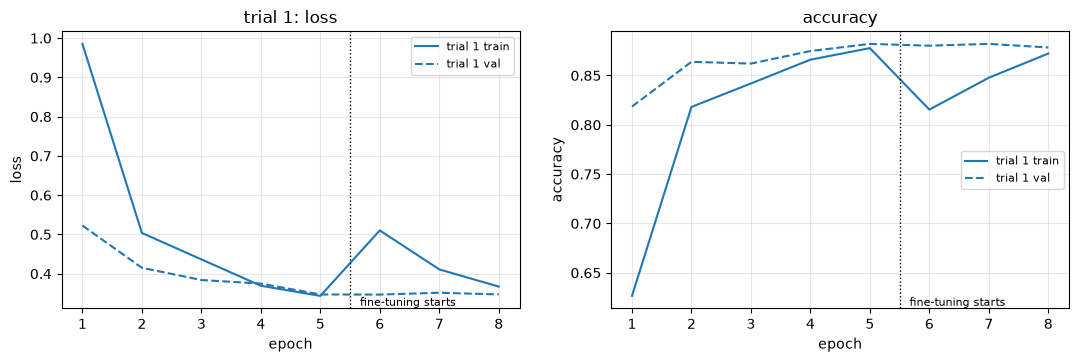

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
    1       30      adam    1e-05      3  True  1,532,805   0.880    0.347    37s  ← your entry


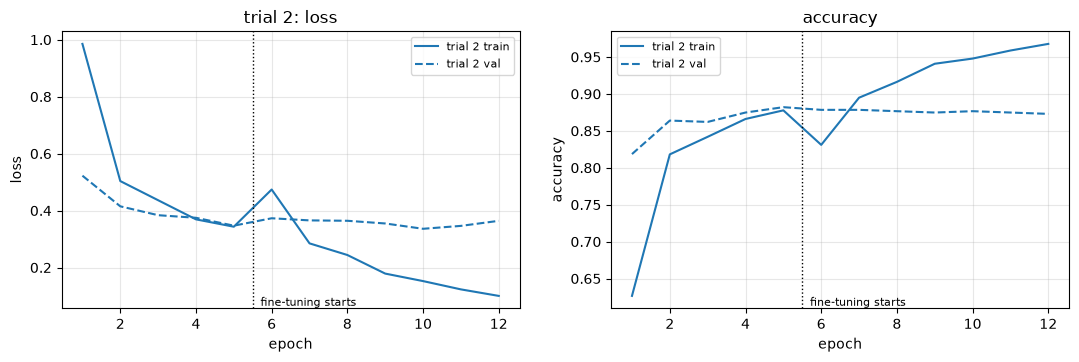

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
    1       30      adam    1e-05      3  True  1,532,805   0.880    0.347    37s  ← your entry
    2       60      adam    5e-05      7  True  1,962,117   0.877    0.336    87s


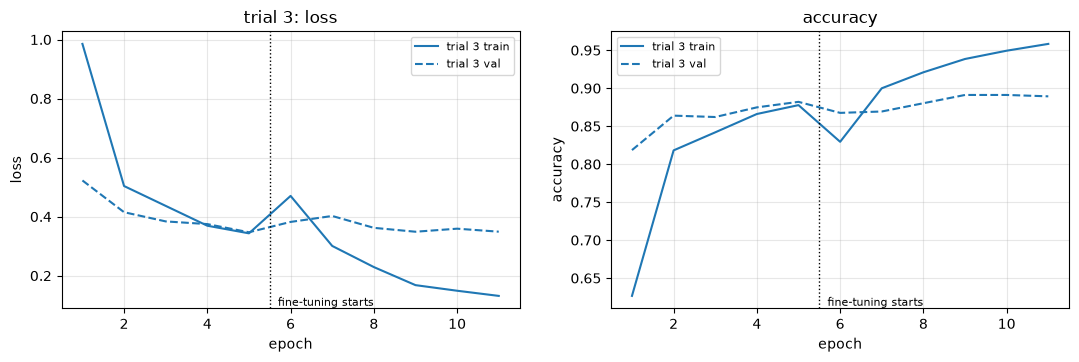

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
    3       60   rmsprop    5e-05      6  True  1,962,117   0.891    0.349    62s  ← your entry
    1       30      adam    1e-05      3  True  1,532,805   0.880    0.347    37s
    2       60      adam    5e-05      7  True  1,962,117   0.877    0.336    87s


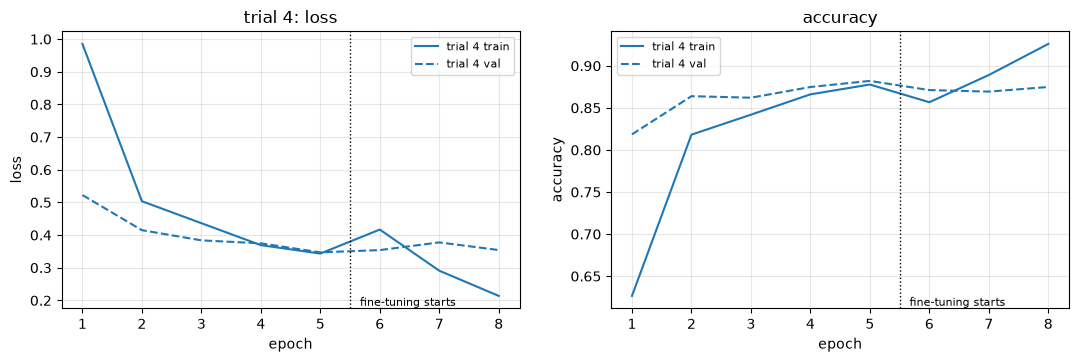

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
    3       60   rmsprop    5e-05      6  True  1,962,117   0.891    0.349    62s  ← your entry
    1       30      adam    1e-05      3  True  1,532,805   0.880    0.347    37s
    2       60      adam    5e-05      7  True  1,962,117   0.877    0.336    87s
    4       30   rmsprop    5e-05      3  True  1,532,805   0.871    0.354    30s


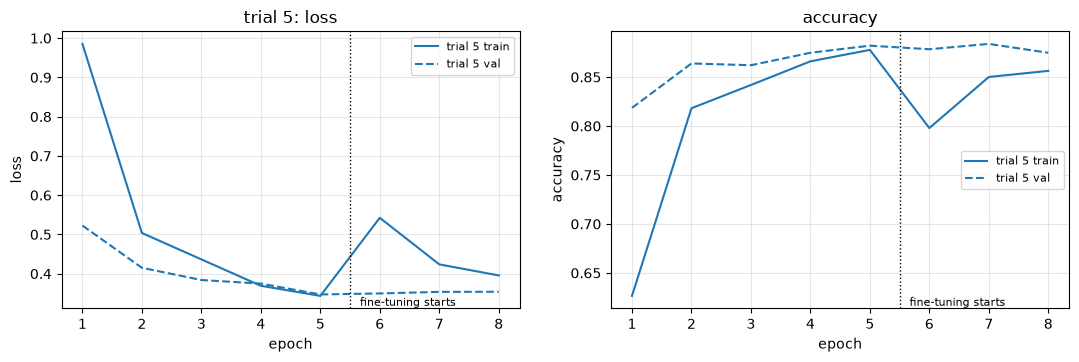

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
    3       60   rmsprop    5e-05      6  True  1,962,117   0.891    0.349    62s  ← your entry
    1       30      adam    1e-05      3  True  1,532,805   0.880    0.347    37s
    5       40      adam    1e-05      3  True  1,687,941   0.878    0.350    38s
    2       60      adam    5e-05      7  True  1,962,117   0.877    0.336    87s
    4       30   rmsprop    5e-05      3  True  1,532,805   0.871    0.354    30s


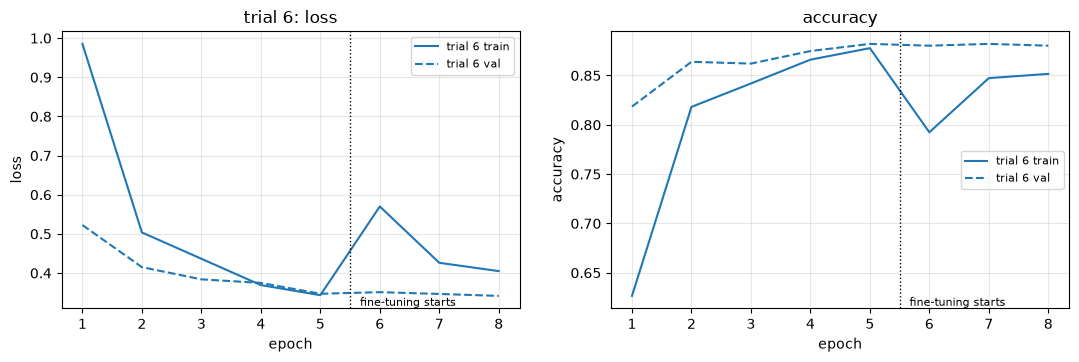

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
    3       60   rmsprop    5e-05      6  True  1,962,117   0.891    0.349    62s  ← your entry
    1       30      adam    1e-05      3  True  1,532,805   0.880    0.347    37s
    6       50      adam    1e-05      3  True  1,861,509   0.880    0.342    41s
    5       40      adam    1e-05      3  True  1,687,941   0.878    0.350    38s
    2       60      adam    5e-05      7  True  1,962,117   0.877    0.336    87s
    4       30   rmsprop    5e-05      3  True  1,532,805   0.871    0.354    30s


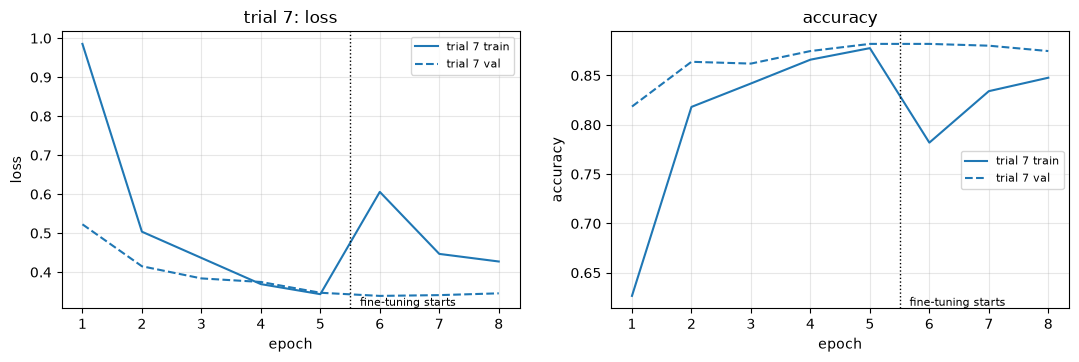

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
    3       60   rmsprop    5e-05      6  True  1,962,117   0.891    0.349    62s  ← your entry
    7       60      adam    1e-05      3  True  1,962,117   0.882    0.339    45s
    1       30      adam    1e-05      3  True  1,532,805   0.880    0.347    37s
    6       50      adam    1e-05      3  True  1,861,509   0.880    0.342    41s
    5       40      adam    1e-05      3  True  1,687,941   0.878    0.350    38s
    2       60      adam    5e-05      7  True  1,962,117   0.877    0.336    87s
    4       30   rmsprop    5e-05      3  True  1,532,805   0.871    0.354    30s


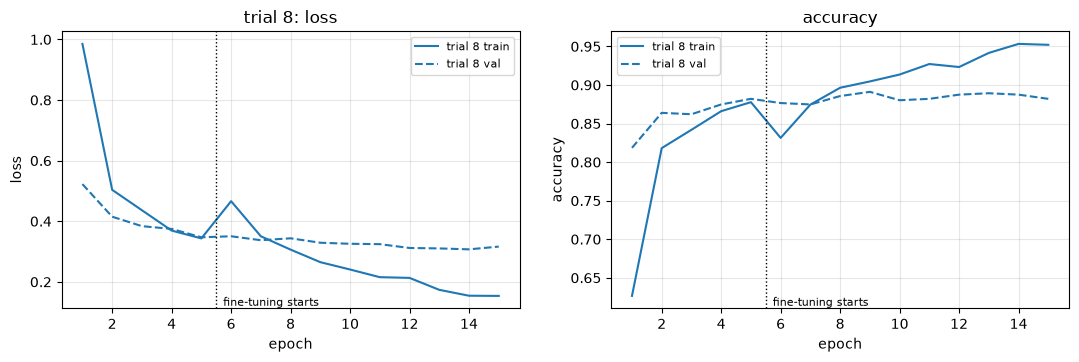

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
    3       60   rmsprop    5e-05      6  True  1,962,117   0.891    0.349    62s  ← your entry
    8       30      adam    2e-05     10  True  1,532,805   0.887    0.307    92s
    7       60      adam    1e-05      3  True  1,962,117   0.882    0.339    45s
    1       30      adam    1e-05      3  True  1,532,805   0.880    0.347    37s
    6       50      adam    1e-05      3  True  1,861,509   0.880    0.342    41s
    5       40      adam    1e-05      3  True  1,687,941   0.878    0.350    38s
    2       60      adam    5e-05      7  True  1,962,117   0.877    0.336    87s
    4       30   rmsprop    5e-05      3  True  1,532,805   0.871    0.354    30s


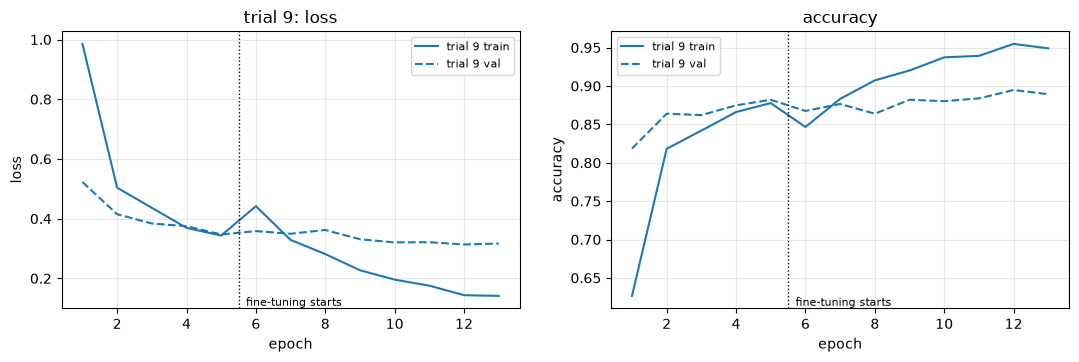

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s  ← your entry
    3       60   rmsprop    5e-05      6  True  1,962,117   0.891    0.349    62s
    8       30      adam    2e-05     10  True  1,532,805   0.887    0.307    92s
    7       60      adam    1e-05      3  True  1,962,117   0.882    0.339    45s
    1       30      adam    1e-05      3  True  1,532,805   0.880    0.347    37s
    6       50      adam    1e-05      3  True  1,861,509   0.880    0.342    41s
    5       40      adam    1e-05      3  True  1,687,941   0.878    0.350    38s
    2       60      adam    5e-05      7  True  1,962,117   0.877    0.336    87s
    4       30   rmsprop    5e-05      3  True  1,532,805   0.871    0.354    30s


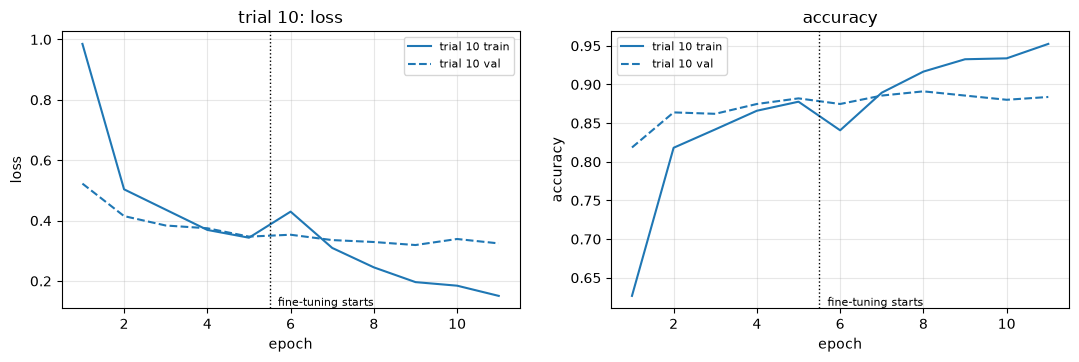

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s  ← your entry
    3       60   rmsprop    5e-05      6  True  1,962,117   0.891    0.349    62s
    8       30      adam    2e-05     10  True  1,532,805   0.887    0.307    92s
   10       30      adam    4e-05      6  True  1,532,805   0.886    0.319    62s
    7       60      adam    1e-05      3  True  1,962,117   0.882    0.339    45s
    1       30      adam    1e-05      3  True  1,532,805   0.880    0.347    37s
    6       50      adam    1e-05      3  True  1,861,509   0.880    0.342    41s
    5       40      adam    1e-05      3  True  1,687,941   0.878    0.350    38s
    2       60      adam    5e-05      7  True  1,962,117   0.877    0.336    87s
    4       30   rmsprop    5e-05      3  True  1,532,805   0.871    0.354    30s


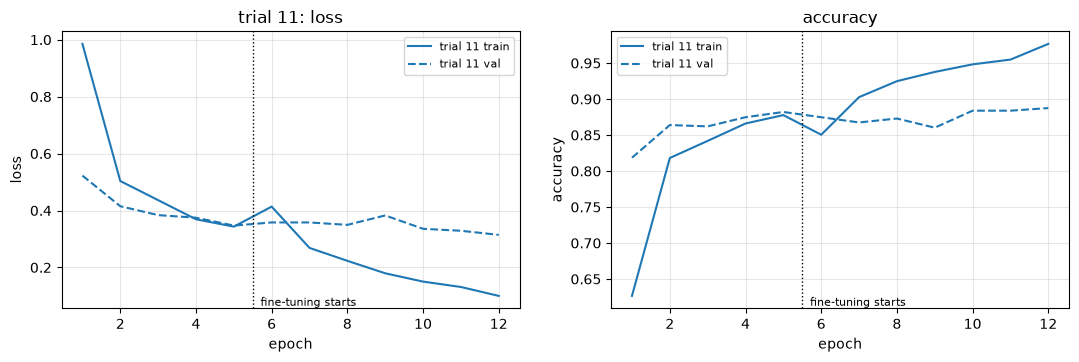

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s  ← your entry
    3       60   rmsprop    5e-05      6  True  1,962,117   0.891    0.349    62s
    8       30      adam    2e-05     10  True  1,532,805   0.887    0.307    92s
   11       30      adam    5e-05      7  True  1,532,805   0.887    0.314    71s
   10       30      adam    4e-05      6  True  1,532,805   0.886    0.319    62s
    7       60      adam    1e-05      3  True  1,962,117   0.882    0.339    45s
    1       30      adam    1e-05      3  True  1,532,805   0.880    0.347    37s
    6       50      adam    1e-05      3  True  1,861,509   0.880    0.342    41s
    5       40      adam    1e-05      3  True  1,687,941   0.878    0.350    38s
    2       60      adam    5e-05      7  True  1,962,117   0.877    0.336    87s
    4       30   rmsprop    5e-05      3  True  1,532,805   0.871    0.354    30s


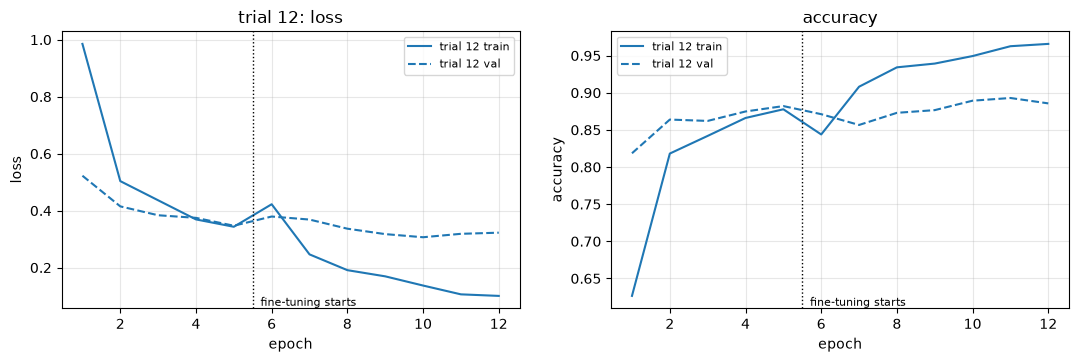

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s  ← your entry
    3       60   rmsprop    5e-05      6  True  1,962,117   0.891    0.349    62s
   12       30      adam    6e-05      7  True  1,532,805   0.889    0.307    70s
    8       30      adam    2e-05     10  True  1,532,805   0.887    0.307    92s
   11       30      adam    5e-05      7  True  1,532,805   0.887    0.314    71s
   10       30      adam    4e-05      6  True  1,532,805   0.886    0.319    62s
    7       60      adam    1e-05      3  True  1,962,117   0.882    0.339    45s
    1       30      adam    1e-05      3  True  1,532,805   0.880    0.347    37s
    6       50      adam    1e-05      3  True  1,861,509   0.880    0.342    41s
    5       40      adam    1e-05      3  True  1,687,941   0.878    0.350    38s
    2       60      adam    5e-05      7  True  1,962,117   0.877    0.336    87s
  

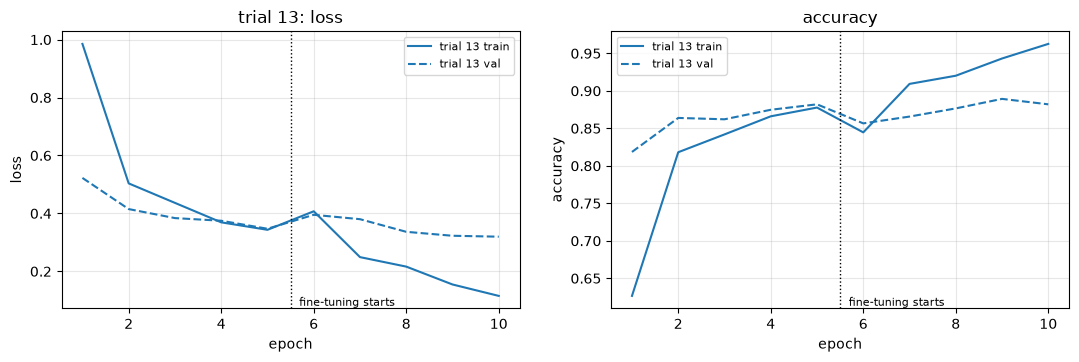

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s  ← your entry
    3       60   rmsprop    5e-05      6  True  1,962,117   0.891    0.349    62s
   12       30      adam    6e-05      7  True  1,532,805   0.889    0.307    70s
    8       30      adam    2e-05     10  True  1,532,805   0.887    0.307    92s
   11       30      adam    5e-05      7  True  1,532,805   0.887    0.314    71s
   10       30      adam    4e-05      6  True  1,532,805   0.886    0.319    62s
    7       60      adam    1e-05      3  True  1,962,117   0.882    0.339    45s
   13       30      adam    7e-05      5  True  1,532,805   0.882    0.320    56s
    1       30      adam    1e-05      3  True  1,532,805   0.880    0.347    37s
    6       50      adam    1e-05      3  True  1,861,509   0.880    0.342    41s
    5       40      adam    1e-05      3  True  1,687,941   0.878    0.350    38s
  

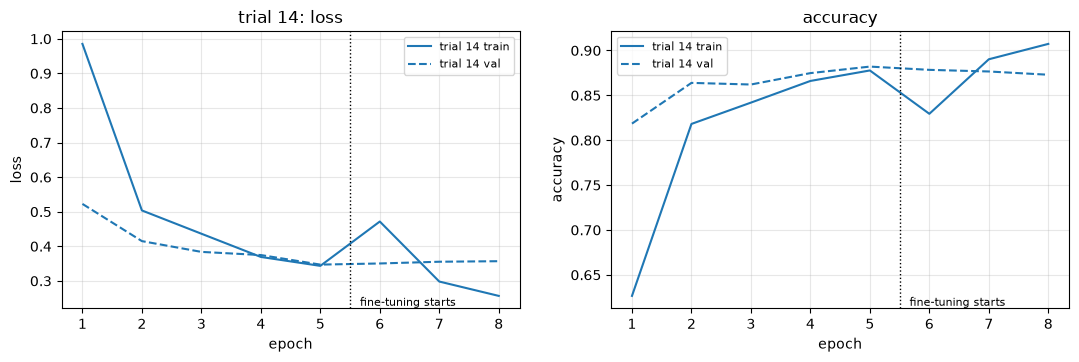

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s  ← your entry
    3       60   rmsprop    5e-05      6  True  1,962,117   0.891    0.349    62s
   12       30      adam    6e-05      7  True  1,532,805   0.889    0.307    70s
    8       30      adam    2e-05     10  True  1,532,805   0.887    0.307    92s
   11       30      adam    5e-05      7  True  1,532,805   0.887    0.314    71s
   10       30      adam    4e-05      6  True  1,532,805   0.886    0.319    62s
    7       60      adam    1e-05      3  True  1,962,117   0.882    0.339    45s
   13       30      adam    7e-05      5  True  1,532,805   0.882    0.320    56s
    1       30      adam    1e-05      3  True  1,532,805   0.880    0.347    37s
    6       50      adam    1e-05      3  True  1,861,509   0.880    0.342    41s
    5       40      adam    1e-05      3  True  1,687,941   0.878    0.350    38s
  

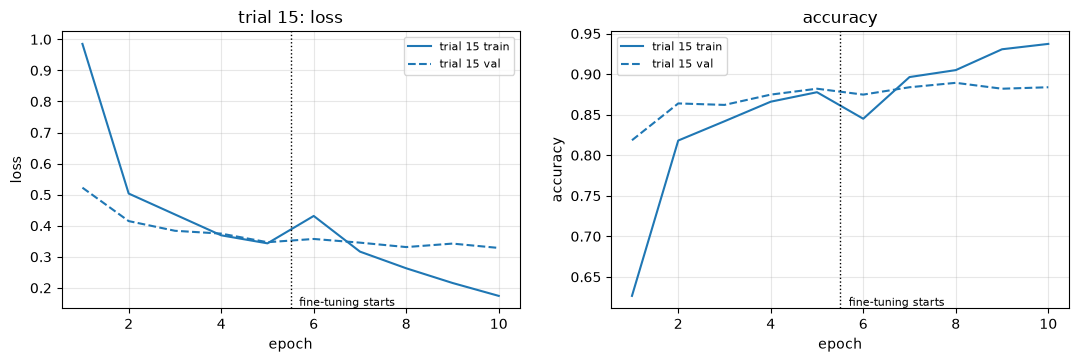

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s  ← your entry
    3       60   rmsprop    5e-05      6  True  1,962,117   0.891    0.349    62s
   12       30      adam    6e-05      7  True  1,532,805   0.889    0.307    70s
    8       30      adam    2e-05     10  True  1,532,805   0.887    0.307    92s
   11       30      adam    5e-05      7  True  1,532,805   0.887    0.314    71s
   10       30      adam    4e-05      6  True  1,532,805   0.886    0.319    62s
   15       20      adam    4e-05      5  True  1,212,485   0.884    0.329    45s
    7       60      adam    1e-05      3  True  1,962,117   0.882    0.339    45s
   13       30      adam    7e-05      5  True  1,532,805   0.882    0.320    56s
    1       30      adam    1e-05      3  True  1,532,805   0.880    0.347    37s
    6       50      adam    1e-05      3  True  1,861,509   0.880    0.342    41s
  

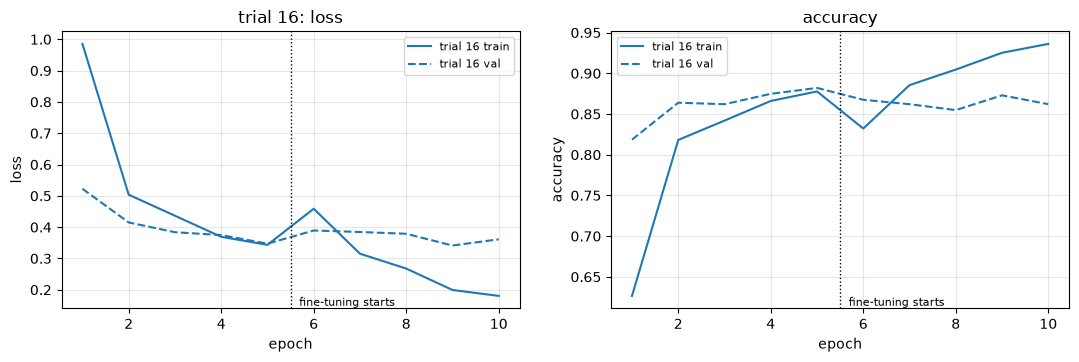

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s  ← your entry
    3       60   rmsprop    5e-05      6  True  1,962,117   0.891    0.349    62s
   12       30      adam    6e-05      7  True  1,532,805   0.889    0.307    70s
    8       30      adam    2e-05     10  True  1,532,805   0.887    0.307    92s
   11       30      adam    5e-05      7  True  1,532,805   0.887    0.314    71s
   10       30      adam    4e-05      6  True  1,532,805   0.886    0.319    62s
   15       20      adam    4e-05      5  True  1,212,485   0.884    0.329    45s
    7       60      adam    1e-05      3  True  1,962,117   0.882    0.339    45s
   13       30      adam    7e-05      5  True  1,532,805   0.882    0.320    56s
    1       30      adam    1e-05      3  True  1,532,805   0.880    0.347    37s
    6       50      adam    1e-05      3  True  1,861,509   0.880    0.342    41s
  

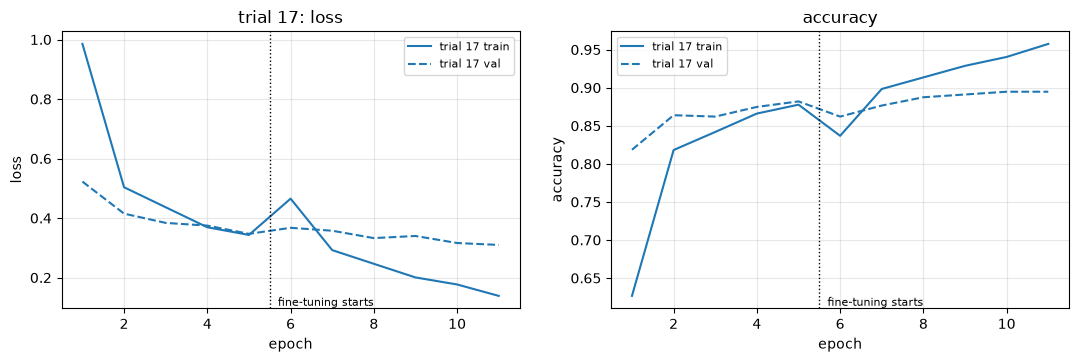

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s  ← your entry
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
    3       60   rmsprop    5e-05      6  True  1,962,117   0.891    0.349    62s
   12       30      adam    6e-05      7  True  1,532,805   0.889    0.307    70s
    8       30      adam    2e-05     10  True  1,532,805   0.887    0.307    92s
   11       30      adam    5e-05      7  True  1,532,805   0.887    0.314    71s
   10       30      adam    4e-05      6  True  1,532,805   0.886    0.319    62s
   15       20      adam    4e-05      5  True  1,212,485   0.884    0.329    45s
    7       60      adam    1e-05      3  True  1,962,117   0.882    0.339    45s
   13       30      adam    7e-05      5  True  1,532,805   0.882    0.320    56s
    1       30      adam    1e-05      3  True  1,532,805   0.880    0.347    37s
  

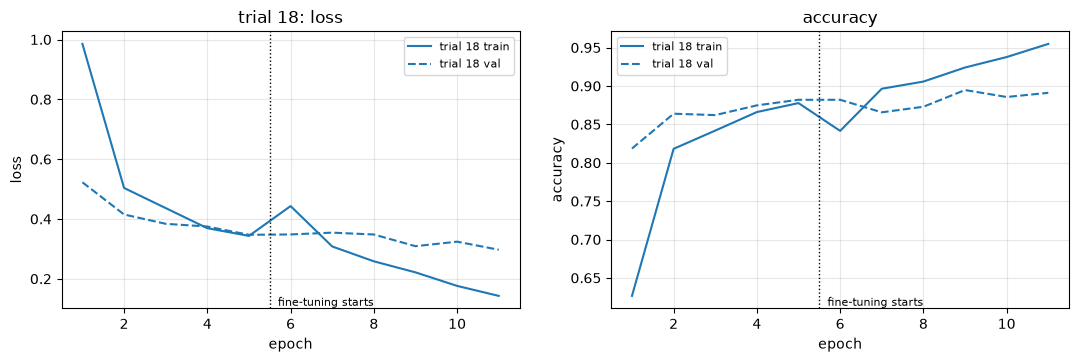

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s  ← your entry
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
    3       60   rmsprop    5e-05      6  True  1,962,117   0.891    0.349    62s
   18       30   rmsprop    4e-05      6  True  1,532,805   0.891    0.297    60s
   12       30      adam    6e-05      7  True  1,532,805   0.889    0.307    70s
    8       30      adam    2e-05     10  True  1,532,805   0.887    0.307    92s
   11       30      adam    5e-05      7  True  1,532,805   0.887    0.314    71s
   10       30      adam    4e-05      6  True  1,532,805   0.886    0.319    62s
   15       20      adam    4e-05      5  True  1,212,485   0.884    0.329    45s
    7       60      adam    1e-05      3  True  1,962,117   0.882    0.339    45s
   13       30      adam    7e-05      5  True  1,532,805   0.882    0.320    56s
  

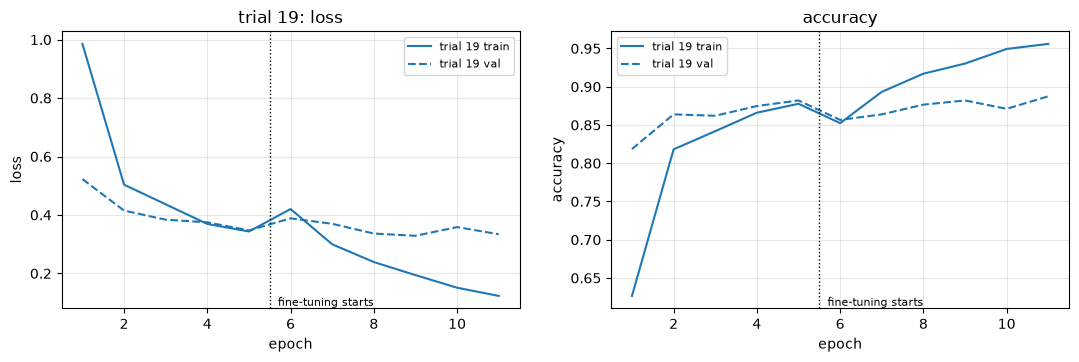

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s  ← your entry
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
    3       60   rmsprop    5e-05      6  True  1,962,117   0.891    0.349    62s
   18       30   rmsprop    4e-05      6  True  1,532,805   0.891    0.297    60s
   12       30      adam    6e-05      7  True  1,532,805   0.889    0.307    70s
    8       30      adam    2e-05     10  True  1,532,805   0.887    0.307    92s
   11       30      adam    5e-05      7  True  1,532,805   0.887    0.314    71s
   10       30      adam    4e-05      6  True  1,532,805   0.886    0.319    62s
   15       20      adam    4e-05      5  True  1,212,485   0.884    0.329    45s
    7       60      adam    1e-05      3  True  1,962,117   0.882    0.339    45s
   13       30      adam    7e-05      5  True  1,532,805   0.882    0.320    56s
  

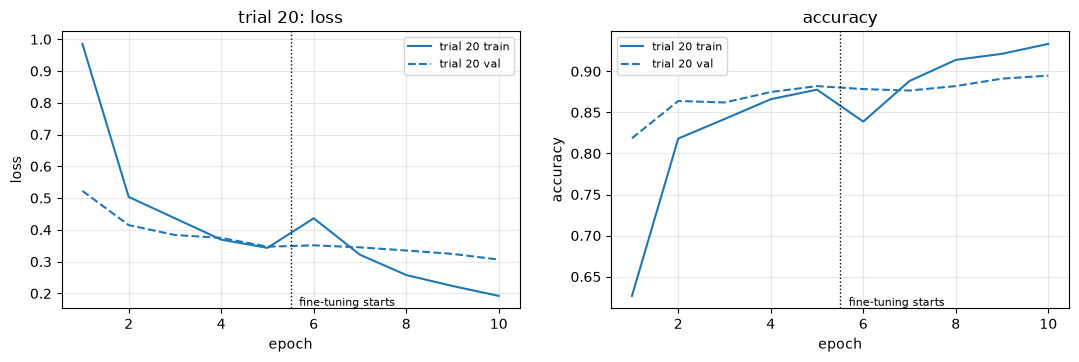

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s  ← your entry
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
    3       60   rmsprop    5e-05      6  True  1,962,117   0.891    0.349    62s
   18       30   rmsprop    4e-05      6  True  1,532,805   0.891    0.297    60s
   12       30      adam    6e-05      7  True  1,532,805   0.889    0.307    70s
    8       30      adam    2e-05     10  True  1,532,805   0.887    0.307    92s
   11       30      adam    5e-05      7  True  1,532,805   0.887    0.314    71s
   10       30      adam    4e-05      6  True  1,532,805   0.886    0.319    62s
   15       20      adam    4e-05      5  True  1,212,485   0.884    0.329    45s
    7       60      adam    1e-05      3  True  1,962,117   0.882    0.339    45s
  

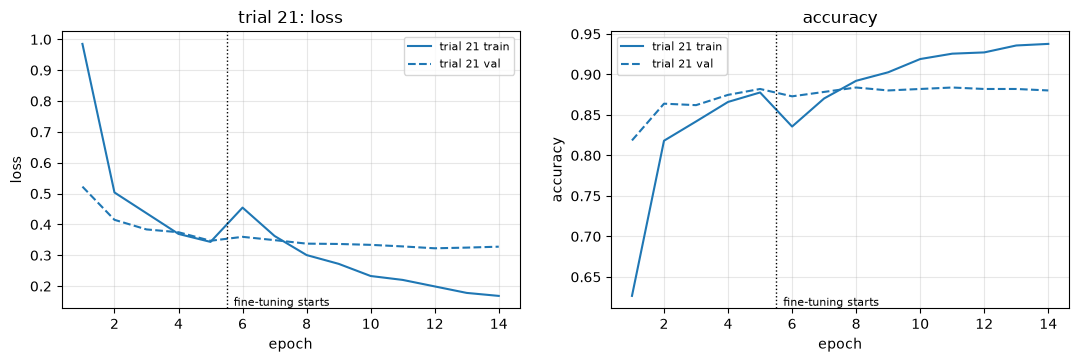

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s  ← your entry
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
    3       60   rmsprop    5e-05      6  True  1,962,117   0.891    0.349    62s
   18       30   rmsprop    4e-05      6  True  1,532,805   0.891    0.297    60s
   12       30      adam    6e-05      7  True  1,532,805   0.889    0.307    70s
    8       30      adam    2e-05     10  True  1,532,805   0.887    0.307    92s
   11       30      adam    5e-05      7  True  1,532,805   0.887    0.314    71s
   10       30      adam    4e-05      6  True  1,532,805   0.886    0.319    62s
   15       20      adam    4e-05      5  True  1,212,485   0.884    0.329    45s
    7       60      adam    1e-05      3  True  1,962,117   0.882    0.339    45s
  

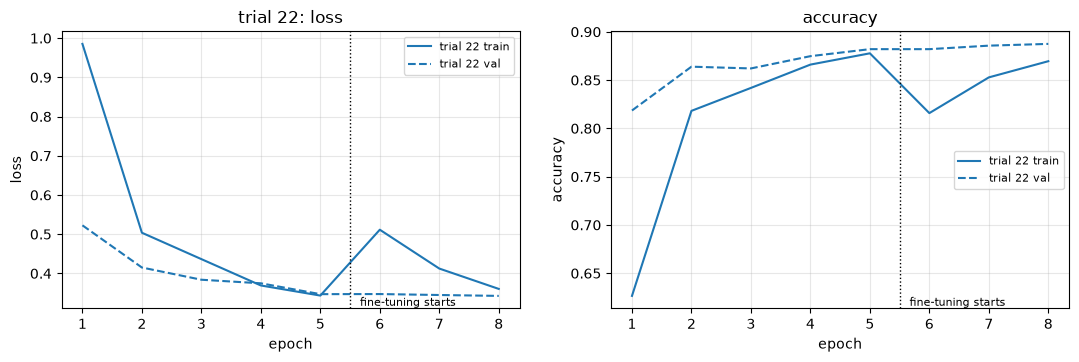

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s  ← your entry
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
    3       60   rmsprop    5e-05      6  True  1,962,117   0.891    0.349    62s
   18       30   rmsprop    4e-05      6  True  1,532,805   0.891    0.297    60s
   12       30      adam    6e-05      7  True  1,532,805   0.889    0.307    70s
    8       30      adam    2e-05     10  True  1,532,805   0.887    0.307    92s
   11       30      adam    5e-05      7  True  1,532,805   0.887    0.314    71s
   22       30   rmsprop    1e-05      3  True  1,532,805   0.887    0.343    31s
   10       30      adam    4e-05      6  True  1,532,805   0.886    0.319    62s
   15       20      adam    4e-05      5  True  1,212,485   0.884    0.329    45s
  

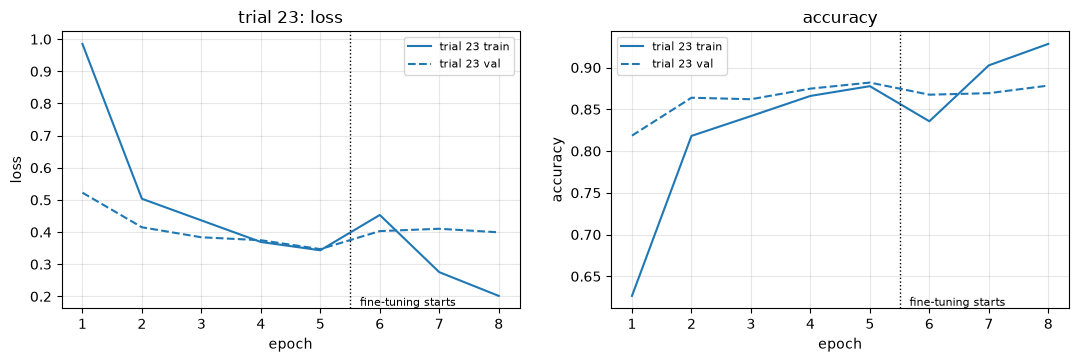

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s  ← your entry
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
    3       60   rmsprop    5e-05      6  True  1,962,117   0.891    0.349    62s
   18       30   rmsprop    4e-05      6  True  1,532,805   0.891    0.297    60s
   12       30      adam    6e-05      7  True  1,532,805   0.889    0.307    70s
    8       30      adam    2e-05     10  True  1,532,805   0.887    0.307    92s
   11       30      adam    5e-05      7  True  1,532,805   0.887    0.314    71s
   22       30   rmsprop    1e-05      3  True  1,532,805   0.887    0.343    31s
   10       30      adam    4e-05      6  True  1,532,805   0.886    0.319    62s
   15       20      adam    4e-05      5  True  1,212,485   0.884    0.329    45s
  

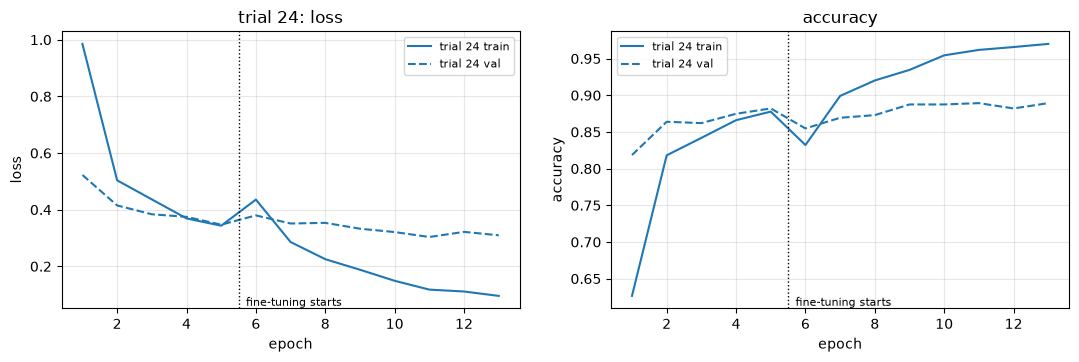

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s  ← your entry
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
    3       60   rmsprop    5e-05      6  True  1,962,117   0.891    0.349    62s
   18       30   rmsprop    4e-05      6  True  1,532,805   0.891    0.297    60s
   12       30      adam    6e-05      7  True  1,532,805   0.889    0.307    70s
   24       30      adam    5e-05      8  True  1,532,805   0.889    0.304    99s
    8       30      adam    2e-05     10  True  1,532,805   0.887    0.307    92s
   11       30      adam    5e-05      7  True  1,532,805   0.887    0.314    71s
   22       30   rmsprop    1e-05      3  True  1,532,805   0.887    0.343    31s
   10       30      adam    4e-05      6  True  1,532,805   0.886    0.319    62s
  

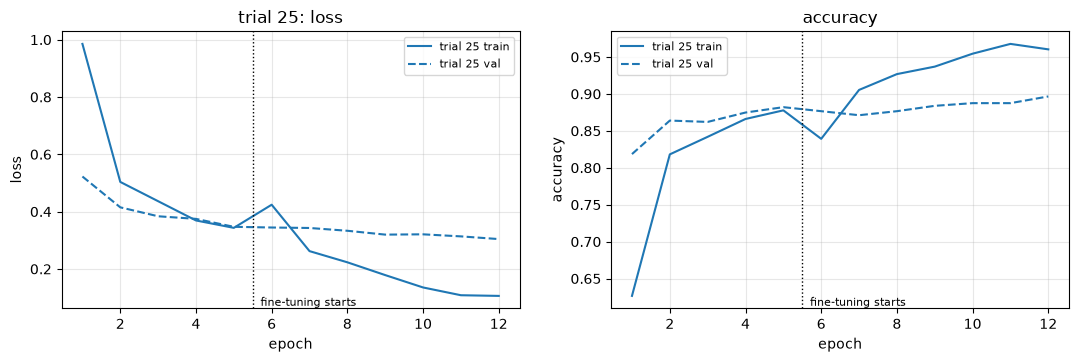

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s  ← your entry
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
    3       60   rmsprop    5e-05      6  True  1,962,117   0.891    0.349    62s
   18       30   rmsprop    4e-05      6  True  1,532,805   0.891    0.297    60s
   12       30      adam    6e-05      7  True  1,532,805   0.889    0.307    70s
   24       30      adam    5e-05      8  True  1,532,805   0.889    0.304    99s
    8       30      adam    2e-05     10  True  1,532,805   0.887    0.307    92s
   11       30      adam    5e-05      7  True  1,532,805   0.887    0.314    71s
   22       30   rmsprop    1e-05      3  True  1,532,805   0.887    0.343    31s
  

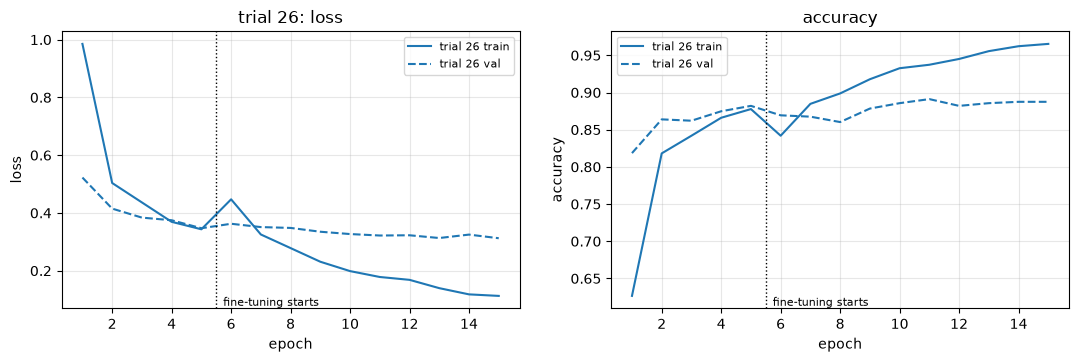

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s  ← your entry
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
    3       60   rmsprop    5e-05      6  True  1,962,117   0.891    0.349    62s
   18       30   rmsprop    4e-05      6  True  1,532,805   0.891    0.297    60s
   12       30      adam    6e-05      7  True  1,532,805   0.889    0.307    70s
   24       30      adam    5e-05      8  True  1,532,805   0.889    0.304    99s
    8       30      adam    2e-05     10  True  1,532,805   0.887    0.307    92s
   11       30      adam    5e-05      7  True  1,532,805   0.887    0.314    71s
   22       30   rmsprop    1e-05      3  True  1,532,805   0.887    0.343    31s
  

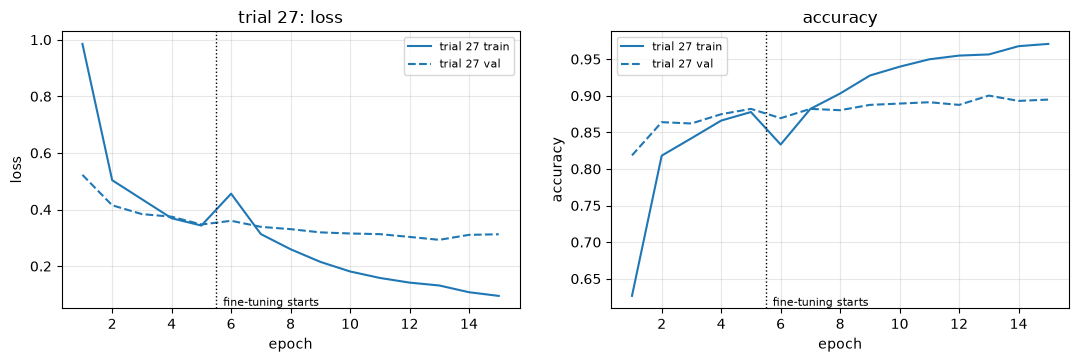

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s  ← your entry
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
    3       60   rmsprop    5e-05      6  True  1,962,117   0.891    0.349    62s
   18       30   rmsprop    4e-05      6  True  1,532,805   0.891    0.297    60s
   12       30      adam    6e-05      7  True  1,532,805   0.889    0.307    70s
   24       30      adam    5e-05      8  True  1,532,805   0.889    0.304    99s
    8       30      adam    2e-05     10  True  1,532,805   0.887    0.307    92s
   11       30      adam    5e-05      7  True  1,532,805   0.887    0.314    71s
  

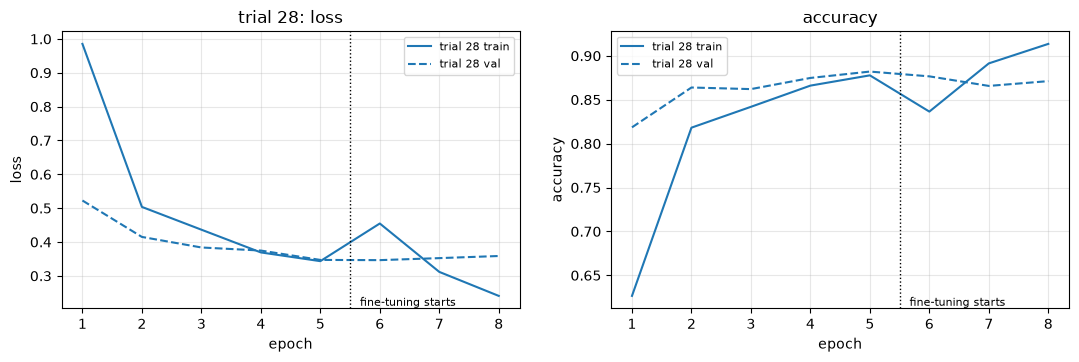

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s  ← your entry
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
    3       60   rmsprop    5e-05      6  True  1,962,117   0.891    0.349    62s
   18       30   rmsprop    4e-05      6  True  1,532,805   0.891    0.297    60s
   12       30      adam    6e-05      7  True  1,532,805   0.889    0.307    70s
   24       30      adam    5e-05      8  True  1,532,805   0.889    0.304    99s
    8       30      adam    2e-05     10  True  1,532,805   0.887    0.307    92s
   11       30      adam    5e-05      7  True  1,532,805   0.887    0.314    71s
  

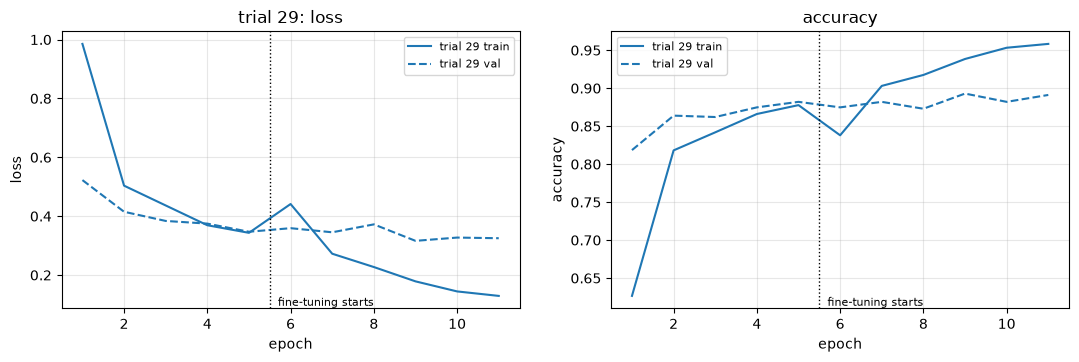

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s  ← your entry
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
   29       25      adam    6e-05      6  True  1,368,325   0.893    0.316    59s
    3       60   rmsprop    5e-05      6  True  1,962,117   0.891    0.349    62s
   18       30   rmsprop    4e-05      6  True  1,532,805   0.891    0.297    60s
   12       30      adam    6e-05      7  True  1,532,805   0.889    0.307    70s
   24       30      adam    5e-05      8  True  1,532,805   0.889    0.304    99s
    8       30      adam    2e-05     10  True  1,532,805   0.887    0.307    92s
  

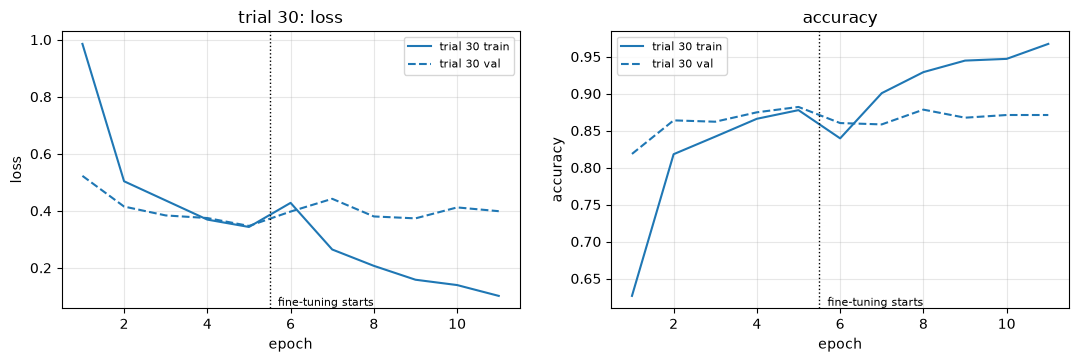

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s  ← your entry
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
   29       25      adam    6e-05      6  True  1,368,325   0.893    0.316    59s
    3       60   rmsprop    5e-05      6  True  1,962,117   0.891    0.349    62s
   18       30   rmsprop    4e-05      6  True  1,532,805   0.891    0.297    60s
   12       30      adam    6e-05      7  True  1,532,805   0.889    0.307    70s
   24       30      adam    5e-05      8  True  1,532,805   0.889    0.304    99s
    8       30      adam    2e-05     10  True  1,532,805   0.887    0.307    92s
  

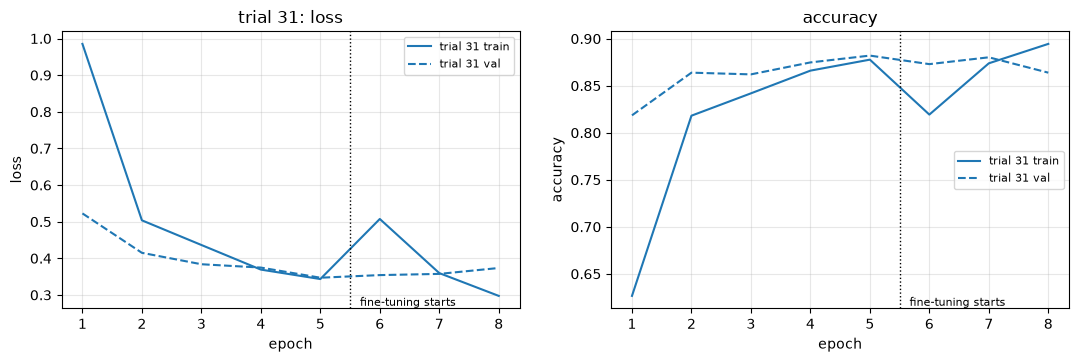

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s  ← your entry
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
   29       25      adam    6e-05      6  True  1,368,325   0.893    0.316    59s
    3       60   rmsprop    5e-05      6  True  1,962,117   0.891    0.349    62s
   18       30   rmsprop    4e-05      6  True  1,532,805   0.891    0.297    60s
   12       30      adam    6e-05      7  True  1,532,805   0.889    0.307    70s
   24       30      adam    5e-05      8  True  1,532,805   0.889    0.304    99s
    8       30      adam    2e-05     10  True  1,532,805   0.887    0.307    92s
  

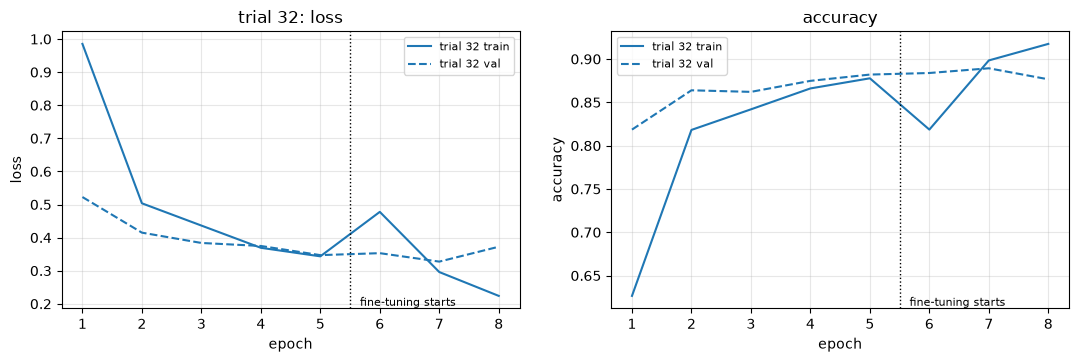

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s  ← your entry
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
   29       25      adam    6e-05      6  True  1,368,325   0.893    0.316    59s
    3       60   rmsprop    5e-05      6  True  1,962,117   0.891    0.349    62s
   18       30   rmsprop    4e-05      6  True  1,532,805   0.891    0.297    60s
   12       30      adam    6e-05      7  True  1,532,805   0.889    0.307    70s
   24       30      adam    5e-05      8  True  1,532,805   0.889    0.304    99s
   32       60      adam    5e-05      3  True  1,962,117   0.889    0.327    47s
  

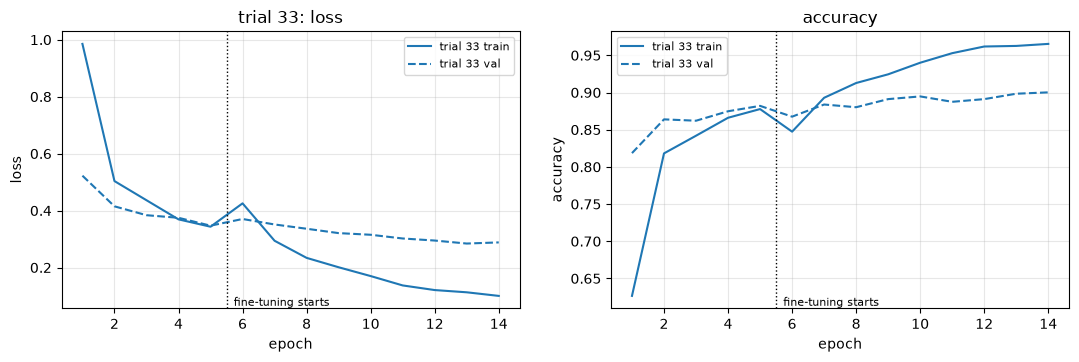

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s  ← your entry
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
   29       25      adam    6e-05      6  True  1,368,325   0.893    0.316    59s
    3       60   rmsprop    5e-05      6  True  1,962,117   0.891    0.349    62s
   18       30   rmsprop    4e-05      6  True  1,532,805   0.891    0.297    60s
   12       30      adam    6e-05      7  True  1,532,805   0.889    0.307    70s
   24       30      adam    5e-05      8  True  1,532,805   0.889    0.304    99s
  

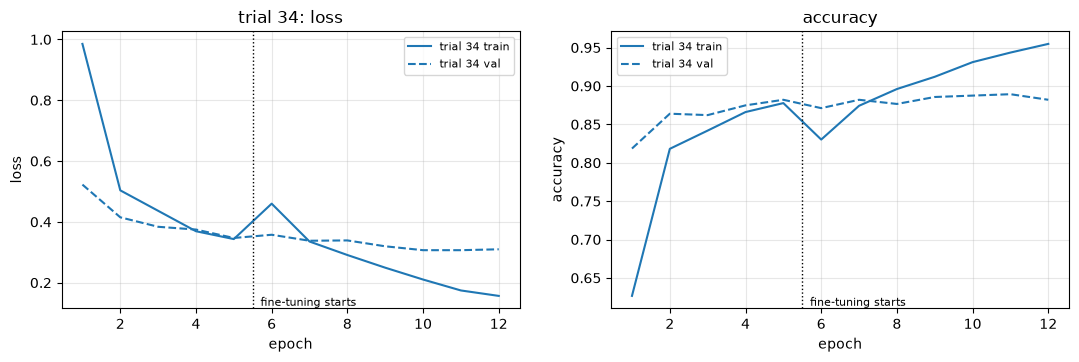

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s  ← your entry
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
   29       25      adam    6e-05      6  True  1,368,325   0.893    0.316    59s
    3       60   rmsprop    5e-05      6  True  1,962,117   0.891    0.349    62s
   18       30   rmsprop    4e-05      6  True  1,532,805   0.891    0.297    60s
   12       30      adam    6e-05      7  True  1,532,805   0.889    0.307    70s
   24       30      adam    5e-05      8  True  1,532,805   0.889    0.304    99s
  

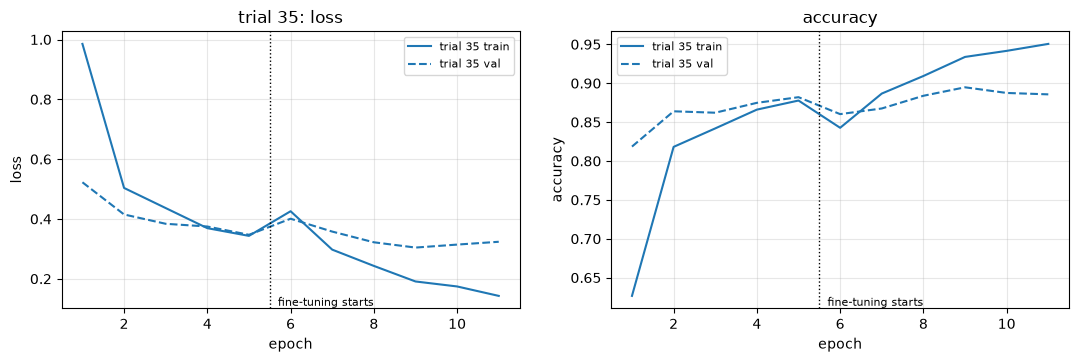

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s  ← your entry
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
   35       25      adam    5e-05      6  True  1,368,325   0.895    0.304    67s
   29       25      adam    6e-05      6  True  1,368,325   0.893    0.316    59s
    3       60   rmsprop    5e-05      6  True  1,962,117   0.891    0.349    62s
   18       30   rmsprop    4e-05      6  True  1,532,805   0.891    0.297    60s
   12       30      adam    6e-05      7  True  1,532,805   0.889    0.307    70s
  

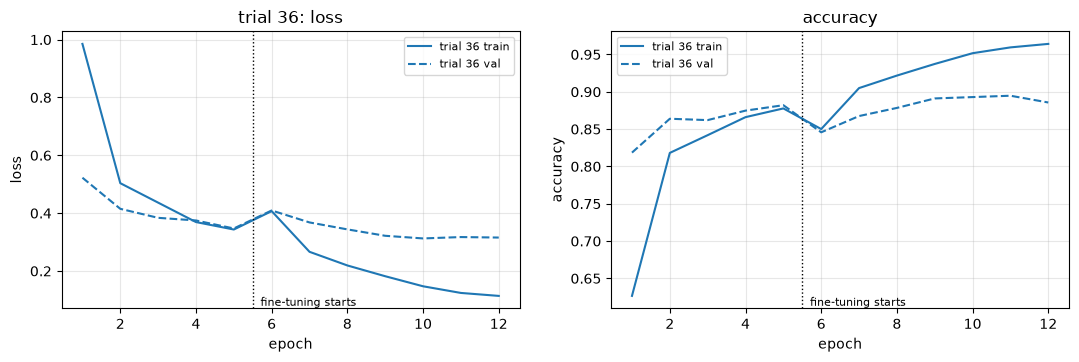

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s  ← your entry
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
   35       25      adam    5e-05      6  True  1,368,325   0.895    0.304    67s
   29       25      adam    6e-05      6  True  1,368,325   0.893    0.316    59s
   36       25      adam    6e-05      7  True  1,368,325   0.893    0.313    69s
    3       60   rmsprop    5e-05      6  True  1,962,117   0.891    0.349    62s
   18       30   rmsprop    4e-05      6  True  1,532,805   0.891    0.297    60s
  

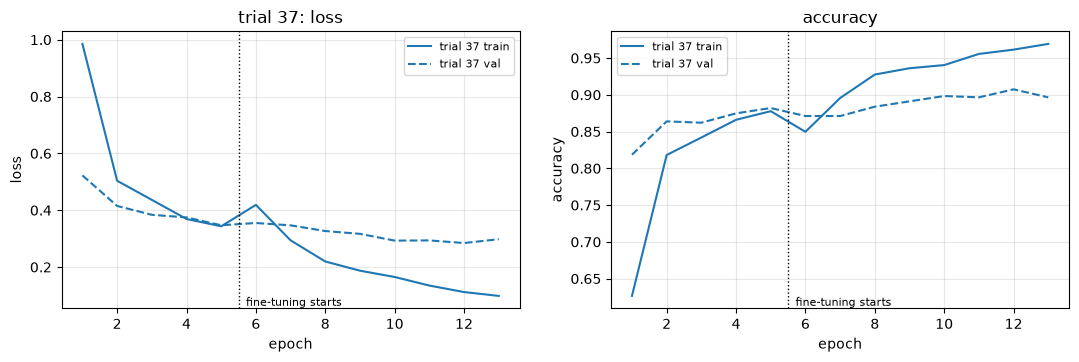

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
   35       25      adam    5e-05      6  True  1,368,325   0.895    0.304    67s
   29       25      adam    6e-05      6  True  1,368,325   0.893    0.316    59s
   36       25      adam    6e-05      7  True  1,368,325   0.893    0.313    69s
    3       60   rmsprop    5e-05      6  True  1,962,117   0.891    0.349    62s
  

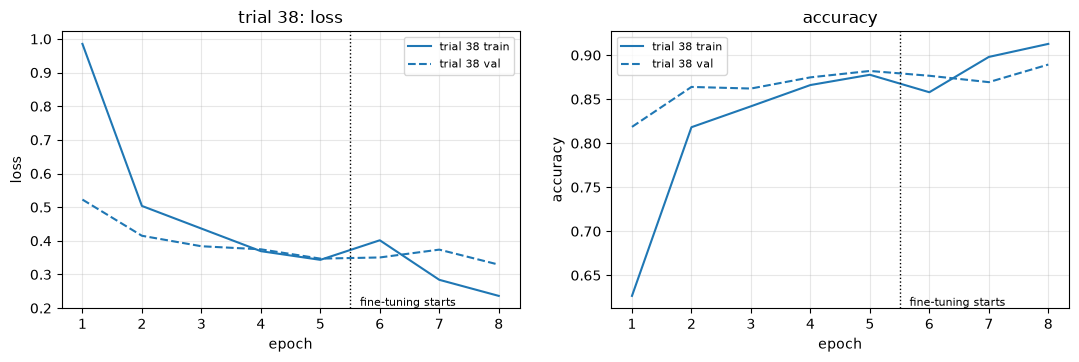

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
   35       25      adam    5e-05      6  True  1,368,325   0.895    0.304    67s
   29       25      adam    6e-05      6  True  1,368,325   0.893    0.316    59s
   36       25      adam    6e-05      7  True  1,368,325   0.893    0.313    69s
    3       60   rmsprop    5e-05      6  True  1,962,117   0.891    0.349    62s
  

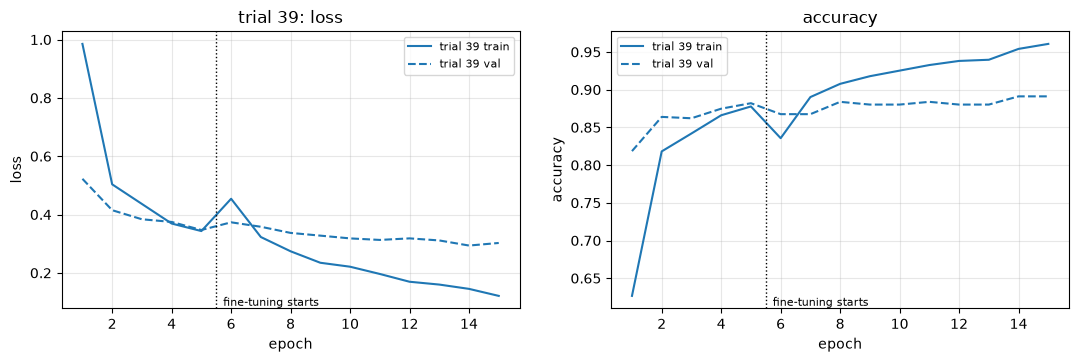

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
   35       25      adam    5e-05      6  True  1,368,325   0.895    0.304    67s
   29       25      adam    6e-05      6  True  1,368,325   0.893    0.316    59s
   36       25      adam    6e-05      7  True  1,368,325   0.893    0.313    69s
    3       60   rmsprop    5e-05      6  True  1,962,117   0.891    0.349    62s
  

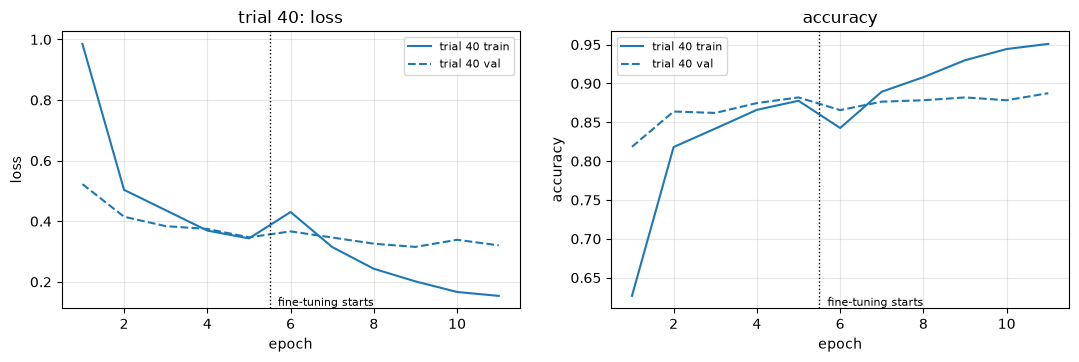

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
   35       25      adam    5e-05      6  True  1,368,325   0.895    0.304    67s
   29       25      adam    6e-05      6  True  1,368,325   0.893    0.316    59s
   36       25      adam    6e-05      7  True  1,368,325   0.893    0.313    69s
    3       60   rmsprop    5e-05      6  True  1,962,117   0.891    0.349    62s
  

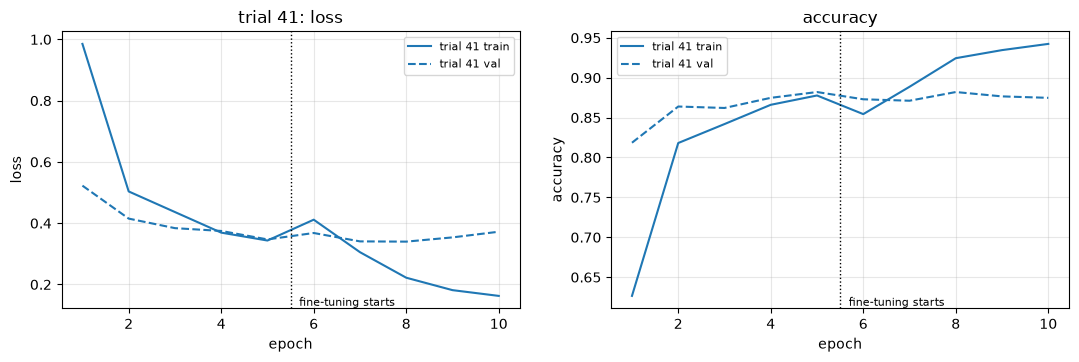

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
   35       25      adam    5e-05      6  True  1,368,325   0.895    0.304    67s
   29       25      adam    6e-05      6  True  1,368,325   0.893    0.316    59s
   36       25      adam    6e-05      7  True  1,368,325   0.893    0.313    69s
    3       60   rmsprop    5e-05      6  True  1,962,117   0.891    0.349    62s
  

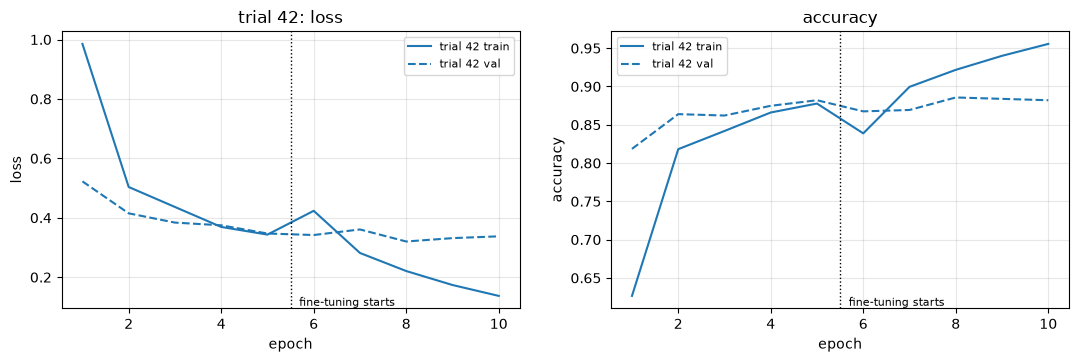

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
   35       25      adam    5e-05      6  True  1,368,325   0.895    0.304    67s
   29       25      adam    6e-05      6  True  1,368,325   0.893    0.316    59s
   36       25      adam    6e-05      7  True  1,368,325   0.893    0.313    69s
    3       60   rmsprop    5e-05      6  True  1,962,117   0.891    0.349    62s
  

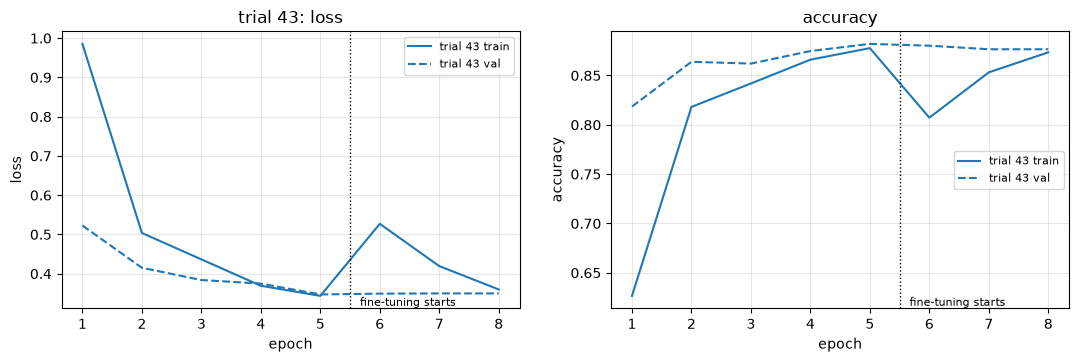

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
   35       25      adam    5e-05      6  True  1,368,325   0.895    0.304    67s
   29       25      adam    6e-05      6  True  1,368,325   0.893    0.316    59s
   36       25      adam    6e-05      7  True  1,368,325   0.893    0.313    69s
    3       60   rmsprop    5e-05      6  True  1,962,117   0.891    0.349    62s
  

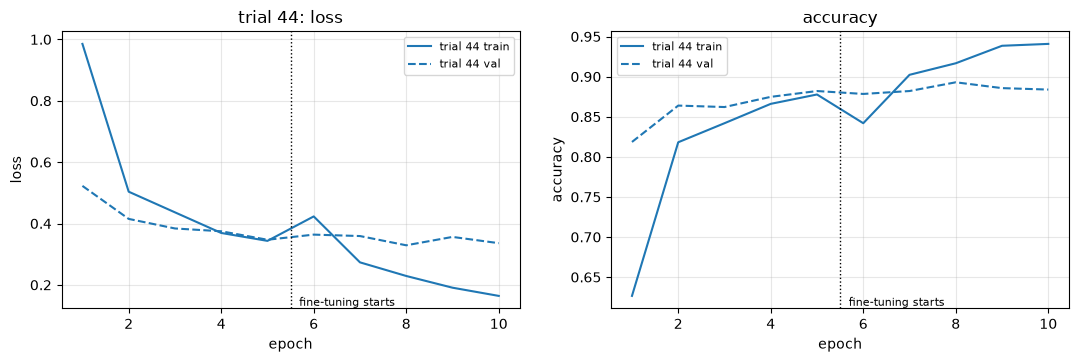

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
   35       25      adam    5e-05      6  True  1,368,325   0.895    0.304    67s
   29       25      adam    6e-05      6  True  1,368,325   0.893    0.316    59s
   36       25      adam    6e-05      7  True  1,368,325   0.893    0.313    69s
   44       25      adam    5e-05      5  True  1,368,325   0.893    0.329    48s
  

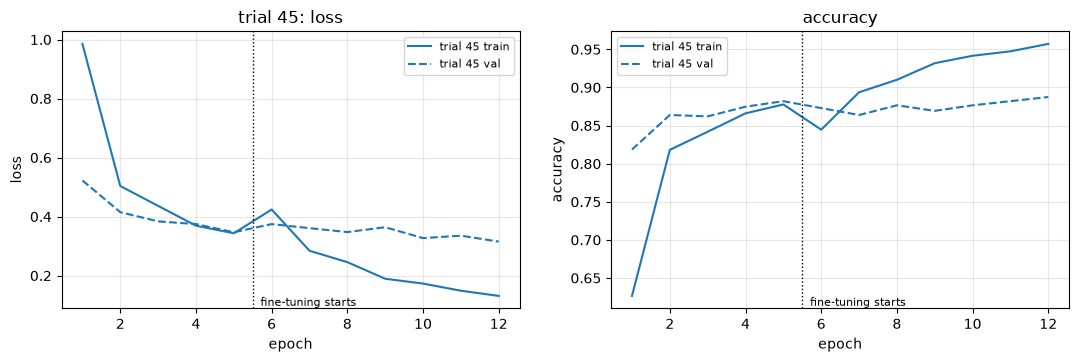

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
   35       25      adam    5e-05      6  True  1,368,325   0.895    0.304    67s
   29       25      adam    6e-05      6  True  1,368,325   0.893    0.316    59s
   36       25      adam    6e-05      7  True  1,368,325   0.893    0.313    69s
   44       25      adam    5e-05      5  True  1,368,325   0.893    0.329    48s
  

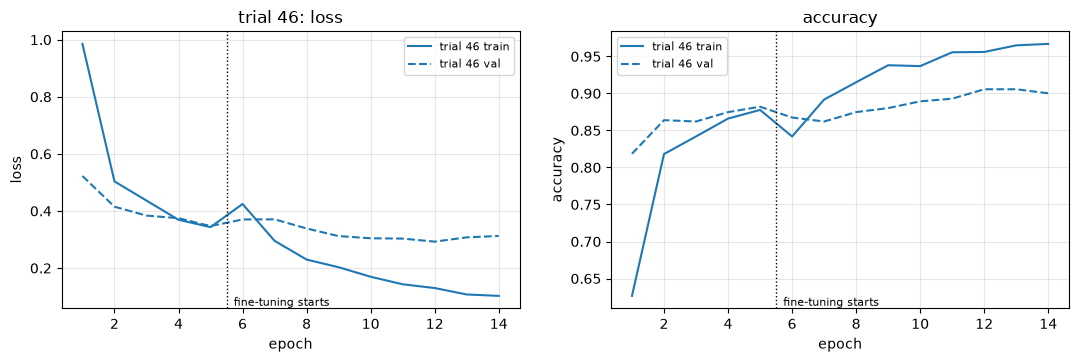

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
   35       25      adam    5e-05      6  True  1,368,325   0.895    0.304    67s
   29       25      adam    6e-05      6  True  1,368,325   0.893    0.316    59s
   36       25      adam    6e-05      7  True  1,368,325   0.893    0.313    69s
  

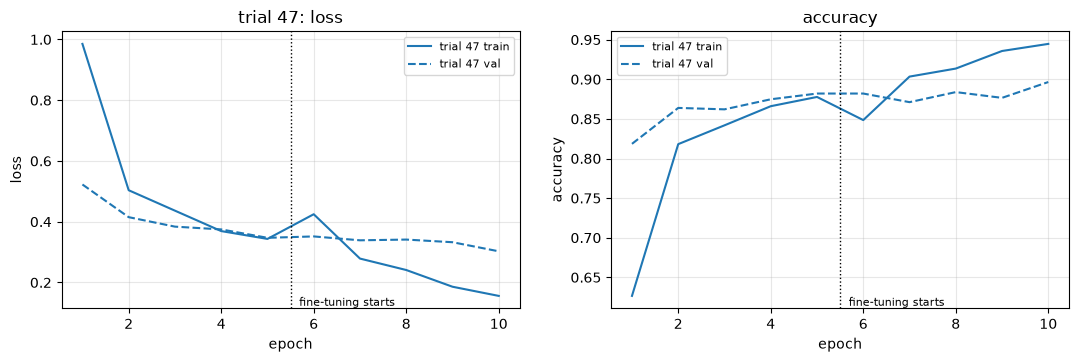

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
   47       23      adam    5e-05      5  True  1,366,405   0.897    0.303    50s
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
   35       25      adam    5e-05      6  True  1,368,325   0.895    0.304    67s
   29       25      adam    6e-05      6  True  1,368,325   0.893    0.316    59s
  

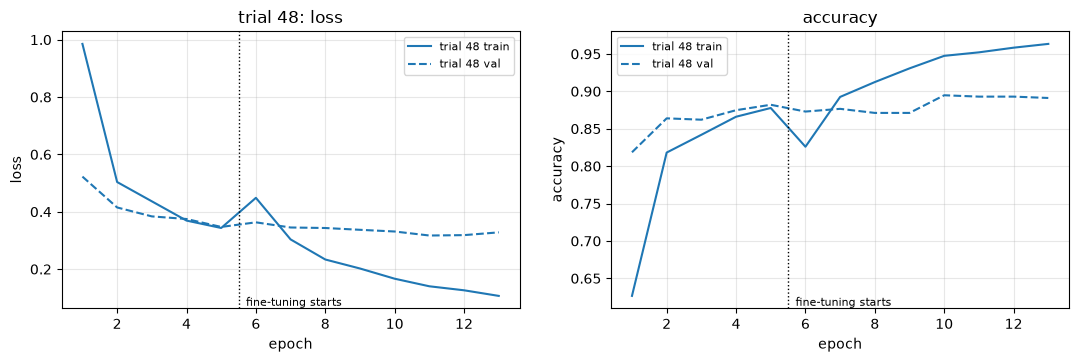

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
   47       23      adam    5e-05      5  True  1,366,405   0.897    0.303    50s
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
   35       25      adam    5e-05      6  True  1,368,325   0.895    0.304    67s
   29       25      adam    6e-05      6  True  1,368,325   0.893    0.316    59s
  

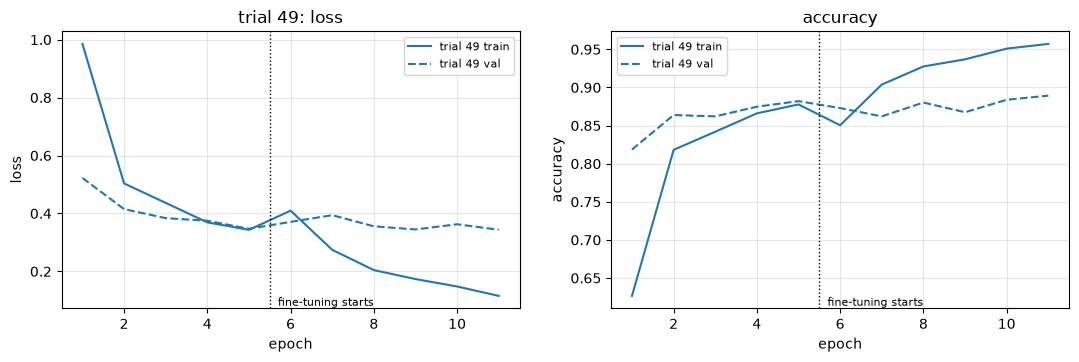

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
   47       23      adam    5e-05      5  True  1,366,405   0.897    0.303    50s
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
   35       25      adam    5e-05      6  True  1,368,325   0.895    0.304    67s
   29       25      adam    6e-05      6  True  1,368,325   0.893    0.316    59s
  

/mnt/e/BSCS 4th Year/CSC173/nasayao-csc173-repository/.local-finetune/tf-env/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Could not load symbol cuStreamGetGreenCtx. Error: /usr/lib/wsl/lib/libcuda.so.1: undefined symbol: cuStreamGetGreenCtx


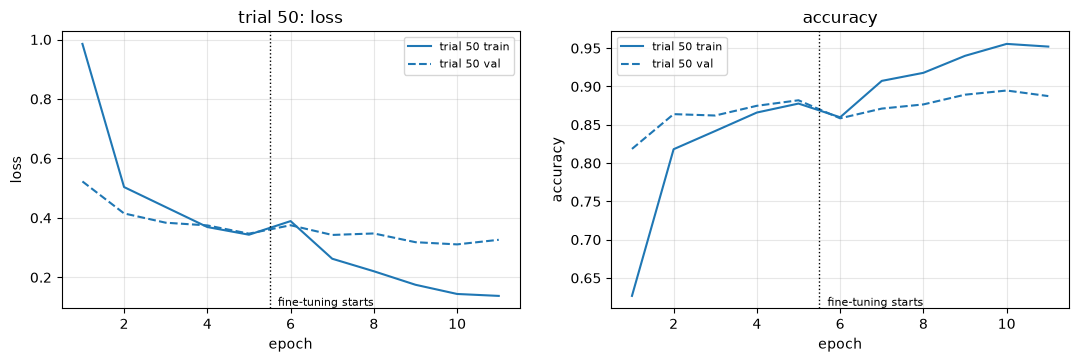

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
   47       23      adam    5e-05      5  True  1,366,405   0.897    0.303    50s
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
   35       25      adam    5e-05      6  True  1,368,325   0.895    0.304    67s
   50       23      adam    5e-05      6  True  1,366,405   0.895    0.311   163s
  

23025

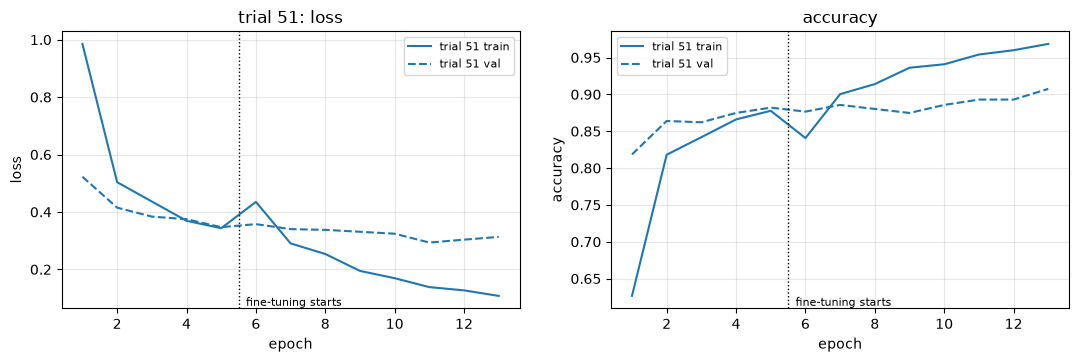

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
   47       23      adam    5e-05      5  True  1,366,405   0.897    0.303    50s
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
   35       25      adam    5e-05      6  True  1,368,325   0.895    0.304    67s
   50       23      adam    5e-05      6  True  1,366,405   0.895    0.311   163s
  

23240

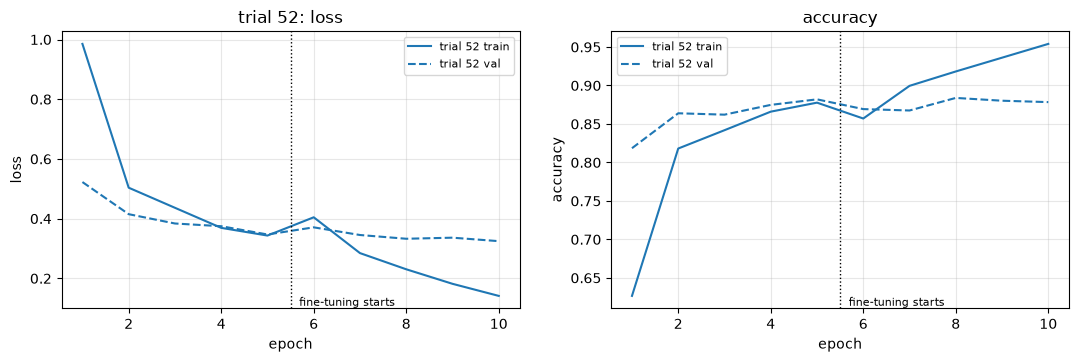

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
   47       23      adam    5e-05      5  True  1,366,405   0.897    0.303    50s
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
   35       25      adam    5e-05      6  True  1,368,325   0.895    0.304    67s
   50       23      adam    5e-05      6  True  1,366,405   0.895    0.311   163s
  

23052

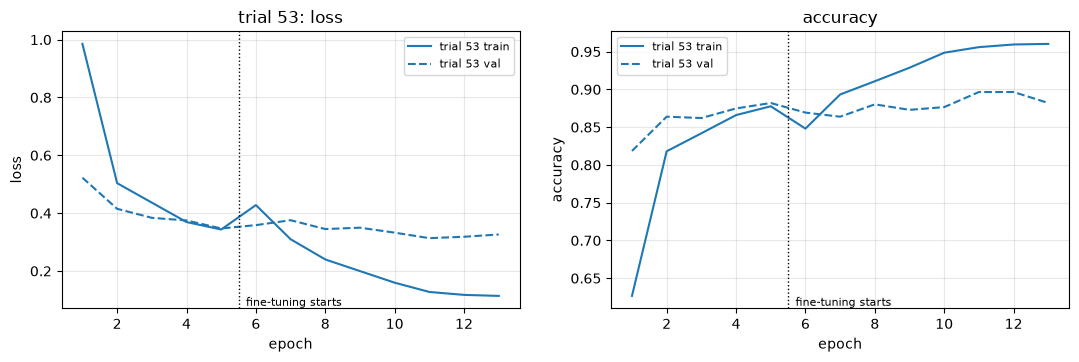

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   53       27      adam    5e-05      8  True  1,376,965   0.897    0.313    74s
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
   47       23      adam    5e-05      5  True  1,366,405   0.897    0.303    50s
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
   35       25      adam    5e-05      6  True  1,368,325   0.895    0.304    67s
  

23240

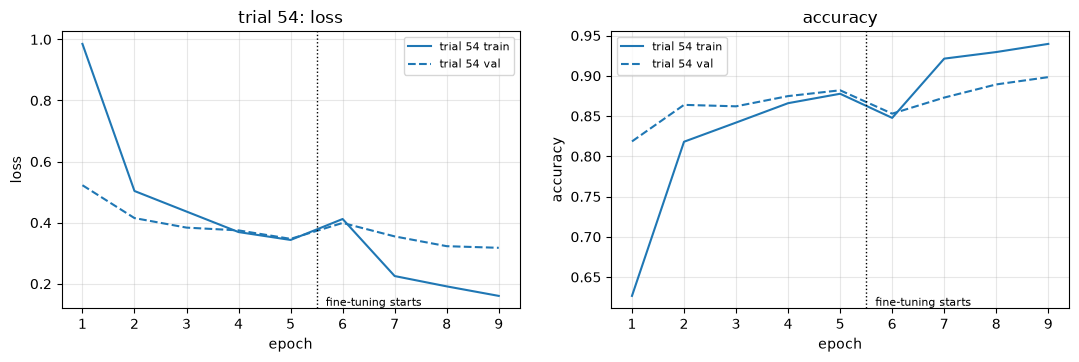

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   53       27      adam    5e-05      8  True  1,376,965   0.897    0.313    74s
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
   47       23      adam    5e-05      5  True  1,366,405   0.897    0.303    50s
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
  

23778

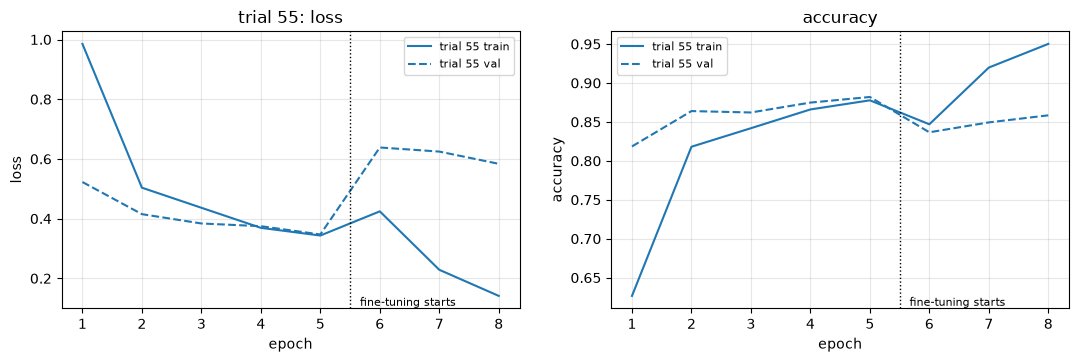

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   53       27      adam    5e-05      8  True  1,376,965   0.897    0.313    74s
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
   47       23      adam    5e-05      5  True  1,366,405   0.897    0.303    50s
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
  

23714

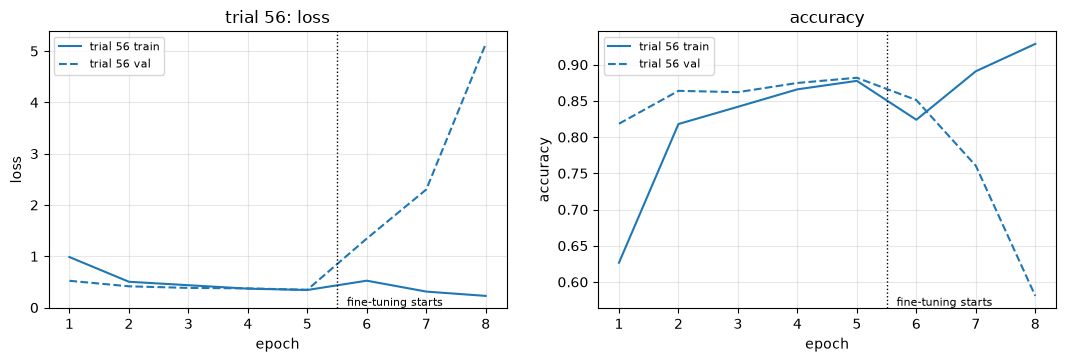

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   53       27      adam    5e-05      8  True  1,376,965   0.897    0.313    74s
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
   47       23      adam    5e-05      5  True  1,366,405   0.897    0.303    50s
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
  

23825

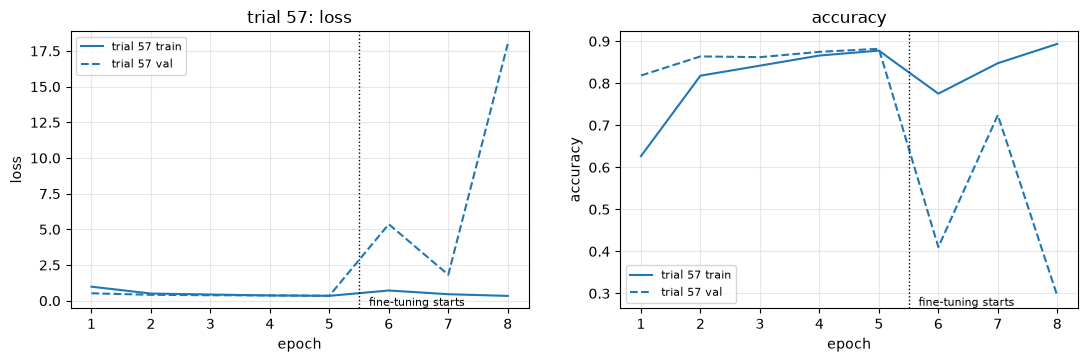

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   53       27      adam    5e-05      8  True  1,376,965   0.897    0.313    74s
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
   47       23      adam    5e-05      5  True  1,366,405   0.897    0.303    50s
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
  

23841

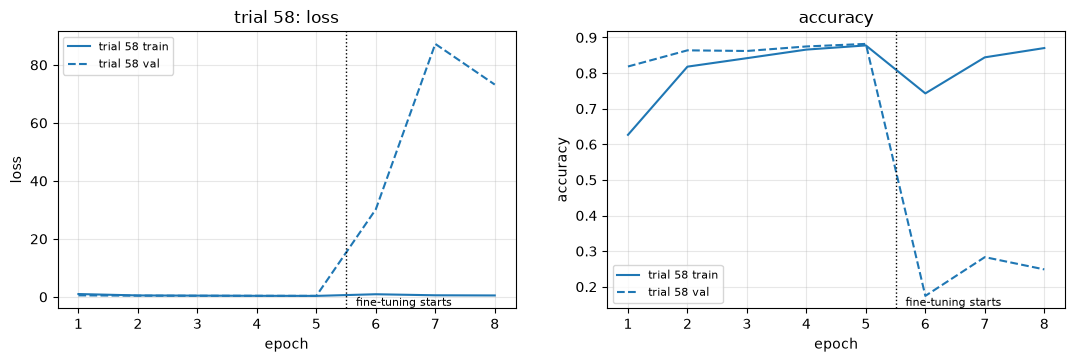

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   53       27      adam    5e-05      8  True  1,376,965   0.897    0.313    74s
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
   47       23      adam    5e-05      5  True  1,366,405   0.897    0.303    50s
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
  

23822

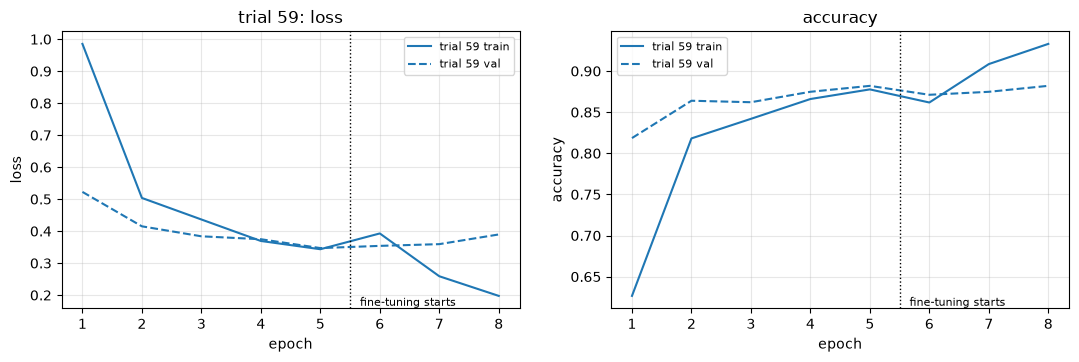

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   53       27      adam    5e-05      8  True  1,376,965   0.897    0.313    74s
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
   47       23      adam    5e-05      5  True  1,366,405   0.897    0.303    50s
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
  

23395

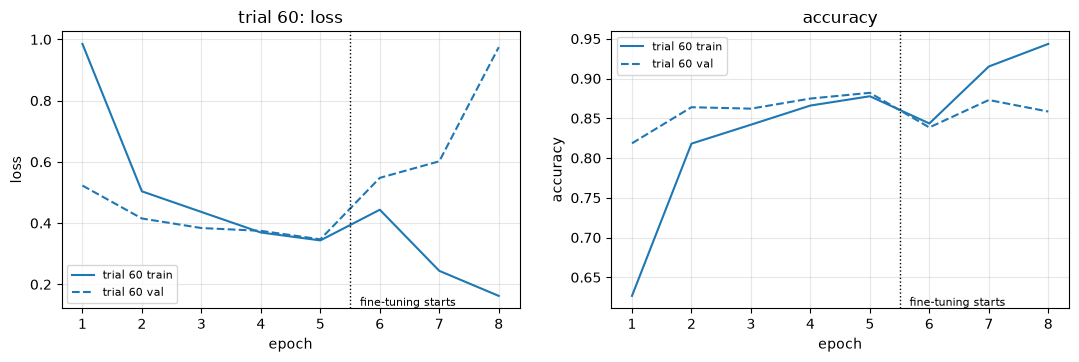

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   53       27      adam    5e-05      8  True  1,376,965   0.897    0.313    74s
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
   47       23      adam    5e-05      5  True  1,366,405   0.897    0.303    50s
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
  

23240

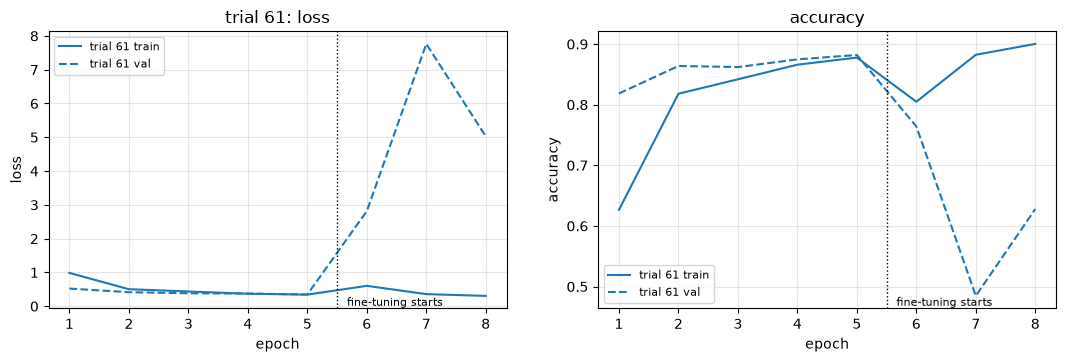

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   53       27      adam    5e-05      8  True  1,376,965   0.897    0.313    74s
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
   47       23      adam    5e-05      5  True  1,366,405   0.897    0.303    50s
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
  

23269

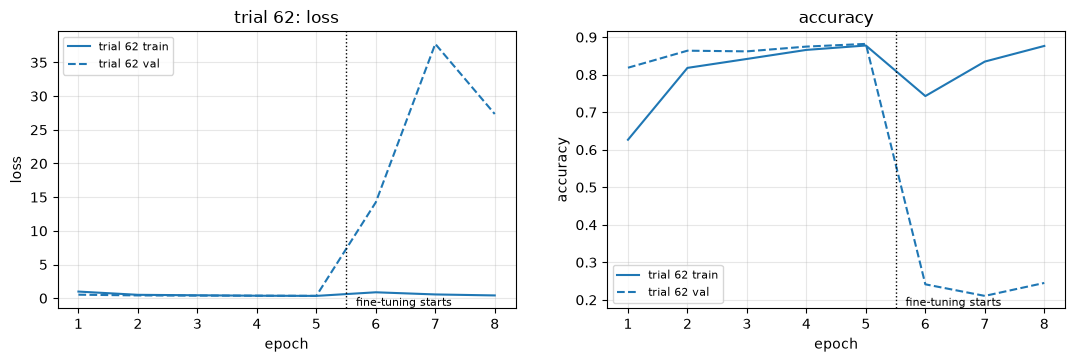

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   53       27      adam    5e-05      8  True  1,376,965   0.897    0.313    74s
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
   47       23      adam    5e-05      5  True  1,366,405   0.897    0.303    50s
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
  

23480

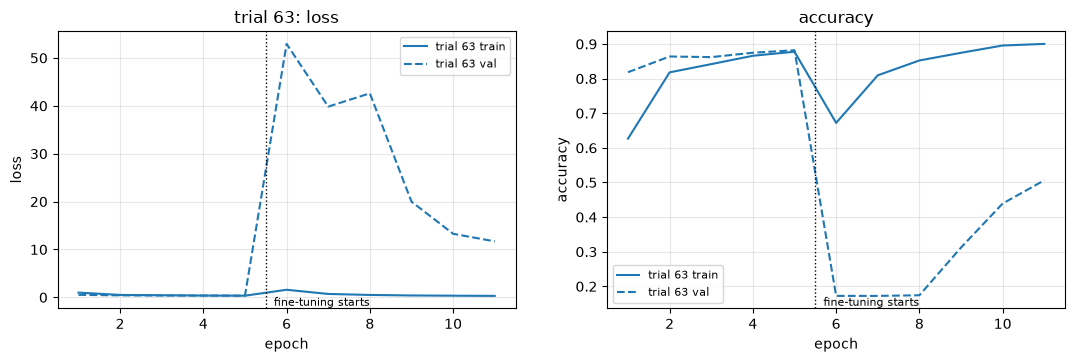

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   53       27      adam    5e-05      8  True  1,376,965   0.897    0.313    74s
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
   47       23      adam    5e-05      5  True  1,366,405   0.897    0.303    50s
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
  

22883

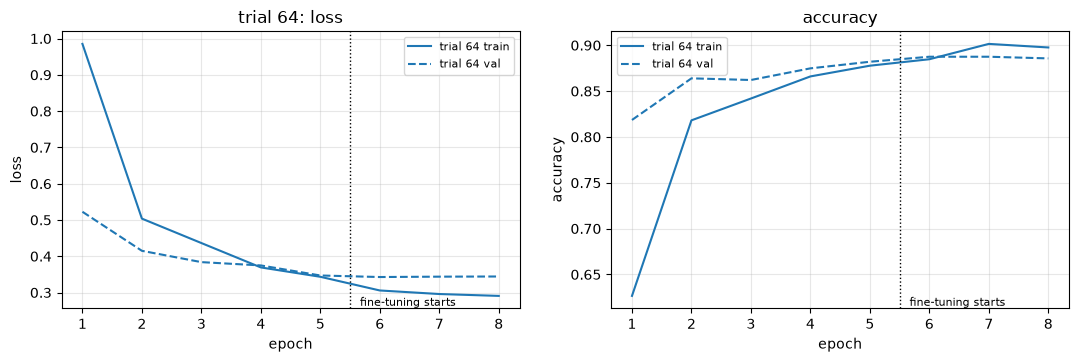

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   53       27      adam    5e-05      8  True  1,376,965   0.897    0.313    74s
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
   47       23      adam    5e-05      5  True  1,366,405   0.897    0.303    50s
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
  

22899

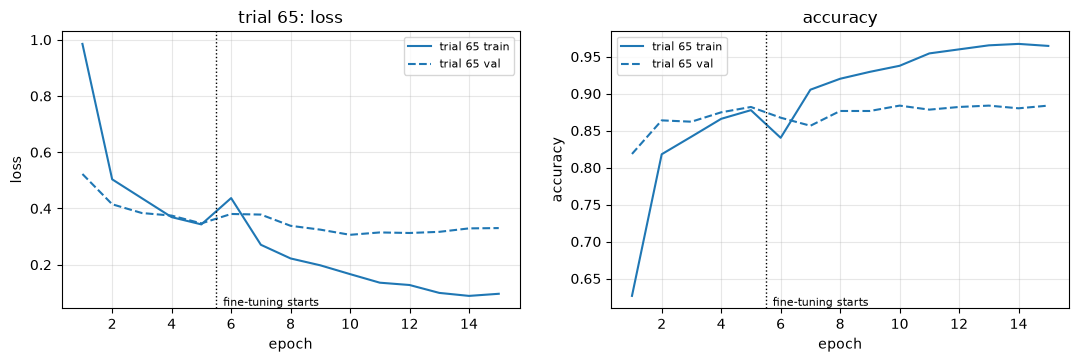

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   53       27      adam    5e-05      8  True  1,376,965   0.897    0.313    74s
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
   47       23      adam    5e-05      5  True  1,366,405   0.897    0.303    50s
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
   20       30   rmsprop    3e-05      5  True  1,532,805   0.895    0.306    46s
  

23407

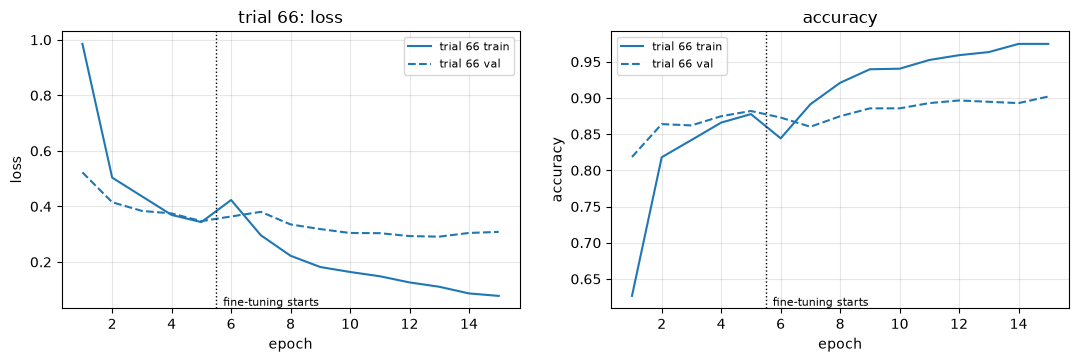

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   66       25      adam    5e-05     10 False  1,368,325   0.902    0.308    87s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   53       27      adam    5e-05      8  True  1,376,965   0.897    0.313    74s
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
   47       23      adam    5e-05      5  True  1,366,405   0.897    0.303    50s
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
  

23407

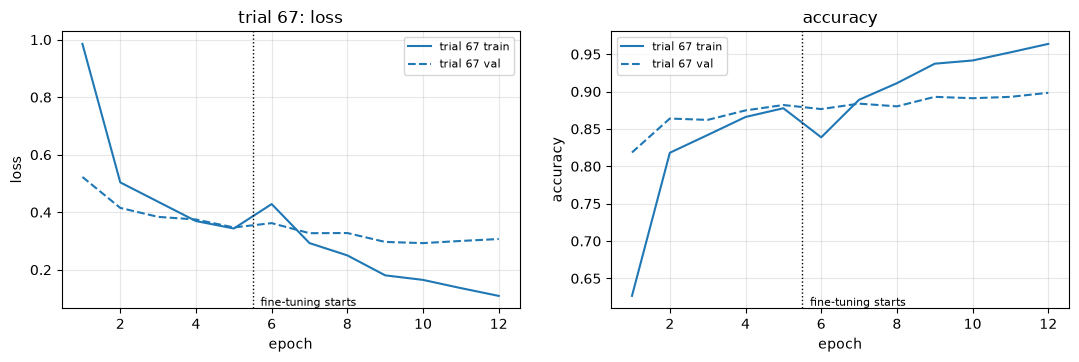

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   66       25      adam    5e-05     10 False  1,368,325   0.902    0.308    87s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   53       27      adam    5e-05      8  True  1,376,965   0.897    0.313    74s
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
   47       23      adam    5e-05      5  True  1,366,405   0.897    0.303    50s
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s
   17       50      adam    4e-05      6  True  1,861,509   0.895    0.310    71s
  

23155

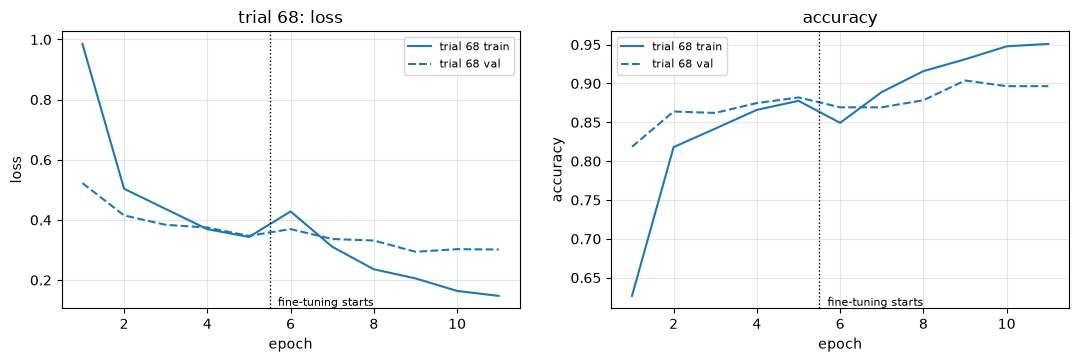

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   68       25      adam    5e-05      6  True  1,368,325   0.904    0.294    56s
   66       25      adam    5e-05     10 False  1,368,325   0.902    0.308    87s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   53       27      adam    5e-05      8  True  1,376,965   0.897    0.313    74s
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
   47       23      adam    5e-05      5  True  1,366,405   0.897    0.303    50s
    9       30      adam    3e-05      8  True  1,532,805   0.895    0.314    82s
  

23135

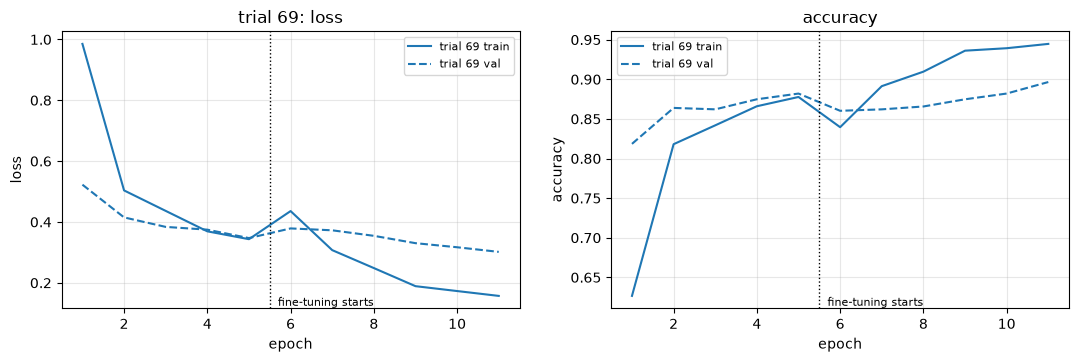

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   68       25      adam    5e-05      6  True  1,368,325   0.904    0.294    56s
   66       25      adam    5e-05     10 False  1,368,325   0.902    0.308    87s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   53       27      adam    5e-05      8  True  1,376,965   0.897    0.313    74s
   69       25      adam    5e-05      6  True  1,368,325   0.897    0.302    57s
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
   47       23      adam    5e-05      5  True  1,366,405   0.897    0.303    50s
  

23135

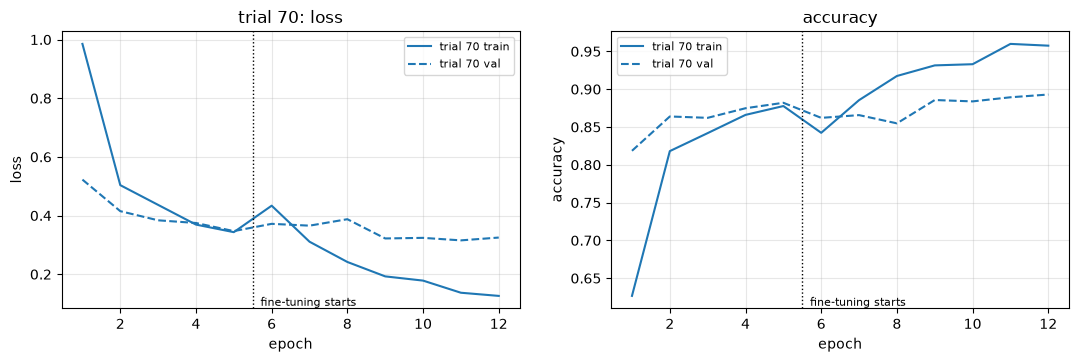

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   68       25      adam    5e-05      6  True  1,368,325   0.904    0.294    56s
   66       25      adam    5e-05     10 False  1,368,325   0.902    0.308    87s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   53       27      adam    5e-05      8  True  1,376,965   0.897    0.313    74s
   69       25      adam    5e-05      6  True  1,368,325   0.897    0.302    57s
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
   47       23      adam    5e-05      5  True  1,366,405   0.897    0.303    50s
  

23116

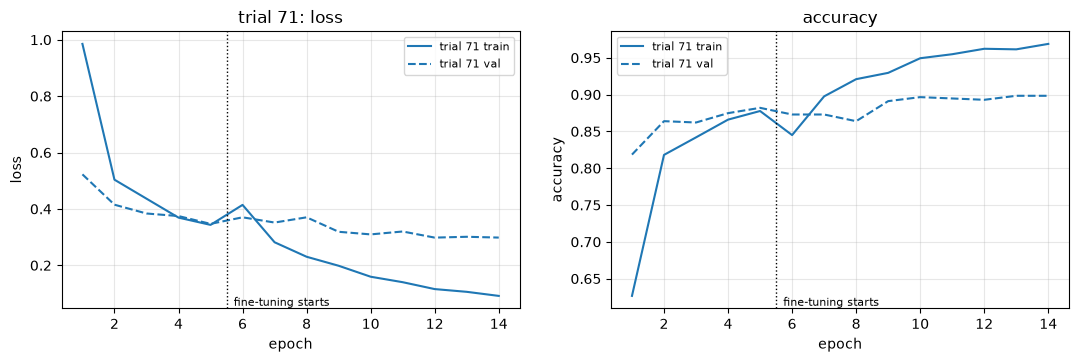

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   68       25      adam    5e-05      6  True  1,368,325   0.904    0.294    56s
   66       25      adam    5e-05     10 False  1,368,325   0.902    0.308    87s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   53       27      adam    5e-05      8  True  1,376,965   0.897    0.313    74s
   69       25      adam    5e-05      6  True  1,368,325   0.897    0.302    57s
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
   47       23      adam    5e-05      5  True  1,366,405   0.897    0.303    50s
  

23406

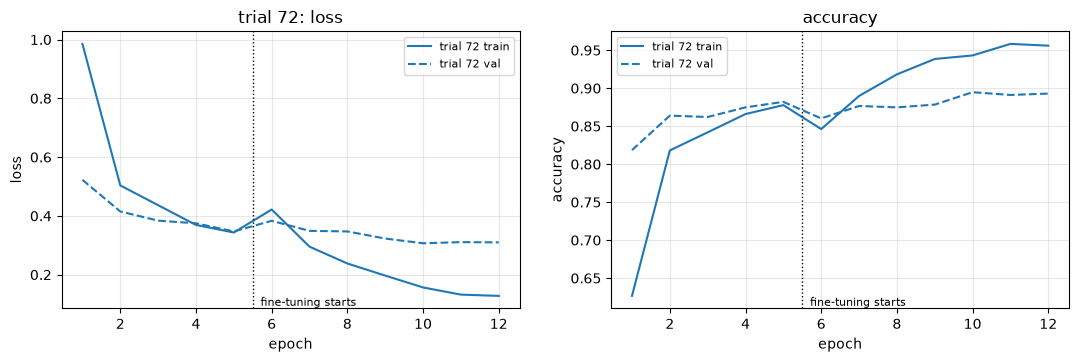

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   68       25      adam    5e-05      6  True  1,368,325   0.904    0.294    56s
   66       25      adam    5e-05     10 False  1,368,325   0.902    0.308    87s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   53       27      adam    5e-05      8  True  1,376,965   0.897    0.313    74s
   69       25      adam    5e-05      6  True  1,368,325   0.897    0.302    57s
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
   47       23      adam    5e-05      5  True  1,366,405   0.897    0.303    50s
  

23116

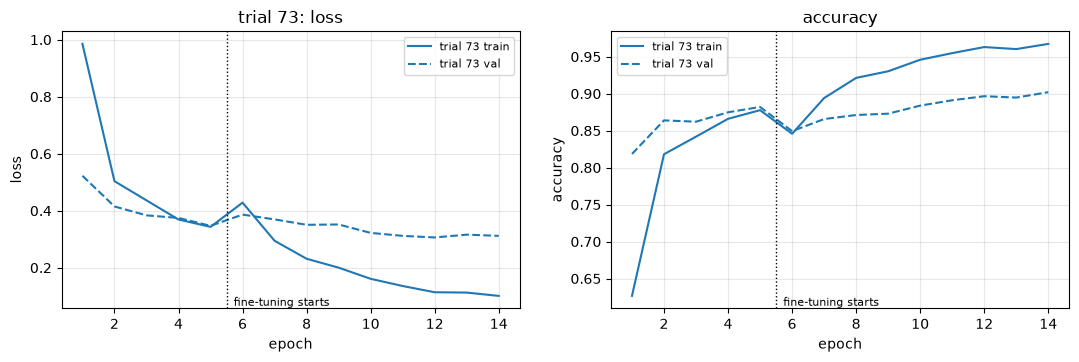

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   68       25      adam    5e-05      6  True  1,368,325   0.904    0.294    56s
   66       25      adam    5e-05     10 False  1,368,325   0.902    0.308    87s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   53       27      adam    5e-05      8  True  1,376,965   0.897    0.313    74s
   69       25      adam    5e-05      6  True  1,368,325   0.897    0.302    57s
   73       25      adam    5e-05      9  True  1,368,325   0.897    0.306    79s
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
  

23406

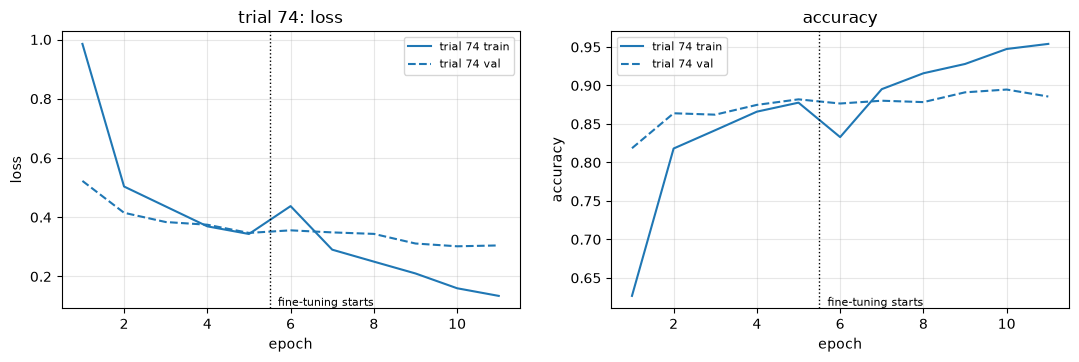

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   68       25      adam    5e-05      6  True  1,368,325   0.904    0.294    56s
   66       25      adam    5e-05     10 False  1,368,325   0.902    0.308    87s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   53       27      adam    5e-05      8  True  1,376,965   0.897    0.313    74s
   69       25      adam    5e-05      6  True  1,368,325   0.897    0.302    57s
   73       25      adam    5e-05      9  True  1,368,325   0.897    0.306    79s
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
  

23135

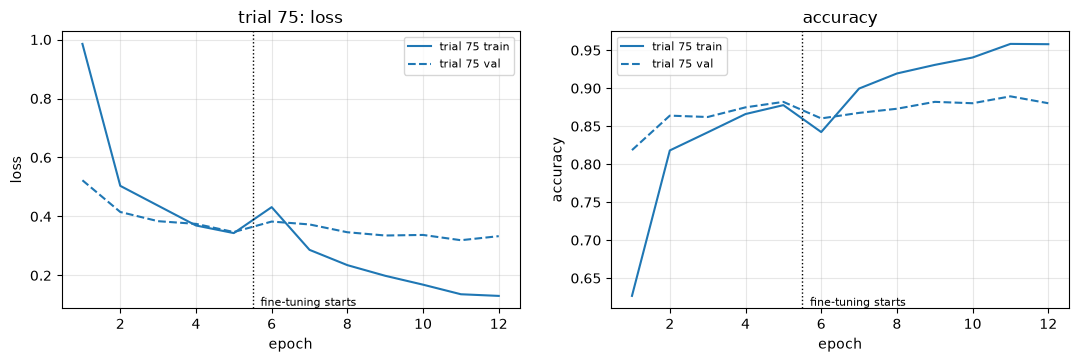

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   68       25      adam    5e-05      6  True  1,368,325   0.904    0.294    56s
   66       25      adam    5e-05     10 False  1,368,325   0.902    0.308    87s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   53       27      adam    5e-05      8  True  1,376,965   0.897    0.313    74s
   69       25      adam    5e-05      6  True  1,368,325   0.897    0.302    57s
   73       25      adam    5e-05      9  True  1,368,325   0.897    0.306    79s
   25       30      adam    6e-05      7  True  1,532,805   0.897    0.304    95s
  

23116

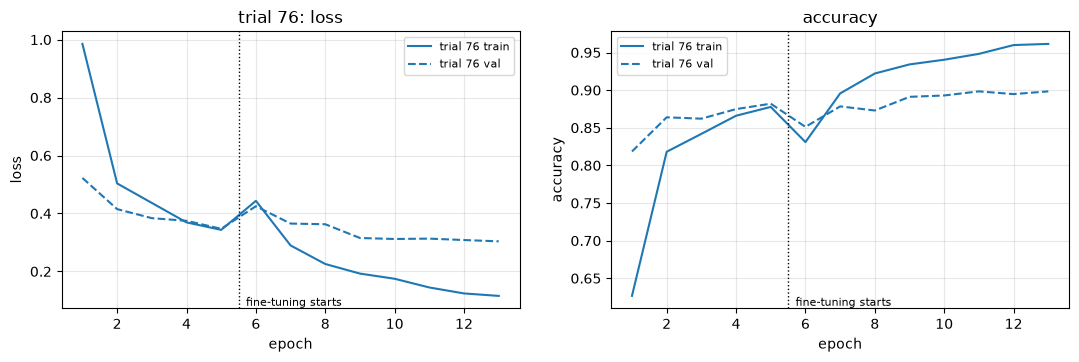

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   68       25      adam    5e-05      6  True  1,368,325   0.904    0.294    56s
   66       25      adam    5e-05     10 False  1,368,325   0.902    0.308    87s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   76       25      adam    5e-05      8  True  1,368,325   0.898    0.304    71s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   53       27      adam    5e-05      8  True  1,376,965   0.897    0.313    74s
   69       25      adam    5e-05      6  True  1,368,325   0.897    0.302    57s
   73       25      adam    5e-05      9  True  1,368,325   0.897    0.306    79s
  

23196

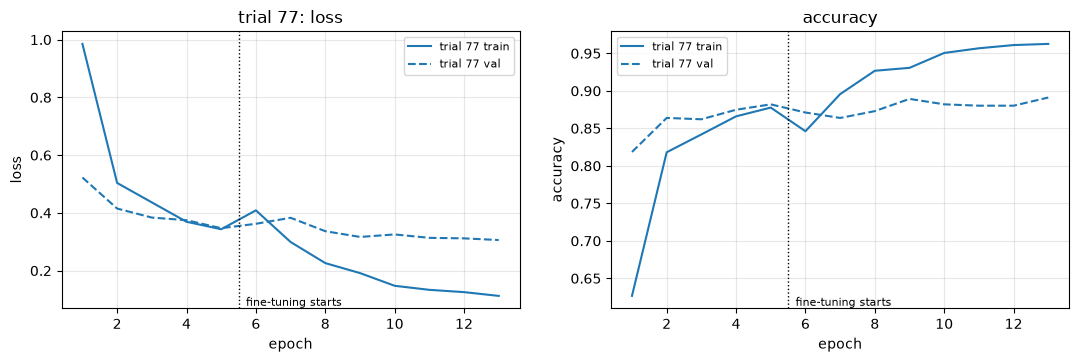

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   68       25      adam    5e-05      6  True  1,368,325   0.904    0.294    56s
   66       25      adam    5e-05     10 False  1,368,325   0.902    0.308    87s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   76       25      adam    5e-05      8  True  1,368,325   0.898    0.304    71s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   53       27      adam    5e-05      8  True  1,376,965   0.897    0.313    74s
   69       25      adam    5e-05      6  True  1,368,325   0.897    0.302    57s
   73       25      adam    5e-05      9  True  1,368,325   0.897    0.306    79s
  

23196

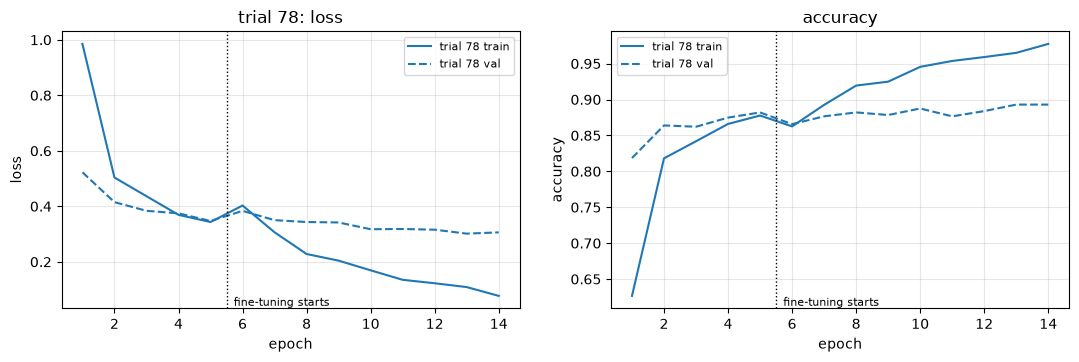

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   68       25      adam    5e-05      6  True  1,368,325   0.904    0.294    56s
   66       25      adam    5e-05     10 False  1,368,325   0.902    0.308    87s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   76       25      adam    5e-05      8  True  1,368,325   0.898    0.304    71s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   53       27      adam    5e-05      8  True  1,376,965   0.897    0.313    74s
   69       25      adam    5e-05      6  True  1,368,325   0.897    0.302    57s
   73       25      adam    5e-05      9  True  1,368,325   0.897    0.306    79s
  

23406

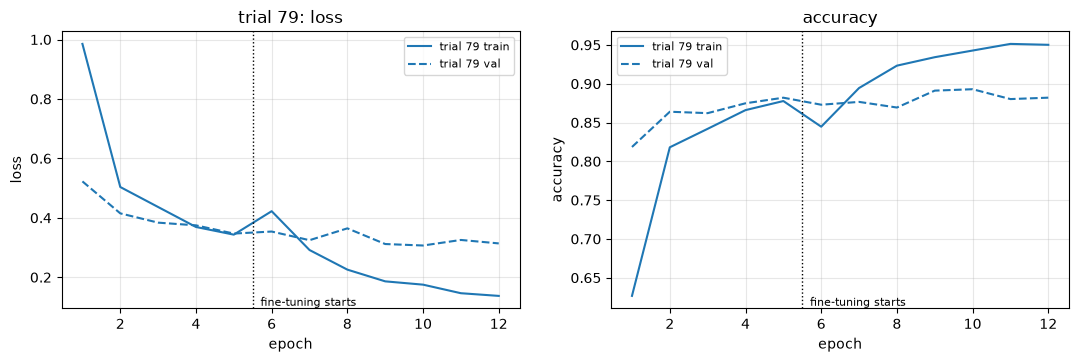

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   68       25      adam    5e-05      6  True  1,368,325   0.904    0.294    56s
   66       25      adam    5e-05     10 False  1,368,325   0.902    0.308    87s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   76       25      adam    5e-05      8  True  1,368,325   0.898    0.304    71s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   53       27      adam    5e-05      8  True  1,376,965   0.897    0.313    74s
   69       25      adam    5e-05      6  True  1,368,325   0.897    0.302    57s
   73       25      adam    5e-05      9  True  1,368,325   0.897    0.306    79s
  

23116

W0000 00:00:1795715806.948946    8721 prefetch_autotuner.cc:55] Prefetch autotuner tried to allocate 9830656 bytes after encountering the first element of size 9830656 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


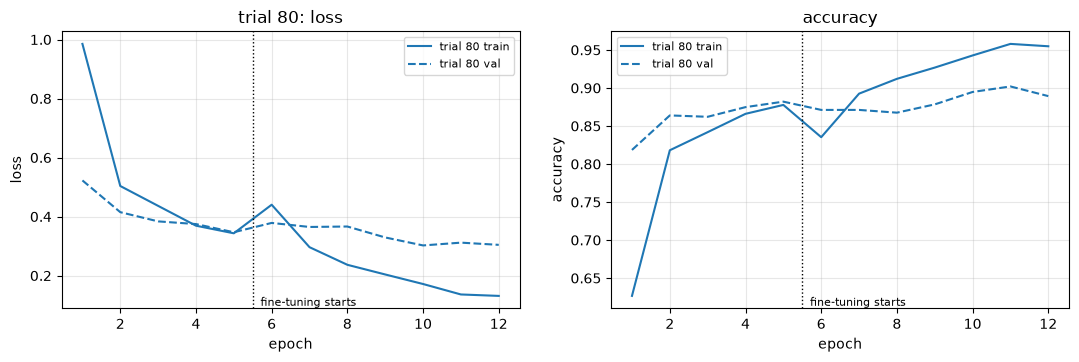

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   68       25      adam    5e-05      6  True  1,368,325   0.904    0.294    56s
   66       25      adam    5e-05     10 False  1,368,325   0.902    0.308    87s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   76       25      adam    5e-05      8  True  1,368,325   0.898    0.304    71s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   53       27      adam    5e-05      8  True  1,376,965   0.897    0.313    74s
   69       25      adam    5e-05      6  True  1,368,325   0.897    0.302    57s
   73       25      adam    5e-05      9  True  1,368,325   0.897    0.306    79s
  

23116

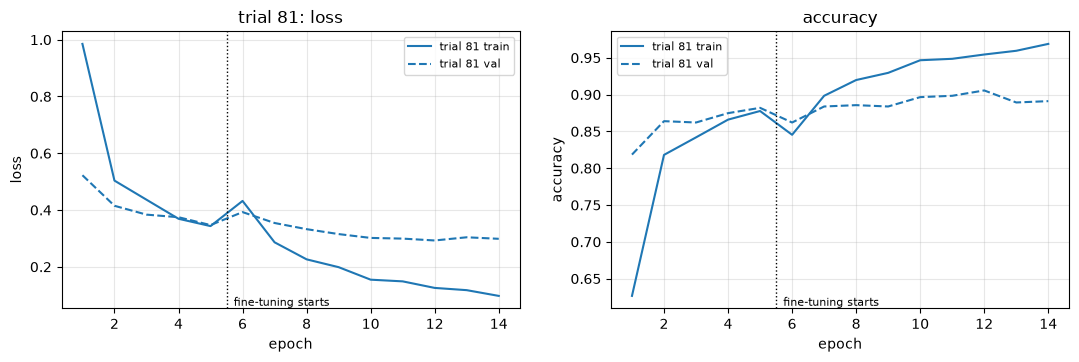

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   81       25      adam    5e-05      9  True  1,368,325   0.906    0.293    79s
   68       25      adam    5e-05      6  True  1,368,325   0.904    0.294    56s
   66       25      adam    5e-05     10 False  1,368,325   0.902    0.308    87s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   76       25      adam    5e-05      8  True  1,368,325   0.898    0.304    71s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   53       27      adam    5e-05      8  True  1,376,965   0.897    0.313    74s
   69       25      adam    5e-05      6  True  1,368,325   0.897    0.302    57s
  

23406

W0000 00:00:1795715960.888341    9373 prefetch_autotuner.cc:55] Prefetch autotuner tried to allocate 9830656 bytes after encountering the first element of size 9830656 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


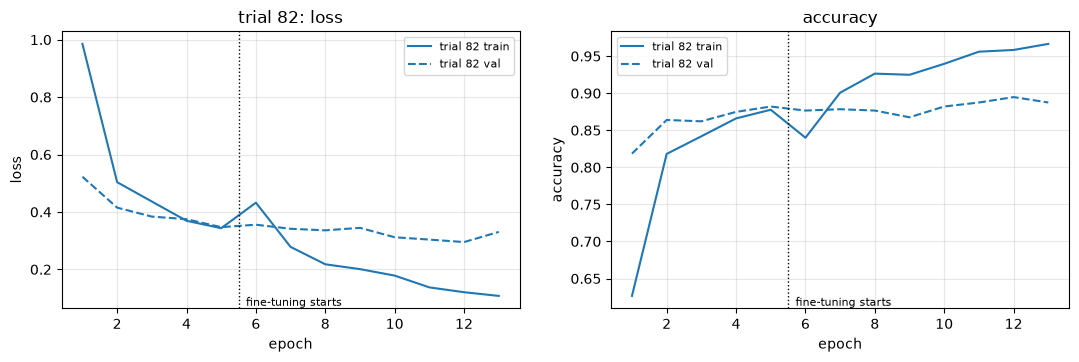

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   81       25      adam    5e-05      9  True  1,368,325   0.906    0.293    79s
   68       25      adam    5e-05      6  True  1,368,325   0.904    0.294    56s
   66       25      adam    5e-05     10 False  1,368,325   0.902    0.308    87s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   76       25      adam    5e-05      8  True  1,368,325   0.898    0.304    71s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   53       27      adam    5e-05      8  True  1,376,965   0.897    0.313    74s
   69       25      adam    5e-05      6  True  1,368,325   0.897    0.302    57s
  

23196

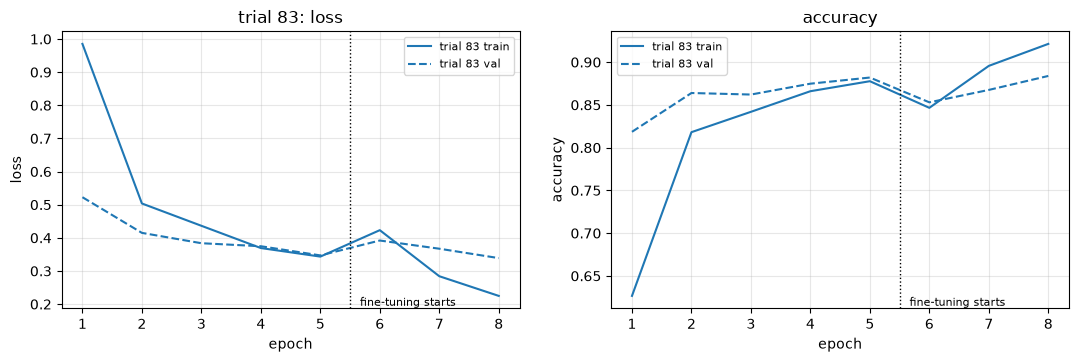

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   81       25      adam    5e-05      9  True  1,368,325   0.906    0.293    79s
   68       25      adam    5e-05      6  True  1,368,325   0.904    0.294    56s
   66       25      adam    5e-05     10 False  1,368,325   0.902    0.308    87s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   76       25      adam    5e-05      8  True  1,368,325   0.898    0.304    71s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   53       27      adam    5e-05      8  True  1,376,965   0.897    0.313    74s
   69       25      adam    5e-05      6  True  1,368,325   0.897    0.302    57s
  

23841

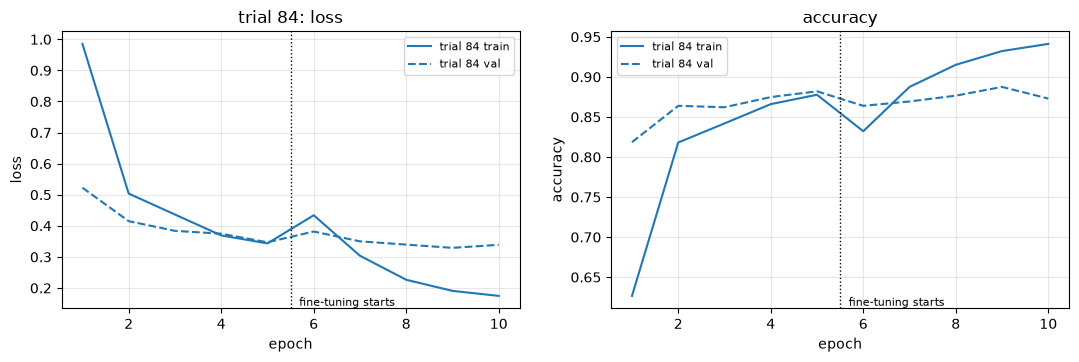

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s  ← your entry
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   81       25      adam    5e-05      9  True  1,368,325   0.906    0.293    79s
   68       25      adam    5e-05      6  True  1,368,325   0.904    0.294    56s
   66       25      adam    5e-05     10 False  1,368,325   0.902    0.308    87s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   76       25      adam    5e-05      8  True  1,368,325   0.898    0.304    71s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   53       27      adam    5e-05      8  True  1,376,965   0.897    0.313    74s
   69       25      adam    5e-05      6  True  1,368,325   0.897    0.302    57s
  

23549

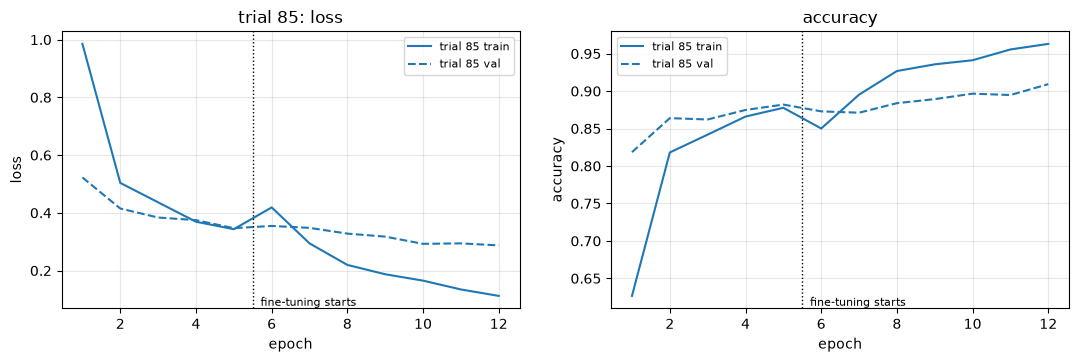

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   85       25      adam    5e-05      7  True  1,368,325   0.909    0.287    76s  ← your entry
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   81       25      adam    5e-05      9  True  1,368,325   0.906    0.293    79s
   68       25      adam    5e-05      6  True  1,368,325   0.904    0.294    56s
   66       25      adam    5e-05     10 False  1,368,325   0.902    0.308    87s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   76       25      adam    5e-05      8  True  1,368,325   0.898    0.304    71s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   53       27      adam    5e-05      8  True  1,376,965   0.897    0.313    74s
  

7225

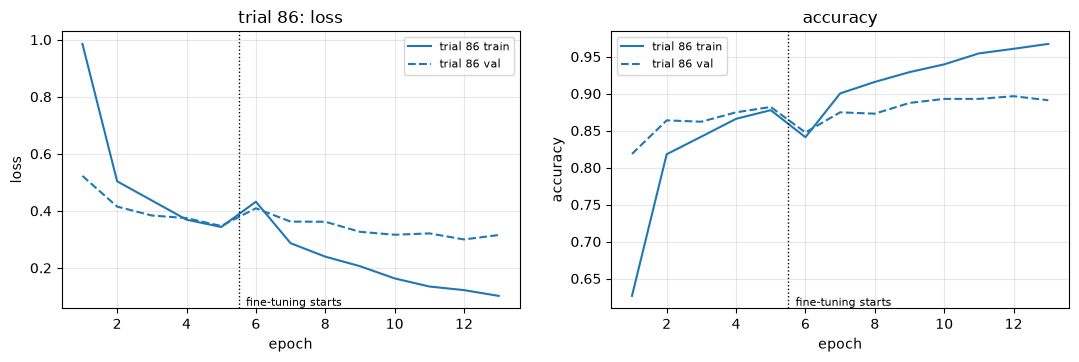

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   85       25      adam    5e-05      7  True  1,368,325   0.909    0.287    76s  ← your entry
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   81       25      adam    5e-05      9  True  1,368,325   0.906    0.293    79s
   68       25      adam    5e-05      6  True  1,368,325   0.904    0.294    56s
   66       25      adam    5e-05     10 False  1,368,325   0.902    0.308    87s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   76       25      adam    5e-05      8  True  1,368,325   0.898    0.304    71s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   53       27      adam    5e-05      8  True  1,376,965   0.897    0.313    74s
  

23196

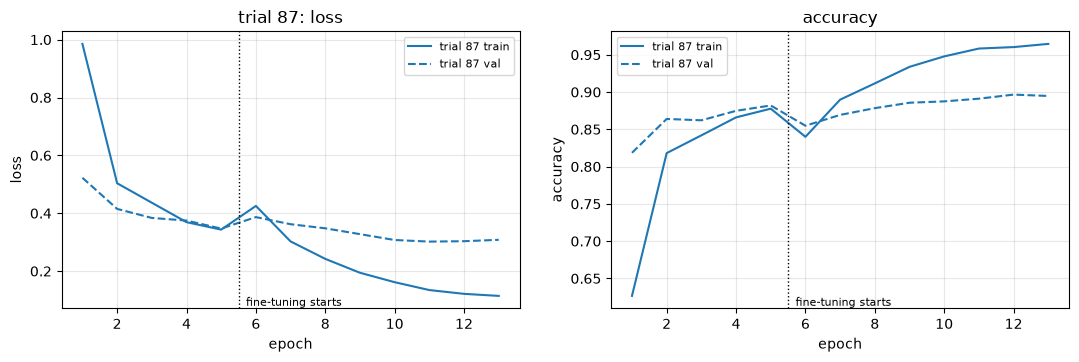

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   85       25      adam    5e-05      7  True  1,368,325   0.909    0.287    76s  ← your entry
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   81       25      adam    5e-05      9  True  1,368,325   0.906    0.293    79s
   68       25      adam    5e-05      6  True  1,368,325   0.904    0.294    56s
   66       25      adam    5e-05     10 False  1,368,325   0.902    0.308    87s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   76       25      adam    5e-05      8  True  1,368,325   0.898    0.304    71s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
   53       27      adam    5e-05      8  True  1,376,965   0.897    0.313    74s
  

23196

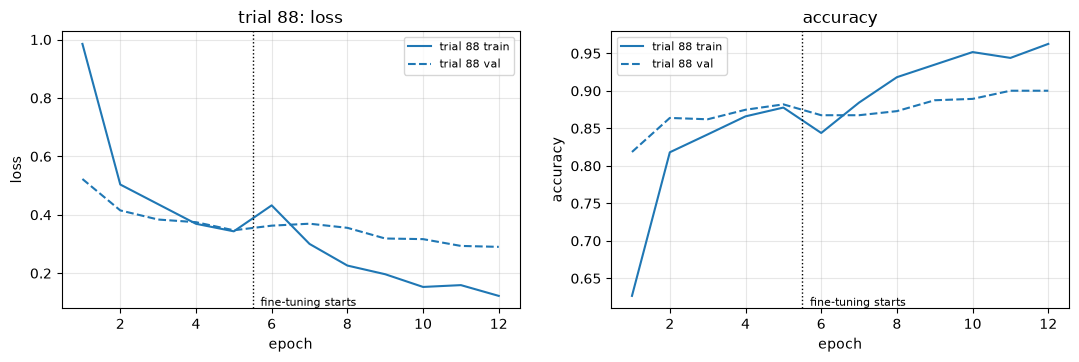

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   85       25      adam    5e-05      7  True  1,368,325   0.909    0.287    76s  ← your entry
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   81       25      adam    5e-05      9  True  1,368,325   0.906    0.293    79s
   68       25      adam    5e-05      6  True  1,368,325   0.904    0.294    56s
   66       25      adam    5e-05     10 False  1,368,325   0.902    0.308    87s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   88       25      adam    5e-05      7  True  1,368,325   0.900    0.290   140s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   76       25      adam    5e-05      8  True  1,368,325   0.898    0.304    71s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
  

23116

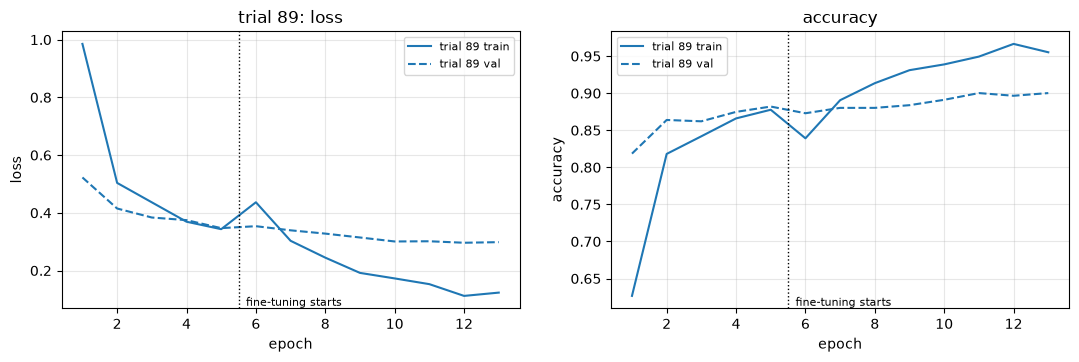

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   85       25      adam    5e-05      7  True  1,368,325   0.909    0.287    76s  ← your entry
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   81       25      adam    5e-05      9  True  1,368,325   0.906    0.293    79s
   68       25      adam    5e-05      6  True  1,368,325   0.904    0.294    56s
   66       25      adam    5e-05     10 False  1,368,325   0.902    0.308    87s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   88       25      adam    5e-05      7  True  1,368,325   0.900    0.290   140s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   76       25      adam    5e-05      8  True  1,368,325   0.898    0.304    71s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
  

23196

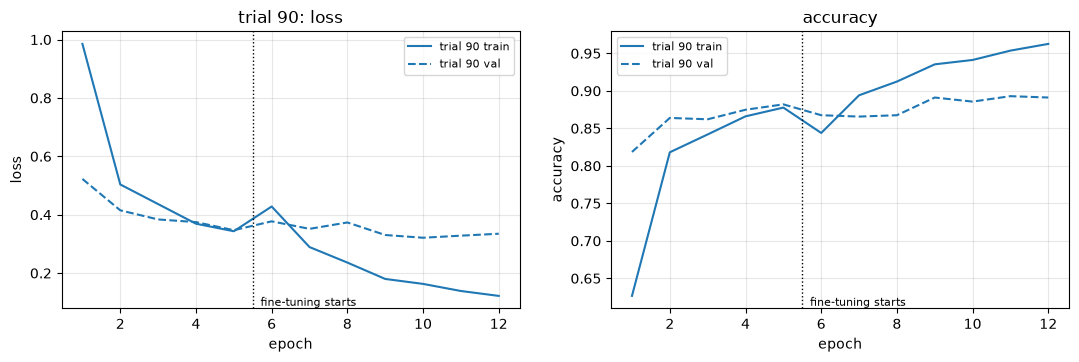

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   85       25      adam    5e-05      7  True  1,368,325   0.909    0.287    76s  ← your entry
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   81       25      adam    5e-05      9  True  1,368,325   0.906    0.293    79s
   68       25      adam    5e-05      6  True  1,368,325   0.904    0.294    56s
   66       25      adam    5e-05     10 False  1,368,325   0.902    0.308    87s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   88       25      adam    5e-05      7  True  1,368,325   0.900    0.290   140s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   76       25      adam    5e-05      8  True  1,368,325   0.898    0.304    71s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
  

23116

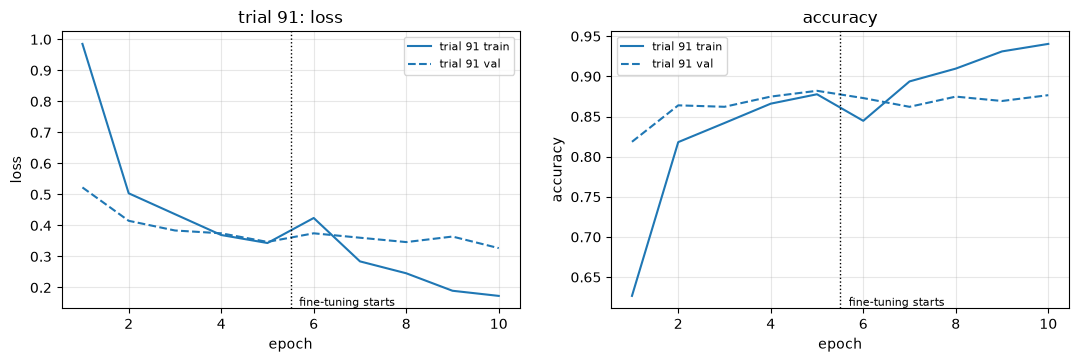

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   85       25      adam    5e-05      7  True  1,368,325   0.909    0.287    76s  ← your entry
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   81       25      adam    5e-05      9  True  1,368,325   0.906    0.293    79s
   68       25      adam    5e-05      6  True  1,368,325   0.904    0.294    56s
   66       25      adam    5e-05     10 False  1,368,325   0.902    0.308    87s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   88       25      adam    5e-05      7  True  1,368,325   0.900    0.290   140s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   76       25      adam    5e-05      8  True  1,368,325   0.898    0.304    71s
   33       25      adam    5e-05      9  True  1,368,325   0.898    0.284    86s
  

23549

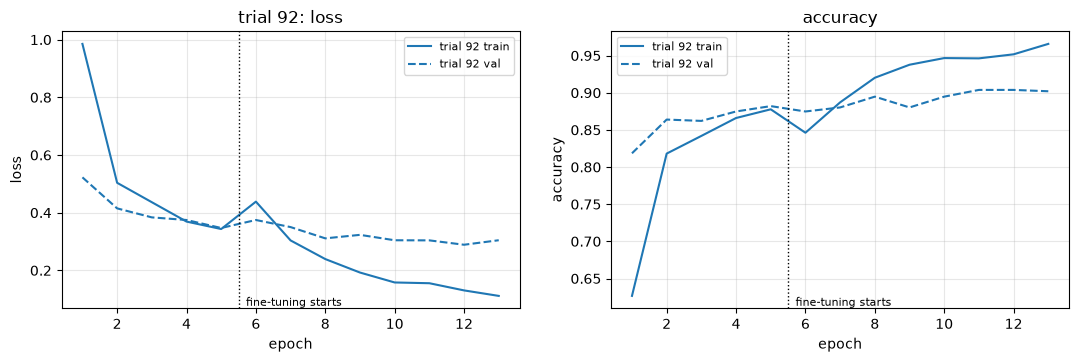

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   85       25      adam    5e-05      7  True  1,368,325   0.909    0.287    76s  ← your entry
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   81       25      adam    5e-05      9  True  1,368,325   0.906    0.293    79s
   68       25      adam    5e-05      6  True  1,368,325   0.904    0.294    56s
   92       25      adam    5e-05      8  True  1,368,325   0.904    0.289    90s
   66       25      adam    5e-05     10 False  1,368,325   0.902    0.308    87s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   88       25      adam    5e-05      7  True  1,368,325   0.900    0.290   140s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   76       25      adam    5e-05      8  True  1,368,325   0.898    0.304    71s
  

23196

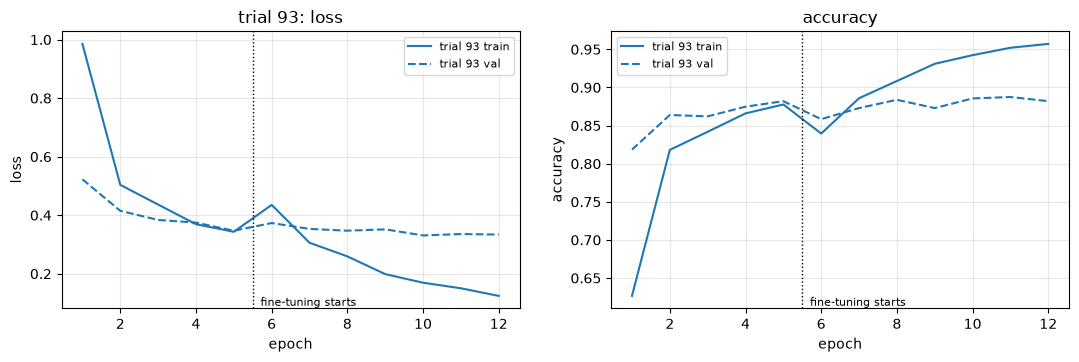

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   85       25      adam    5e-05      7  True  1,368,325   0.909    0.287    76s  ← your entry
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   81       25      adam    5e-05      9  True  1,368,325   0.906    0.293    79s
   68       25      adam    5e-05      6  True  1,368,325   0.904    0.294    56s
   92       25      adam    5e-05      8  True  1,368,325   0.904    0.289    90s
   66       25      adam    5e-05     10 False  1,368,325   0.902    0.308    87s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   88       25      adam    5e-05      7  True  1,368,325   0.900    0.290   140s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   76       25      adam    5e-05      8  True  1,368,325   0.898    0.304    71s
  

23116

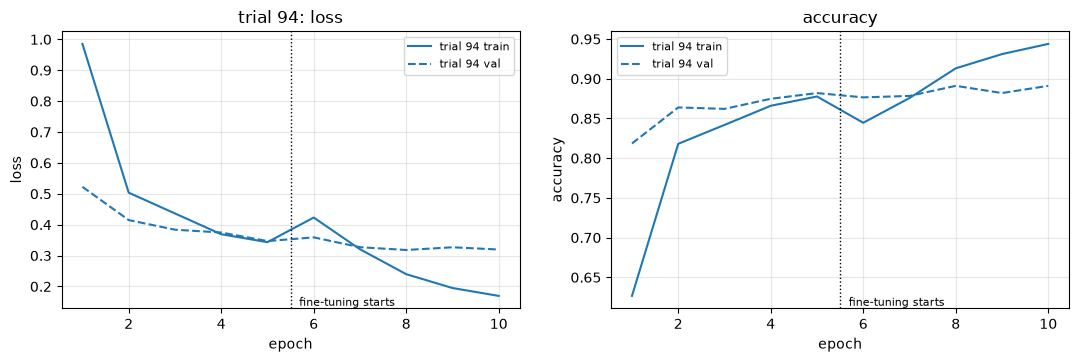

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   85       25      adam    5e-05      7  True  1,368,325   0.909    0.287    76s  ← your entry
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   81       25      adam    5e-05      9  True  1,368,325   0.906    0.293    79s
   68       25      adam    5e-05      6  True  1,368,325   0.904    0.294    56s
   92       25      adam    5e-05      8  True  1,368,325   0.904    0.289    90s
   66       25      adam    5e-05     10 False  1,368,325   0.902    0.308    87s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   88       25      adam    5e-05      7  True  1,368,325   0.900    0.290   140s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   76       25      adam    5e-05      8  True  1,368,325   0.898    0.304    71s
  

23549

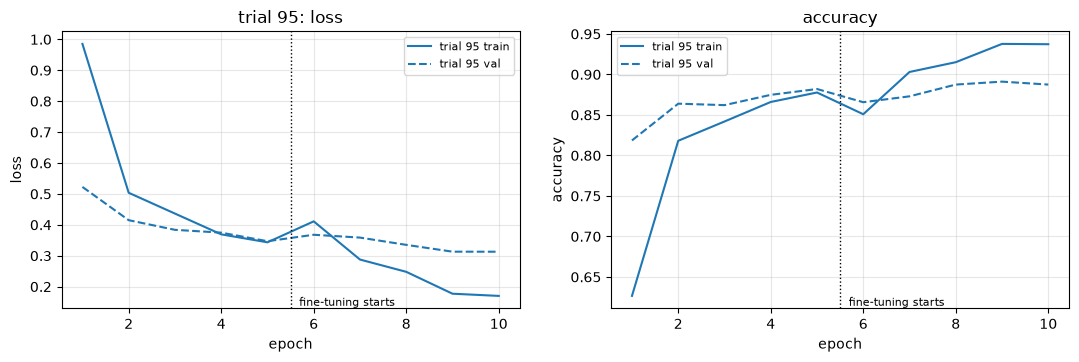

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   85       25      adam    5e-05      7  True  1,368,325   0.909    0.287    76s  ← your entry
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   81       25      adam    5e-05      9  True  1,368,325   0.906    0.293    79s
   68       25      adam    5e-05      6  True  1,368,325   0.904    0.294    56s
   92       25      adam    5e-05      8  True  1,368,325   0.904    0.289    90s
   66       25      adam    5e-05     10 False  1,368,325   0.902    0.308    87s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   88       25      adam    5e-05      7  True  1,368,325   0.900    0.290   140s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   76       25      adam    5e-05      8  True  1,368,325   0.898    0.304    71s
  

23549

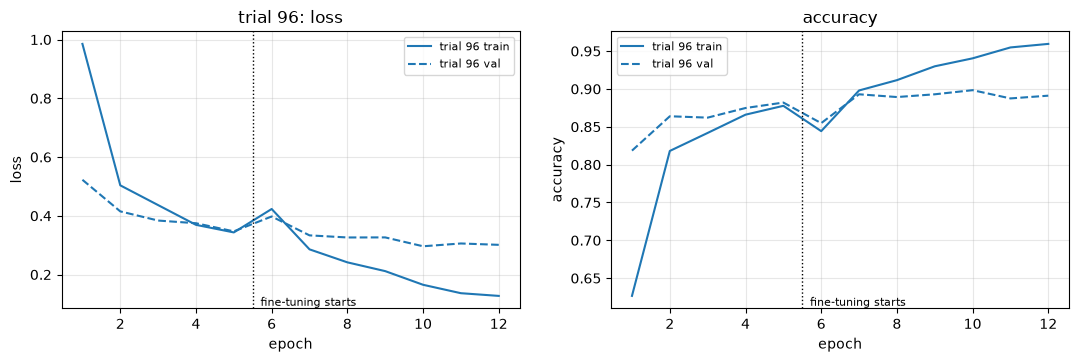

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   85       25      adam    5e-05      7  True  1,368,325   0.909    0.287    76s  ← your entry
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   81       25      adam    5e-05      9  True  1,368,325   0.906    0.293    79s
   68       25      adam    5e-05      6  True  1,368,325   0.904    0.294    56s
   92       25      adam    5e-05      8  True  1,368,325   0.904    0.289    90s
   66       25      adam    5e-05     10 False  1,368,325   0.902    0.308    87s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   88       25      adam    5e-05      7  True  1,368,325   0.900    0.290   140s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   76       25      adam    5e-05      8  True  1,368,325   0.898    0.304    71s
  

23054

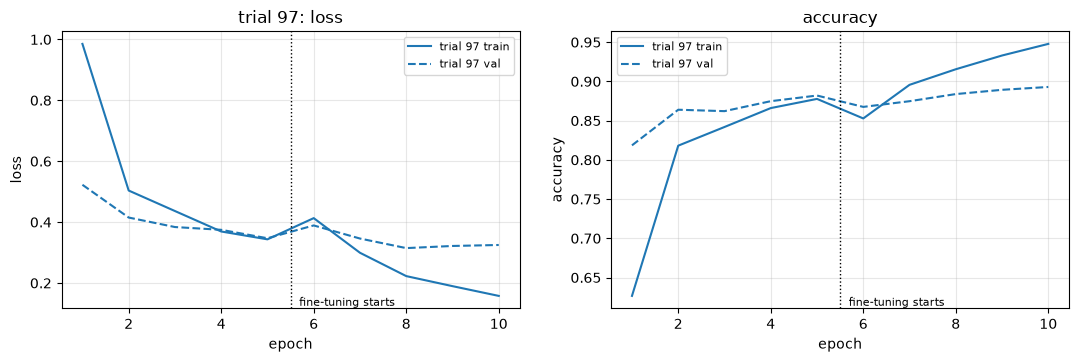

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   85       25      adam    5e-05      7  True  1,368,325   0.909    0.287    76s  ← your entry
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   81       25      adam    5e-05      9  True  1,368,325   0.906    0.293    79s
   68       25      adam    5e-05      6  True  1,368,325   0.904    0.294    56s
   92       25      adam    5e-05      8  True  1,368,325   0.904    0.289    90s
   66       25      adam    5e-05     10 False  1,368,325   0.902    0.308    87s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   88       25      adam    5e-05      7  True  1,368,325   0.900    0.290   140s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   76       25      adam    5e-05      8  True  1,368,325   0.898    0.304    71s
  

23126

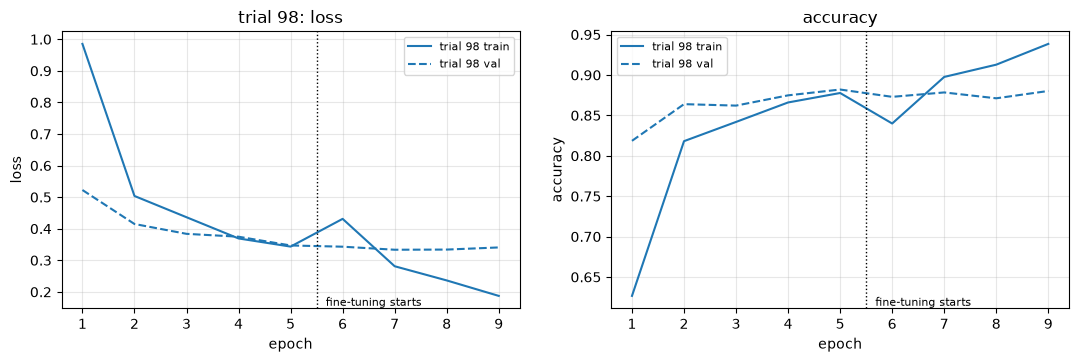

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   85       25      adam    5e-05      7  True  1,368,325   0.909    0.287    76s  ← your entry
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   81       25      adam    5e-05      9  True  1,368,325   0.906    0.293    79s
   68       25      adam    5e-05      6  True  1,368,325   0.904    0.294    56s
   92       25      adam    5e-05      8  True  1,368,325   0.904    0.289    90s
   66       25      adam    5e-05     10 False  1,368,325   0.902    0.308    87s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   88       25      adam    5e-05      7  True  1,368,325   0.900    0.290   140s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   76       25      adam    5e-05      8  True  1,368,325   0.898    0.304    71s
  

24151

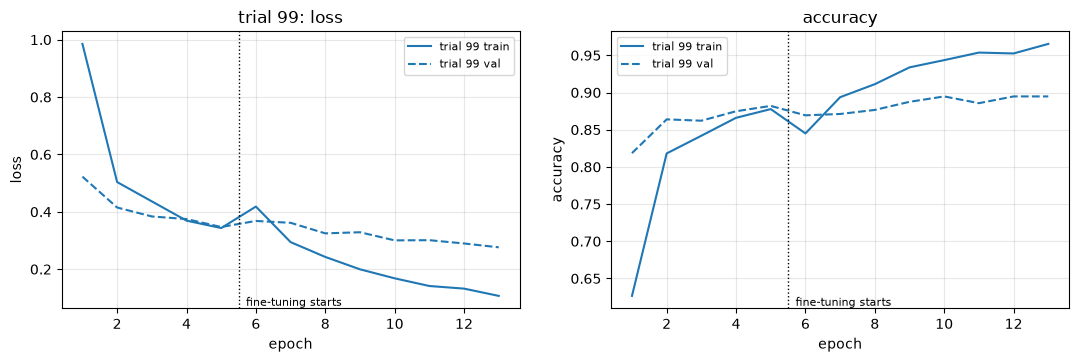

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   85       25      adam    5e-05      7  True  1,368,325   0.909    0.287    76s  ← your entry
   37       27      adam    5e-05      8  True  1,376,965   0.907    0.285    79s
   46       27      adam    5e-05      9  True  1,376,965   0.906    0.293    88s
   81       25      adam    5e-05      9  True  1,368,325   0.906    0.293    79s
   68       25      adam    5e-05      6  True  1,368,325   0.904    0.294    56s
   92       25      adam    5e-05      8  True  1,368,325   0.904    0.289    90s
   66       25      adam    5e-05     10 False  1,368,325   0.902    0.308    87s
   27       25      adam    4e-05     10  True  1,368,325   0.900    0.293    85s
   88       25      adam    5e-05      7  True  1,368,325   0.900    0.290   140s
   54       25      adam    1e-04      4  True  1,368,325   0.898    0.318    39s
   76       25      adam    5e-05      8  True  1,368,325   0.898    0.304    71s
  

23240

In [59]:
# trial 2, 3, ...: copy this line, change one knob at a time, and run
# try_recipe(unfreeze=..., optimizer=..., lr=..., epochs=..., early_stopping=...)

try_recipe(unfreeze=30, optimizer="adam", lr=1e-05, epochs=3, early_stopping=True)  # Trial 1
try_recipe(unfreeze=60, optimizer="adam", lr=5e-05, epochs=7, early_stopping=True)  # Trial 2
try_recipe(unfreeze=60, optimizer="rmsprop", lr=5e-05, epochs=8, early_stopping=True)  # Trial 3
try_recipe(unfreeze=30, optimizer="rmsprop", lr=5e-05, epochs=5, early_stopping=True)  # Trial 4
try_recipe(unfreeze=40, optimizer="adam", lr=1e-05, epochs=3, early_stopping=True)  # Trial 5
try_recipe(unfreeze=50, optimizer="adam", lr=1e-05, epochs=3, early_stopping=True)  # Trial 6
try_recipe(unfreeze=60, optimizer="adam", lr=1e-05, epochs=10, early_stopping=True)  # Trial 7
try_recipe(unfreeze=30, optimizer="adam", lr=2e-05, epochs=10, early_stopping=True)  # Trial 8
try_recipe(unfreeze=30, optimizer="adam", lr=3e-05, epochs=8, early_stopping=True)  # Trial 9
try_recipe(unfreeze=30, optimizer="adam", lr=4e-05, epochs=6, early_stopping=True)  # Trial 10
try_recipe(unfreeze=30, optimizer="adam", lr=5e-05, epochs=7, early_stopping=True)  # Trial 11
try_recipe(unfreeze=30, optimizer="adam", lr=6e-05, epochs=8, early_stopping=True)  # Trial 12
try_recipe(unfreeze=30, optimizer="adam", lr=7e-05, epochs=5, early_stopping=True)  # Trial 13
try_recipe(unfreeze=60, optimizer="adam", lr=4e-05, epochs=9, early_stopping=True)  # Trial 14
try_recipe(unfreeze=20, optimizer="adam", lr=4e-05, epochs=5, early_stopping=True)  # Trial 15
try_recipe(unfreeze=40, optimizer="adam", lr=4e-05, epochs=5, early_stopping=True)  # Trial 16
try_recipe(unfreeze=50, optimizer="adam", lr=4e-05, epochs=6, early_stopping=True)  # Trial 17
try_recipe(unfreeze=30, optimizer="rmsprop", lr=4e-05, epochs=6, early_stopping=True)  # Trial 18
try_recipe(unfreeze=30, optimizer="rmsprop", lr=5e-05, epochs=7, early_stopping=True)  # Trial 19
try_recipe(unfreeze=30, optimizer="rmsprop", lr=3e-05, epochs=5, early_stopping=True)  # Trial 20
try_recipe(unfreeze=30, optimizer="rmsprop", lr=2e-05, epochs=10, early_stopping=True)  # Trial 21
try_recipe(unfreeze=30, optimizer="rmsprop", lr=1e-05, epochs=3, early_stopping=True)  # Trial 22
try_recipe(unfreeze=60, optimizer="adam", lr=6e-05, epochs=3, early_stopping=True)  # Trial 23
try_recipe(unfreeze=30, optimizer="adam", lr=5e-05, epochs=10, early_stopping=True)  # Trial 24
try_recipe(unfreeze=30, optimizer="adam", lr=6e-05, epochs=7, early_stopping=True)  # Trial 25
try_recipe(unfreeze=30, optimizer="adam", lr=3e-05, epochs=10, early_stopping=True)  # Trial 26
try_recipe(unfreeze=25, optimizer="adam", lr=4e-05, epochs=10, early_stopping=True)  # Trial 27
try_recipe(unfreeze=35, optimizer="adam", lr=4e-05, epochs=4, early_stopping=True)  # Trial 28
try_recipe(unfreeze=25, optimizer="adam", lr=6e-05, epochs=10, early_stopping=True)  # Trial 29
try_recipe(unfreeze=35, optimizer="adam", lr=6e-05, epochs=6, early_stopping=True)  # Trial 30
try_recipe(unfreeze=60, optimizer="adam", lr=3e-05, epochs=5, early_stopping=True)  # Trial 31
try_recipe(unfreeze=60, optimizer="adam", lr=5e-05, epochs=3, early_stopping=True)  # Trial 32
try_recipe(unfreeze=25, optimizer="adam", lr=5e-05, epochs=9, early_stopping=True)  # Trial 33
try_recipe(unfreeze=25, optimizer="adam", lr=3e-05, epochs=7, early_stopping=True)  # Trial 34
try_recipe(unfreeze=25, optimizer="adam", lr=5e-05, epochs=10, early_stopping=True)  # Trial 35
try_recipe(unfreeze=25, optimizer="adam", lr=6e-05, epochs=10, early_stopping=True)  # Trial 36
try_recipe(unfreeze=27, optimizer="adam", lr=5e-05, epochs=8, early_stopping=True)  # Trial 37
try_recipe(unfreeze=27, optimizer="adam", lr=6e-05, epochs=3, early_stopping=True)  # Trial 38
try_recipe(unfreeze=27, optimizer="adam", lr=3e-05, epochs=10, early_stopping=True)  # Trial 39
try_recipe(unfreeze=30, optimizer="adam", lr=4e-05, epochs=9, early_stopping=True)  # Trial 40
try_recipe(unfreeze=30, optimizer="adam", lr=5e-05, epochs=7, early_stopping=True)  # Trial 41
try_recipe(unfreeze=23, optimizer="adam", lr=6e-05, epochs=5, early_stopping=True)  # Trial 42
try_recipe(unfreeze=30, optimizer="adam", lr=1e-05, epochs=3, early_stopping=True)  # Trial 43
try_recipe(unfreeze=25, optimizer="adam", lr=5e-05, epochs=7, early_stopping=True)  # Trial 44
try_recipe(unfreeze=25, optimizer="adam", lr=5e-05, epochs=7, early_stopping=True)  # Trial 45
try_recipe(unfreeze=27, optimizer="adam", lr=5e-05, epochs=10, early_stopping=True)  # Trial 46
try_recipe(unfreeze=23, optimizer="adam", lr=5e-05, epochs=5, early_stopping=True)  # Trial 47
try_recipe(unfreeze=28, optimizer="adam", lr=5e-05, epochs=9, early_stopping=True)  # Trial 48
try_recipe(unfreeze=32, optimizer="adam", lr=5e-05, epochs=6, early_stopping=True)  # Trial 49
try_recipe(unfreeze=23, optimizer="adam", lr=5e-05, epochs=6, early_stopping=True)  # Trial 50
try_recipe(unfreeze=27, optimizer="adam", lr=5e-05, epochs=8, early_stopping=True)  # Trial 51
try_recipe(unfreeze=23, optimizer="adam", lr=5e-05, epochs=5, early_stopping=True)  # Trial 52
try_recipe(unfreeze=27, optimizer="adam", lr=5e-05, epochs=8, early_stopping=True)  # Trial 53
try_recipe(unfreeze=25, optimizer="adam", lr=1e-04, epochs=4, early_stopping=True)  # Trial 54
try_recipe(unfreeze=25, optimizer="adam", lr=3e-04, epochs=3, early_stopping=True)  # Trial 55
try_recipe(unfreeze=25, optimizer="adam", lr=1e-03, epochs=3, early_stopping=True)  # Trial 56
try_recipe(unfreeze=25, optimizer="adam", lr=3e-03, epochs=3, early_stopping=True)  # Trial 57
try_recipe(unfreeze=25, optimizer="adam", lr=1e-02, epochs=7, early_stopping=True)  # Trial 58
try_recipe(unfreeze=25, optimizer="rmsprop", lr=1e-04, epochs=3, early_stopping=True)  # Trial 59
try_recipe(unfreeze=25, optimizer="rmsprop", lr=3e-04, epochs=10, early_stopping=True)  # Trial 60
try_recipe(unfreeze=25, optimizer="rmsprop", lr=1e-03, epochs=5, early_stopping=True)  # Trial 61
try_recipe(unfreeze=25, optimizer="rmsprop", lr=3e-03, epochs=5, early_stopping=True)  # Trial 62
try_recipe(unfreeze=25, optimizer="rmsprop", lr=1e-02, epochs=6, early_stopping=True)  # Trial 63
try_recipe(unfreeze=0, optimizer="adam", lr=5e-05, epochs=10, early_stopping=True)  # Trial 64
try_recipe(unfreeze=25, optimizer="adam", lr=5e-05, epochs=10, early_stopping=False)  # Trial 65
try_recipe(unfreeze=25, optimizer="adam", lr=5e-05, epochs=10, early_stopping=False)  # Trial 66
try_recipe(unfreeze=26, optimizer="adam", lr=5e-05, epochs=9, early_stopping=True)  # Trial 67
try_recipe(unfreeze=25, optimizer="adam", lr=5e-05, epochs=7, early_stopping=True)  # Trial 68
try_recipe(unfreeze=25, optimizer="adam", lr=5e-05, epochs=6, early_stopping=True)  # Trial 69
try_recipe(unfreeze=25, optimizer="adam", lr=5e-05, epochs=7, early_stopping=True)  # Trial 70
try_recipe(unfreeze=25, optimizer="adam", lr=5e-05, epochs=9, early_stopping=True)  # Trial 71
try_recipe(unfreeze=25, optimizer="adam", lr=5e-05, epochs=9, early_stopping=True)  # Trial 72
try_recipe(unfreeze=25, optimizer="adam", lr=5e-05, epochs=10, early_stopping=True)  # Trial 73
try_recipe(unfreeze=25, optimizer="adam", lr=5e-05, epochs=6, early_stopping=True)  # Trial 74
try_recipe(unfreeze=25, optimizer="adam", lr=5e-05, epochs=7, early_stopping=True)  # Trial 75
try_recipe(unfreeze=25, optimizer="adam", lr=5e-05, epochs=8, early_stopping=True)  # Trial 76
try_recipe(unfreeze=25, optimizer="adam", lr=5e-05, epochs=8, early_stopping=True)  # Trial 77
try_recipe(unfreeze=25, optimizer="adam", lr=5e-05, epochs=9, early_stopping=True)  # Trial 78
try_recipe(unfreeze=25, optimizer="adam", lr=5e-05, epochs=10, early_stopping=True)  # Trial 79
try_recipe(unfreeze=25, optimizer="adam", lr=5e-05, epochs=10, early_stopping=True)  # Trial 80
try_recipe(unfreeze=25, optimizer="adam", lr=5e-05, epochs=10, early_stopping=True)  # Trial 81
try_recipe(unfreeze=25, optimizer="adam", lr=5e-05, epochs=8, early_stopping=True)  # Trial 82
try_recipe(unfreeze=25, optimizer="adam", lr=5e-05, epochs=3, early_stopping=True)  # Trial 83
try_recipe(unfreeze=25, optimizer="adam", lr=5e-05, epochs=5, early_stopping=True)  # Trial 84
try_recipe(unfreeze=25, optimizer="adam", lr=5e-05, epochs=7, early_stopping=True)  # Trial 85
try_recipe(unfreeze=25, optimizer="adam", lr=5e-05, epochs=8, early_stopping=True)  # Trial 86
try_recipe(unfreeze=25, optimizer="adam", lr=5e-05, epochs=9, early_stopping=True)  # Trial 87
try_recipe(unfreeze=25, optimizer="adam", lr=5e-05, epochs=7, early_stopping=True)  # Trial 88
try_recipe(unfreeze=25, optimizer="adam", lr=5e-05, epochs=8, early_stopping=True)  # Trial 89
try_recipe(unfreeze=25, optimizer="adam", lr=5e-05, epochs=10, early_stopping=True)  # Trial 90
try_recipe(unfreeze=25, optimizer="adam", lr=5e-05, epochs=5, early_stopping=True)  # Trial 91
try_recipe(unfreeze=25, optimizer="adam", lr=5e-05, epochs=8, early_stopping=True)  # Trial 92
try_recipe(unfreeze=25, optimizer="adam", lr=5e-05, epochs=9, early_stopping=True)  # Trial 93
try_recipe(unfreeze=25, optimizer="adam", lr=5e-05, epochs=9, early_stopping=True)  # Trial 94
try_recipe(unfreeze=25, optimizer="adam", lr=5e-05, epochs=5, early_stopping=True)  # Trial 95
try_recipe(unfreeze=25, optimizer="adam", lr=5e-05, epochs=8, early_stopping=True)  # Trial 96
try_recipe(unfreeze=25, optimizer="adam", lr=5e-05, epochs=10, early_stopping=True)  # Trial 97
try_recipe(unfreeze=25, optimizer="adam", lr=5e-05, epochs=9, early_stopping=True)  # Trial 98
try_recipe(unfreeze=27, optimizer="adam", lr=5e-05, epochs=8, early_stopping=True)  # Trial 99


✍️ **Question 5.** (a) Paste your trial table. Which knob changed the validation accuracy the most? (b) For your **worst** trial, read its loss curve: what happened right after fine-tuning started, and why (use the words *learning rate*, *overfitting* or *underfitting*)? (c) Why does the challenge pick your entry by validation accuracy and not by test accuracy?

*Your answer:*
(a) We completed 99 trials locally, so the full table is below. The largest observed difference between similar recipes came from the learning rate. With 25 layers unfrozen, Adam, and early stopping enabled, Trial 58 reached 17.4% at a learning rate of `1e-2`, while Trial 85 reached 90.9% at `5e-5`. Trial 85 was selected at 90.9% validation accuracy. The local runtime restarted after Trial 49, and the remaining trials used the saved warmup weights. The selected model reached 91.5% in the local test evaluation.

(b) Trial 58 had the lowest validation accuracy (17.4%). At the first fine-tuning epoch, validation loss moved from 0.347 to 30.198 and training loss moved from 0.343 to 0.912. The large jump suggests the learning rate was too high and disrupted useful pretrained features.

(c) We use validation accuracy to choose the recipe. Keeping the test set separate gives us an independent estimate of how well the selected model classifies unseen photos.

| Trial | Unfreeze | Optimizer | LR | Epochs run | Early stopping | Trainable | Val. accuracy | Val. loss | Time |
| ---: | ---: | :--- | ---: | ---: | :---: | ---: | ---: | ---: | ---: |
| **85 (selected)** | 25 | adam | `5e-05` | 7 | True | 1,368,325 | 0.909 | 0.287 | 76s |
| 37 | 27 | adam | `5e-05` | 8 | True | 1,376,965 | 0.907 | 0.285 | 79s |
| 46 | 27 | adam | `5e-05` | 9 | True | 1,376,965 | 0.906 | 0.293 | 88s |
| 81 | 25 | adam | `5e-05` | 9 | True | 1,368,325 | 0.906 | 0.293 | 79s |
| 68 | 25 | adam | `5e-05` | 6 | True | 1,368,325 | 0.904 | 0.294 | 56s |
| 92 | 25 | adam | `5e-05` | 8 | True | 1,368,325 | 0.904 | 0.289 | 90s |
| 66 | 25 | adam | `5e-05` | 10 | False | 1,368,325 | 0.902 | 0.308 | 87s |
| 27 | 25 | adam | `4e-05` | 10 | True | 1,368,325 | 0.900 | 0.293 | 85s |
| 88 | 25 | adam | `5e-05` | 7 | True | 1,368,325 | 0.900 | 0.290 | 140s |
| 54 | 25 | adam | `0.0001` | 4 | True | 1,368,325 | 0.898 | 0.318 | 39s |
| 76 | 25 | adam | `5e-05` | 8 | True | 1,368,325 | 0.898 | 0.304 | 71s |
| 96 | 25 | adam | `5e-05` | 7 | True | 1,368,325 | 0.898 | 0.296 | 65s |
| 33 | 25 | adam | `5e-05` | 9 | True | 1,368,325 | 0.898 | 0.284 | 86s |
| 53 | 27 | adam | `5e-05` | 8 | True | 1,376,965 | 0.897 | 0.313 | 74s |
| 69 | 25 | adam | `5e-05` | 6 | True | 1,368,325 | 0.897 | 0.302 | 57s |
| 73 | 25 | adam | `5e-05` | 9 | True | 1,368,325 | 0.897 | 0.306 | 79s |
| 86 | 25 | adam | `5e-05` | 8 | True | 1,368,325 | 0.897 | 0.300 | 127s |
| 89 | 25 | adam | `5e-05` | 8 | True | 1,368,325 | 0.897 | 0.296 | 105s |
| 25 | 30 | adam | `6e-05` | 7 | True | 1,532,805 | 0.897 | 0.304 | 95s |
| 47 | 23 | adam | `5e-05` | 5 | True | 1,366,405 | 0.897 | 0.303 | 50s |
| 9 | 30 | adam | `3e-05` | 8 | True | 1,532,805 | 0.895 | 0.314 | 82s |
| 17 | 50 | adam | `4e-05` | 6 | True | 1,861,509 | 0.895 | 0.310 | 71s |
| 20 | 30 | rmsprop | `3e-05` | 5 | True | 1,532,805 | 0.895 | 0.306 | 46s |
| 35 | 25 | adam | `5e-05` | 6 | True | 1,368,325 | 0.895 | 0.304 | 67s |
| 50 | 23 | adam | `5e-05` | 6 | True | 1,366,405 | 0.895 | 0.311 | 163s |
| 72 | 25 | adam | `5e-05` | 7 | True | 1,368,325 | 0.895 | 0.307 | 63s |
| 74 | 25 | adam | `5e-05` | 6 | True | 1,368,325 | 0.895 | 0.302 | 54s |
| 80 | 25 | adam | `5e-05` | 7 | True | 1,368,325 | 0.895 | 0.302 | 66s |
| 82 | 25 | adam | `5e-05` | 8 | True | 1,368,325 | 0.895 | 0.295 | 71s |
| 99 | 27 | adam | `5e-05` | 8 | True | 1,376,965 | 0.895 | 0.276 | 72s |
| 51 | 27 | adam | `5e-05` | 8 | True | 1,376,965 | 0.893 | 0.293 | 73s |
| 71 | 25 | adam | `5e-05` | 9 | True | 1,368,325 | 0.893 | 0.298 | 79s |
| 78 | 25 | adam | `5e-05` | 9 | True | 1,368,325 | 0.893 | 0.302 | 79s |
| 79 | 25 | adam | `5e-05` | 7 | True | 1,368,325 | 0.893 | 0.307 | 65s |
| 29 | 25 | adam | `6e-05` | 6 | True | 1,368,325 | 0.893 | 0.316 | 59s |
| 36 | 25 | adam | `6e-05` | 7 | True | 1,368,325 | 0.893 | 0.313 | 69s |
| 44 | 25 | adam | `5e-05` | 5 | True | 1,368,325 | 0.893 | 0.329 | 48s |
| 48 | 28 | adam | `5e-05` | 8 | True | 1,378,885 | 0.893 | 0.317 | 94s |
| 67 | 26 | adam | `5e-05` | 7 | True | 1,376,965 | 0.891 | 0.293 | 65s |
| 77 | 25 | adam | `5e-05` | 8 | True | 1,368,325 | 0.891 | 0.306 | 70s |
| 87 | 25 | adam | `5e-05` | 8 | True | 1,368,325 | 0.891 | 0.302 | 122s |
| 94 | 25 | adam | `5e-05` | 5 | True | 1,368,325 | 0.891 | 0.318 | 51s |
| 3 | 60 | rmsprop | `5e-05` | 6 | True | 1,962,117 | 0.891 | 0.349 | 62s |
| 18 | 30 | rmsprop | `4e-05` | 6 | True | 1,532,805 | 0.891 | 0.297 | 60s |
| 39 | 27 | adam | `3e-05` | 10 | True | 1,376,965 | 0.891 | 0.294 | 102s |
| 12 | 30 | adam | `6e-05` | 7 | True | 1,532,805 | 0.889 | 0.307 | 70s |
| 24 | 30 | adam | `5e-05` | 8 | True | 1,532,805 | 0.889 | 0.304 | 99s |
| 32 | 60 | adam | `5e-05` | 3 | True | 1,962,117 | 0.889 | 0.327 | 47s |
| 34 | 25 | adam | `3e-05` | 7 | True | 1,368,325 | 0.889 | 0.307 | 71s |
| 38 | 27 | adam | `6e-05` | 3 | True | 1,376,965 | 0.889 | 0.329 | 33s |
| 49 | 32 | adam | `5e-05` | 6 | True | 1,624,965 | 0.889 | 0.344 | 98s |
| 70 | 25 | adam | `5e-05` | 7 | True | 1,368,325 | 0.889 | 0.315 | 65s |
| 75 | 25 | adam | `5e-05` | 7 | True | 1,368,325 | 0.889 | 0.319 | 63s |
| 64 | 0 | adam | `5e-05` | 3 | True | 6,405 | 0.887 | 0.343 | 23s |
| 84 | 25 | adam | `5e-05` | 5 | True | 1,368,325 | 0.887 | 0.329 | 60s |
| 95 | 25 | adam | `5e-05` | 5 | True | 1,368,325 | 0.887 | 0.313 | 49s |
| 8 | 30 | adam | `2e-05` | 10 | True | 1,532,805 | 0.887 | 0.307 | 92s |
| 11 | 30 | adam | `5e-05` | 7 | True | 1,532,805 | 0.887 | 0.314 | 71s |
| 22 | 30 | rmsprop | `1e-05` | 3 | True | 1,532,805 | 0.887 | 0.343 | 31s |
| 26 | 30 | adam | `3e-05` | 10 | True | 1,532,805 | 0.887 | 0.312 | 95s |
| 45 | 25 | adam | `5e-05` | 7 | True | 1,368,325 | 0.887 | 0.315 | 69s |
| 90 | 25 | adam | `5e-05` | 7 | True | 1,368,325 | 0.886 | 0.321 | 86s |
| 93 | 25 | adam | `5e-05` | 7 | True | 1,368,325 | 0.886 | 0.331 | 92s |
| 10 | 30 | adam | `4e-05` | 6 | True | 1,532,805 | 0.886 | 0.319 | 62s |
| 42 | 23 | adam | `6e-05` | 5 | True | 1,366,405 | 0.886 | 0.320 | 46s |
| 15 | 20 | adam | `4e-05` | 5 | True | 1,212,485 | 0.884 | 0.329 | 45s |
| 65 | 25 | adam | `5e-05` | 10 | False | 1,368,325 | 0.884 | 0.330 | 87s |
| 83 | 25 | adam | `5e-05` | 3 | True | 1,368,325 | 0.884 | 0.339 | 35s |
| 97 | 25 | adam | `5e-05` | 5 | True | 1,368,325 | 0.884 | 0.315 | 47s |
| 7 | 60 | adam | `1e-05` | 3 | True | 1,962,117 | 0.882 | 0.339 | 45s |
| 13 | 30 | adam | `7e-05` | 5 | True | 1,532,805 | 0.882 | 0.320 | 56s |
| 19 | 30 | rmsprop | `5e-05` | 6 | True | 1,532,805 | 0.882 | 0.329 | 53s |
| 21 | 30 | rmsprop | `2e-05` | 9 | True | 1,532,805 | 0.882 | 0.323 | 75s |
| 40 | 30 | adam | `4e-05` | 6 | True | 1,532,805 | 0.882 | 0.315 | 59s |
| 41 | 30 | adam | `5e-05` | 5 | True | 1,532,805 | 0.882 | 0.340 | 51s |
| 1 | 30 | adam | `1e-05` | 3 | True | 1,532,805 | 0.880 | 0.347 | 37s |
| 6 | 50 | adam | `1e-05` | 3 | True | 1,861,509 | 0.880 | 0.342 | 41s |
| 43 | 30 | adam | `1e-05` | 3 | True | 1,532,805 | 0.880 | 0.349 | 34s |
| 5 | 40 | adam | `1e-05` | 3 | True | 1,687,941 | 0.878 | 0.350 | 38s |
| 14 | 60 | adam | `4e-05` | 3 | True | 1,962,117 | 0.878 | 0.350 | 66s |
| 23 | 60 | adam | `6e-05` | 3 | True | 1,962,117 | 0.878 | 0.399 | 66s |
| 52 | 23 | adam | `5e-05` | 5 | True | 1,366,405 | 0.878 | 0.325 | 45s |
| 98 | 25 | adam | `5e-05` | 4 | True | 1,368,325 | 0.878 | 0.333 | 45s |
| 91 | 25 | adam | `5e-05` | 5 | True | 1,368,325 | 0.877 | 0.327 | 85s |
| 2 | 60 | adam | `5e-05` | 7 | True | 1,962,117 | 0.877 | 0.336 | 87s |
| 28 | 35 | adam | `4e-05` | 3 | True | 1,631,301 | 0.877 | 0.346 | 36s |
| 16 | 40 | adam | `4e-05` | 5 | True | 1,687,941 | 0.873 | 0.341 | 60s |
| 31 | 60 | adam | `3e-05` | 3 | True | 1,962,117 | 0.873 | 0.354 | 52s |
| 59 | 25 | rmsprop | `0.0001` | 3 | True | 1,368,325 | 0.871 | 0.354 | 30s |
| 4 | 30 | rmsprop | `5e-05` | 3 | True | 1,532,805 | 0.871 | 0.354 | 30s |
| 30 | 35 | adam | `6e-05` | 6 | True | 1,631,301 | 0.868 | 0.374 | 80s |
| 55 | 25 | adam | `0.0003` | 3 | True | 1,368,325 | 0.858 | 0.584 | 33s |
| 56 | 25 | adam | `0.001` | 3 | True | 1,368,325 | 0.851 | 1.347 | 31s |
| 60 | 25 | rmsprop | `0.0003` | 3 | True | 1,368,325 | 0.838 | 0.548 | 30s |
| 61 | 25 | rmsprop | `0.001` | 3 | True | 1,368,325 | 0.764 | 2.813 | 28s |
| 57 | 25 | adam | `0.003` | 3 | True | 1,368,325 | 0.724 | 1.820 | 33s |
| 63 | 25 | rmsprop | `0.01` | 6 | True | 1,368,325 | 0.506 | 11.690 | 54s |
| 62 | 25 | rmsprop | `0.003` | 3 | True | 1,368,325 | 0.241 | 14.240 | 29s |
| 58 | 25 | adam | `0.01` | 3 | True | 1,368,325 | 0.174 | 30.198 | 31s |

---
## 4. Results

### 4a. The official test score: run this cell ONCE

In [61]:
TEST_RUNS = globals().get("TEST_RUNS", 0) + 1      # counts how many times this cell has been run
entry_model = ENTRY["model"]
test_loss, test_acc = entry_model.evaluate(test_ds, verbose=0)    # TODO: evaluate entry_model on test_ds (verbose=0)
baseline = np.bincount(labels).max() / len(labels)
print(f"OFFICIAL TEST ACCURACY {test_acc:.3f} · entry = trial {ENTRY['trial']} · validation accuracy {ENTRY['val_acc']:.3f}"
      f" · always-the-largest-class baseline {baseline:.3f} · test runs: {TEST_RUNS}")
print("Check:", 0 <= test_acc <= 1 and TEST_RUNS == 1)

OFFICIAL TEST ACCURACY 0.915 · entry = trial 85 · validation accuracy 0.909 · always-the-largest-class baseline 0.245 · test runs: 1
Check: True


### 4b. Where does it go wrong?

The test photos your entry gets wrong with the most confidence.

Could not load symbol cuStreamGetGreenCtx. Error: /usr/lib/wsl/lib/libcuda.so.1: undefined symbol: cuStreamGetGreenCtx


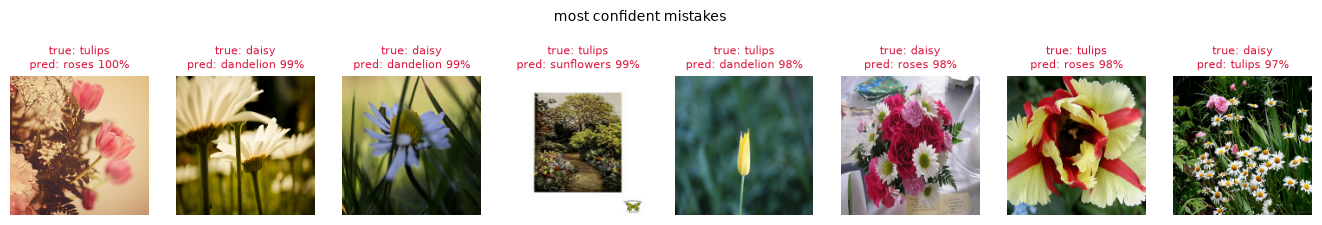

In [62]:
probs = entry_model.predict(test_ds, verbose=0)
y_true = labels[te_idx]
y_pred = probs.argmax(1)
wrong = np.where(y_pred != y_true)[0]
wrong = wrong[np.argsort(-probs[wrong].max(1))][:8]
if len(wrong):
    fig, axes = plt.subplots(1, len(wrong), figsize=(2.1 * len(wrong), 2.8), squeeze=False)
    for ax, i in zip(axes[0], wrong):
        img = load_image(paths[te_idx[i]], 0)[0].numpy()
        ax.imshow(img); ax.axis("off")
        ax.set_title(f"true: {class_names[y_true[i]]}\npred: {class_names[y_pred[i]]} {probs[i].max():.0%}", fontsize=8, color="crimson")
    plt.suptitle("most confident mistakes", fontsize=10); plt.show()

### 4c. The confusion matrix

Row = the true class, column = the predicted class. The diagonal holds the correct answers; every number off the diagonal is a mistake of one particular kind. Build it yourself, then read it.

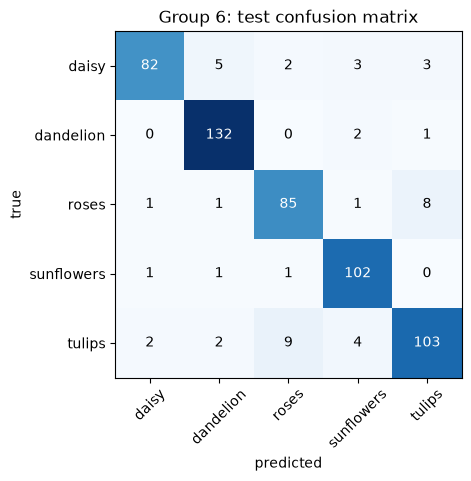

daisy       precision 0.953 · recall 0.863
dandelion   precision 0.936 · recall 0.978
roses       precision 0.876 · recall 0.885
sunflowers  precision 0.911 · recall 0.971
tulips      precision 0.896 · recall 0.858
most common mistake: tulips predicted as roses (9 photos)


Check: True


In [63]:
def confusion_matrix(y_true, y_pred, k):
    cm = np.zeros((k, k), dtype=int)
    for t, p in zip(y_true, y_pred):
        cm[t, p] += 1                                   # TODO: add 1 to row t, column p
    return cm

cm = confusion_matrix(y_true, y_pred, NUM_CLASSES)
precision = np.divide(np.diag(cm), cm.sum(axis=0), out=np.zeros(NUM_CLASSES), where=cm.sum(axis=0) != 0)   # TODO: diagonal / column sums  (of everything predicted as class c, the fraction that really is c)
recall    = np.diag(cm) / cm.sum(axis=1)   # TODO: diagonal / row sums     (of everything that really is class c, the fraction we found)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.imshow(cm, cmap="Blues")
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks(range(NUM_CLASSES), class_names, rotation=45); ax.set_yticks(range(NUM_CLASSES), class_names)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"Group {GROUP}: test confusion matrix"); plt.show()
for c, name in enumerate(class_names):
    print(f"{name:11s} precision {precision[c]:.3f} · recall {recall[c]:.3f}")
off = cm - np.diag(np.diag(cm))
i, j = np.unravel_index(off.argmax(), off.shape)
print(f"most common mistake: {class_names[i]} predicted as {class_names[j]} ({off[i, j]} photos)")
print("Check:", cm.sum() == len(y_true) and np.trace(cm) == (y_true == y_pred).sum() and np.allclose(recall, [np.mean(y_pred[y_true == c] == c) for c in range(NUM_CLASSES)]))

### 4d. Your leaderboard line

The Reporter copies this line to the **leaderboard**.

In [64]:
r = ENTRY
result_line = (f"Group {GROUP} | TEST {test_acc:.3f} | val {r['val_acc']:.3f} | unfreeze {r['unfreeze']} | {r['optimizer']} lr {r['lr']:g} | "
               f"{r['epochs_run']} epochs | early stop {r['early_stopping']} | trainable {r['trainable']:,} | trials {len(TRIALS)} | test runs {TEST_RUNS}")
print(result_line)

Group 6 | TEST 0.915 | val 0.909 | unfreeze 25 | adam lr 5e-05 | 7 epochs | early stop True | trainable 1,368,325 | trials 99 | test runs 1


✍️ **Question 6: reading the confusion matrix.** (a) Is your test accuracy close to your validation accuracy? What would a large gap mean? (b) Which pair of classes is confused most often, and in which direction (true → predicted)? Look at the photos in 4b: is it a reasonable mistake for a person too? (c) Pick the class with the lowest precision and the class with the lowest recall. In one sentence each, say what that number means for a user of the app ("when the app says *rose* ..." / "of all the real roses ...").

*Your answer:*

(a) Yes. Trial 85 reached 91.5% test accuracy and 90.9% validation accuracy, a gap of 0.6 percentage points. A much lower test score could mean that our chosen recipe worked especially well on the validation photos or that the test photos were harder to classify.

(b) The most common mistake was true tulips → predicted roses, which happened in 9 photos. Two examples in the mistake gallery show why this can happen. One shows pink tulips among other flowers, and the other is a close-up of a fully open tulip. In both photos, the usual tulip shape is less clear.

(c) When the app predicts roses, it is correct 87.6% of the time. Of all the photos of tulips, the app correctly identifies 85.8%.

---
## 5. Leaderboard reveal 🏆

The instructor sorts the leaderboard by test accuracy. The **top 3** Reporters give a **45-second share-out**: your recipe, your best trial, and one thing you learned from a trial that failed. Fill in the top 5 while you listen.

| Rank | Group | Test acc | Val acc | unfreeze | optimizer, lr | epochs | early stop |
|---|---|---|---|---|---|---|---|
| 1 | 3 | 0.924 | 0.904 | 67 | Adam, `7.8e-5` | 10 | True |
| 2 | 4 | 0.920 | 0.904 | 25 | SGD, `0.00125` | 7 | False |
| 3 | 7 | 0.918 | 0.904 | 50 | Adam, `1e-4` | 6 | True |
| 4 | 2 | 0.917 | 0.898 | 60 | Adam, `3e-5` | 6 | True |
| 5 | 6 | 0.913 | 0.915 | 25 | Adam, `5e-5` | 10 | True |

✍️ **Question 7.** (a) What did the top recipes have in common? Was the gap between first and fifth bigger or smaller than the gap between two groups' validation and test accuracies (i.e. is the winner clearly better, or partly lucky)? (b) A friend has 300 photos of 4 kinds of Philippine mangoes. Using the leaderboard, write their recipe in 3 steps: what to freeze, which optimizer and learning rate, in what order.

*Your answer:*

(a) In the original class leaderboard, the top five groups were 3, 4, 7, 2, and 6. Group 6’s row is its reported Colab result. All five groups unfroze between 25 and 67 layers, and four of them used Adam with early stopping.

First place scored 92.4% and fifth place scored 91.3%, a gap of 1.1 percentage points. That was smaller than the validation–test gaps for both Group 3 (2.0 points) and Group 4 (1.6 points). Group 3 had the highest score on this test set, and the small lead could be partly due to which photos were in the test set.

(b) Based on the class results, I would start with this recipe for the 300 mango photos:

1. Freeze the pretrained MobileNetV2 base and add a classifier with four outputs, one per mango variety.
2. Train the classifier with Adam at `1e-3`, using mild augmentation on the training photos.
3. Unfreeze the top 25 layers and fine-tune with Adam at `5e-5` and early stopping. Keep the model that performs better on the mango validation set.

### 5b. Curve-reading gallery

These six plots are the **training (solid) and validation (dashed) loss** of six reference recipes, shown in a **random order**. The dotted line marks where stage 2 starts (for the run trained from scratch, the line is only a marker: it had no stage 1).

| Recipe | What was done |
|---|---|
| A | stage 1, then top 30 layers, Adam $10^{-5}$ |
| B | stage 1, then all layers, Adam $10^{-5}$ |
| C | stage 1, then all layers, Adam $10^{-3}$ |
| D | stage 1, then top 30 layers, SGD + momentum $10^{-5}$ |
| E | like A, but with only 10 training photos per class |
| F | no pretrained weights, all layers, Adam $10^{-3}$, 10 epochs |

@@GALLERY@@

✍️ **Question 8.** For each run, (a) write one diagnosis: *good fit*, *overfitting*, *underfitting / learning too slowly*, or *a learning rate too big, so the pretrained features were damaged*; (b) say which recipe (A to F) it is; (c) point to the feature of the curve that told you (for example "the validation loss rises after epoch 4 while the training loss keeps falling").

*Your answer:*

The six instructor plots are missing from the saved notebook, so the randomized run order cannot be matched to recipes A–F. These are the patterns we would look for in the gallery.

| Recipe | Expected diagnosis | What to look for |
|---|---|---|
| A | Good fit | Training and validation loss both fall after fine-tuning begins. |
| B | Depends on the curve | Both losses falling suggests a good fit. Validation loss rising while training loss falls suggests overfitting. |
| C | Learning rate too high | Validation loss jumps just after fine-tuning starts, suggesting that large updates disrupted useful pretrained features. |
| D | Learning too slowly | Both losses change little after fine-tuning starts. |
| E | Overfitting | Training loss drops on the small sample while validation loss stays high or rises. |
| F | Likely underfitting within 10 epochs | Both losses remain relatively high. Training starts from scratch, so the dotted line marks no change in training. |

### Group contributions

One line per member: your role and one specific thing you did or caught. Groups that list an error and how they fixed it get credit for it.

*Driver:*

*Navigator:*

*Experimenter:*

*Reporter:*

---
## Before you submit

Every `# TODO` is filled in, every `Check:` prints `True`, the notebook has been run from top to bottom (*Runtime → Restart and run all* if you have time; otherwise make sure the outputs match the code), and every ✍️ question is answered. Submit **one notebook per group**, named `Group<N>_FineTuning.ipynb`.